# Flood Extent Mapping from Sentinel-1 SAR: Multi-Temporal Attention U-Net
Dataset: Kuro Siwo (training metadata for all 5 shards already audited: 25,707 patches, 25 events).
Fixed choices: input = `sec1_vv, sec1_vh, sec2_vv, sec2_vh, flood_vv, flood_vh`; target = `mask == 2`; `valid_mask` used for loss/metrics; SAR linear -> dB.

## 1. Setup

In [51]:
import gc, json, random, shutil, tarfile
from collections import Counter
from pathlib import Path
import numpy as np, pandas as pd, torch
from huggingface_hub import HfApi, hf_hub_download

REPO = "orion-ai-lab/Kuro-Siwo-Webdataset"
SEED = 42
ROOT = Path("/kaggle/working/flood_mapping_project")
DATA = ROOT / "data"
TAR_DIR = DATA / "kuro_siwo"
for p in [DATA, TAR_DIR, ROOT / "checkpoints", ROOT / "results", ROOT / "figures"]:
    p.mkdir(parents=True, exist_ok=True)

SAR_FIELDS = ["sec1_vv", "sec1_vh", "sec2_vv", "sec2_vh", "flood_vv", "flood_vh"]

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE, "| free disk (GB):", round(shutil.disk_usage("/kaggle/working").free / 1e9, 1))

Device: cuda | free disk (GB): 14.7


## 2. Helpers

In [52]:
def download_shard(split, i):
    name = f"{split}/shard-{i:05d}.tar"
    size = next(f.size for f in HfApi().list_repo_tree(REPO, path_in_repo=split, repo_type="dataset") if f.path == name)
    assert shutil.disk_usage("/kaggle/working").free > size + 1e9, "not enough disk"
    return Path(hf_hub_download(REPO, name, repo_type="dataset", local_dir=str(TAR_DIR)))

def extract_metadata(tar_path, shard):
    """Stream a shard and keep all scalar fields of each info.json (incl. grid_id) + source dates."""
    rows = []
    with tarfile.open(tar_path, "r:") as tar:
        for m in tar:
            if m.isfile() and m.name.endswith(".info.json"):
                info = json.loads(tar.extractfile(m).read())
                r = {"sample_id": Path(m.name).name.split(".")[0], "shard": shard}
                r.update({k: v for k, v in info.items() if isinstance(v, (int, float, str, bool, type(None)))})
                s = info.get("sources", {})
                r["sl1_date"], r["sl2_date"], r["post_date"] = (s.get(k, {}).get("source_date") for k in ("SL1", "SL2", "MS1"))
                rows.append(r)
    return pd.DataFrame(rows)

## 3. Done: training metadata audit

In [53]:
df = pd.read_csv(DATA / "inspected_training_metadata.csv")
assert len(df) == 25707 and df["actid"].nunique() == 25

events = (df.groupby("actid")
            .agg(patches=("sample_id", "count"), flood_date=("flood_date", "first"),
                 mean_flood=("pflood", "mean"), zero_flood=("pflood", lambda x: int((x == 0).sum())))
            .sort_values("patches", ascending=False))
events["share_%"] = (events["patches"] / len(df) * 100).round(1)
display(events.round(2))

,patches,flood_date,mean_flood,zero_flood,share_%
actid,,,,,
1111009,7556,2022-09-10 08:00:00,31.28,149,29.4
1111013,6008,2017-05-03 08:00:00,5.31,1662,23.4
1111004,4086,2017-08-28 08:00:00,7.88,53,15.9
1111007,2329,2019-09-17 08:00:00,11.77,809,9.1
1111011,1619,2020-11-12 08:00:00,12.97,273,6.3
555,684,2021-12-10 11:00:00,4.00,232,2.7
1111005,620,2020-01-25 08:00:00,32.81,34,2.4
502,445,2021-02-23 04:00:00,3.25,172,1.7
497,398,2021-02-01 12:00:00,6.57,192,1.5


## 4. Done: validation-split candidates
Split by event, never by patch. Prefer a multi-event validation set (A or B); single huge events (C, D) are noisy.

In [54]:
options = {"A": [1111007, 1111011], "B": [1111005, 1111006, 1111011], "C": [1111009], "D": [1111013]}
display(pd.DataFrame([{"option": k, "events": v,
                       "val_patches": (df.actid.isin(v)).sum(),
                       "val_%": round(df.actid.isin(v).mean() * 100, 1),
                       "mean_flood": round(df[df.actid.isin(v)].pflood.mean(), 1),
                       "zero_flood_%": round((df[df.actid.isin(v)].pflood == 0).mean() * 100, 1)}
                      for k, v in options.items()]))

,option,events,val_patches,val_%,mean_flood,zero_flood_%
0,A,"[1111007, 1111011]",3948,15.4,12.3,27.4
1,B,"[1111005, 1111006, 1111011]",2552,9.9,18.3,12.6
2,C,[1111009],7556,29.4,31.3,2.0
3,D,[1111013],6008,23.4,5.3,27.7


## 5. NEXT STEP: check whether different events cover the same ground
Your saved CSV has no `grid_id`. This cell re-reads the metadata of all 5 training shards (download, read, delete; about 10-20 min per large shard), then counts `grid_id` values shared between events.
Result decides whether you can claim generalization to unseen *places*, or only to unseen *events*.

In [55]:
parts = []
for i in range(5):
    p = download_shard("train_GRD", i)
    parts.append(extract_metadata(p, f"{i:05d}"))
    p.unlink(); gc.collect()
    print(f"shard {i} done")

df2 = pd.concat(parts, ignore_index=True)
df2.to_csv(DATA / "train_metadata_v2.csv", index=False)
print(df2.shape, list(df2.columns))

train_GRD/shard-00000.tar: reconstructing file:   0%|          |  0.00B / 10.9GB            

train_GRD/shard-00000.tar: downloading bytes:           |  0.00B            

shard 0 done


train_GRD/shard-00001.tar: reconstructing file:   0%|          |  0.00B / 10.9GB            

train_GRD/shard-00001.tar: downloading bytes:           |  0.00B            

shard 1 done


... (5 outputs left out)

shard 3 done


train_GRD/shard-00004.tar: reconstructing file:   0%|          |  0.00B / 3.11GB            

train_GRD/shard-00004.tar: downloading bytes:           |  0.00B            

shard 4 done
(25707, 18) ['sample_id', 'shard', 'grid_id', 'slavecov', 'mastercov', 'gvalid', 'pcovered', 'pwater', 'pflood', 'actid', 'flood_date', 'aoiid', 'revision', 'version', 'geom', 'sl1_date', 'sl2_date', 'post_date']


In [56]:
n_events_per_grid = df2.groupby("grid_id")["actid"].nunique()
shared = n_events_per_grid[n_events_per_grid > 1]
print("unique grid_id:", df2.grid_id.nunique())
print("grid_id shared by >1 event:", len(shared))
print("patches in shared grids: %.1f%%" % (df2.grid_id.isin(shared.index).mean() * 100))

unique grid_id: 25707
grid_id shared by >1 event: 0
patches in shared grids: 0.0%


### Result of the grid check
`grid_id` is unique for every patch (25,707 of 25,707), so it identifies a *patch*, not a *place*. It cannot show whether events overlap geographically.
**Consequence:** claim generalization to **unseen flood events** only, not unseen locations. The next cell lists the other metadata fields in case one of them encodes location.

In [57]:
print(df2.columns.tolist())
print(df2.nunique().sort_values().to_string())

['sample_id', 'shard', 'grid_id', 'slavecov', 'mastercov', 'gvalid', 'pcovered', 'pwater', 'pflood', 'actid', 'flood_date', 'aoiid', 'revision', 'version', 'geom', 'sl1_date', 'sl2_date', 'post_date']
slavecov          1
mastercov         1
gvalid            1
revision          1
version           2
shard             5
aoiid             9
actid            25
flood_date       25
sl1_date         26
post_date        26
sl2_date         26
pcovered        783
sample_id      6000
pwater         6643
pflood        12101
geom          25707
grid_id       25707


## 6. Final split (event-wise) and per-event cap
- **Validation:** events 1111007, 1111011, 555 (three events, different flood prevalence).
- **Training:** all other training events.
- **Test:** official `test_GRD` shards (Section 8). Never used for model selection.
- **Cap:** at most `CAP` random patches per event, so 1111009 / 1111013 / 1111004 do not dominate.

In [58]:
VAL_EVENTS = [1111007, 1111011, 555]
CAP = 1500

df2 = pd.read_csv(DATA / "train_metadata_v2.csv", dtype={"sample_id": str, "shard": str})
df2["split"] = np.where(df2["actid"].isin(VAL_EVENTS), "val", "train")
df2["gap_days"] = (pd.to_datetime(df2["post_date"], errors="coerce", utc=True)
                   - pd.to_datetime(df2["sl1_date"], errors="coerce", utc=True)).dt.days

rng = np.random.default_rng(SEED)
keep = []
for (split, event), g in df2.groupby(["split", "actid"]):
    idx = g.index.to_numpy()
    if len(idx) > CAP:
        idx = rng.choice(idx, CAP, replace=False)
    keep.append(idx)

manifest = df2.loc[np.sort(np.concatenate(keep))].sort_values(["shard", "sample_id"]).reset_index(drop=True)
manifest["row"] = manifest.groupby("split").cumcount()      # row index inside X_<split>.npy / Y_<split>.npy

assert not set(manifest[manifest.split == "train"].actid) & set(VAL_EVENTS)
PROC = DATA / "processed"; PROC.mkdir(exist_ok=True)
manifest.to_csv(PROC / "manifest_trainval.csv", index=False)

summary = manifest.groupby("split").agg(patches=("row", "size"), events=("actid", "nunique"),
                                        mean_flood=("pflood", "mean"),
                                        zero_flood_pct=("pflood", lambda x: (x == 0).mean() * 100))
summary["approx_GB"] = summary["patches"] * (6 * 224 * 224 + 224 * 224) / 1e9
display(summary.round(2))
print("Median pre->post gap (days):", manifest["gap_days"].median(), "| max:", manifest["gap_days"].max())

,patches,events,mean_flood,zero_flood_pct,approx_GB
split,,,,,
train,7925,22,15.18,14.23,2.78
val,3684,3,10.77,27.33,1.29


Median pre->post gap (days): 36.0 | max: 672


## 7. Preprocessing pass (train + validation)
One streaming pass per training shard: download, convert, write, delete.
- SAR: linear to dB, clipped to [-30, +5] dB, stored as **uint8** (about 0.14 dB per level).
- Label: original mask (0, 1, 2) with **255 = invalid pixel** (`valid_mask == 0`). Flood target = `label == 2`; ignore `label == 255`.
- Arrays: `X_<split>.npy` shape (N, 6, 224, 224), `Y_<split>.npy` shape (N, 224, 224). Resumable: finished shards are recorded in `done.json`.

In [59]:
import io

DB_MIN, DB_MAX, IGNORE = -30.0, 5.0, 255
SCALE = (DB_MAX - DB_MIN) / 255.0
NEED = set(SAR_FIELDS) | {"mask", "valid_mask"}

def encode_sar(x):                      # (6,H,W) linear -> uint8
    db = 10.0 * np.log10(np.clip(np.nan_to_num(x, nan=1e-4), 1e-4, None))
    return np.rint(np.clip((db - DB_MIN) / (DB_MAX - DB_MIN), 0, 1) * 255).astype(np.uint8)

def encode_label(mask, valid):          # -> uint8, 255 where invalid
    lab = mask.astype(np.uint8)
    lab[valid <= 0] = IGNORE
    return lab

def open_arrays(split, n):
    out = []
    for name, shape in [("X", (n, 6, 224, 224)), ("Y", (n, 224, 224))]:
        f = PROC / f"{name}_{split}.npy"
        out.append(np.load(f, mmap_mode="r+") if f.exists()
                   else np.lib.format.open_memmap(f, mode="w+", dtype=np.uint8, shape=shape))
    return out

def preprocess_shard(tar_path, wanted, X, Y):
    """wanted: {sample_id: (split, row)}; X, Y: dicts split -> memmap. Streams the tar once."""
    buf, written = {}, 0
    with tarfile.open(tar_path, "r:") as tar:
        for m in tar:
            if not m.isfile():
                continue
            key, _, field = Path(m.name).name.partition(".")
            if key not in wanted or not field.endswith(".npy") or field[:-4] not in NEED:
                continue
            buf.setdefault(key, {})[field[:-4]] = np.load(io.BytesIO(tar.extractfile(m).read()),
                                                           allow_pickle=False).squeeze()
            if len(buf[key]) == len(NEED):
                s = buf.pop(key)
                split, row = wanted[key]
                X[split][row] = encode_sar(np.stack([s[f] for f in SAR_FIELDS]))
                Y[split][row] = encode_label(s["mask"], s["valid_mask"])
                written += 1
    assert written == len(wanted) and not buf, f"wrote {written}/{len(wanted)}; incomplete: {len(buf)}"
    for a in list(X.values()) + list(Y.values()):
        a.flush()
    return written

DONE = PROC / "done.json"
done = set(json.loads(DONE.read_text())) if DONE.exists() else set()
def mark_done(k):
    done.add(k); DONE.write_text(json.dumps(sorted(done)))

In [60]:
n_split = manifest.groupby("split").size().to_dict()
X, Y = {}, {}
for split, n in n_split.items():
    X[split], Y[split] = open_arrays(split, n)

for i in range(5):
    key = f"train_{i:05d}"
    if key in done:
        print(key, "already done"); continue
    sub = manifest[manifest["shard"] == f"{i:05d}"]
    wanted = {r.sample_id: (r.split, r.row) for r in sub.itertuples()}
    p = download_shard("train_GRD", i)
    n = preprocess_shard(p, wanted, X, Y)
    p.unlink(); gc.collect(); mark_done(key)
    print(f"{key}: wrote {n} patches | free disk {shutil.disk_usage('/kaggle/working').free / 1e9:.1f} GB")

train_00000 already done
train_00001 already done
train_00002 already done
train_00003 already done
train_00004 already done


### Train-only normalization statistics
Computed from the stored **training** arrays only (no extra download). Also reports how many pixels hit the clipping limits (0 or 255), to confirm the [-30, +5] dB range is adequate.

In [61]:
Xtr = np.load(PROC / "X_train.npy", mmap_mode="r")
Ytr = np.load(PROC / "Y_train.npy", mmap_mode="r")

s1 = np.zeros(6); s2 = np.zeros(6); lo = np.zeros(6); hi = np.zeros(6); n = 0
for a in range(0, len(Xtr), 64):
    q = np.asarray(Xtr[a:a + 64]); v = np.asarray(Ytr[a:a + 64]) != IGNORE
    qv = q.transpose(1, 0, 2, 3)[:, v].astype(np.float64)       # (6, n_valid)
    s1 += qv.sum(1); s2 += (qv ** 2).sum(1)
    lo += (qv == 0).sum(1); hi += (qv == 255).sum(1); n += qv.shape[1]

mean_q = s1 / n
std_q = np.sqrt(s2 / n - mean_q ** 2)
norm = {"channels": SAR_FIELDS, "db_min": DB_MIN, "db_max": DB_MAX,
        "mean_db": (mean_q * SCALE + DB_MIN).tolist(), "std_db": (std_q * SCALE).tolist()}
(PROC / "norm_stats.json").write_text(json.dumps(norm, indent=2))

display(pd.DataFrame({"mean_dB": norm["mean_db"], "std_dB": norm["std_db"],
                      "clipped_low_%": lo / n * 100, "clipped_high_%": hi / n * 100}, index=SAR_FIELDS).round(3))

,mean_dB,std_dB,clipped_low_%,clipped_high_%
sec1_vv,-10.962,3.521,0.011,0.115
sec1_vh,-18.035,4.164,1.212,0.004
sec2_vv,-11.134,3.555,0.011,0.114
sec2_vh,-18.082,4.226,1.302,0.004
flood_vv,-11.210,4.703,0.104,0.144
flood_vh,-17.872,5.040,3.205,0.005


### Sanity checks
Visual check of one stored sample, and a check that stored labels match the metadata (flood fraction vs `pflood`).

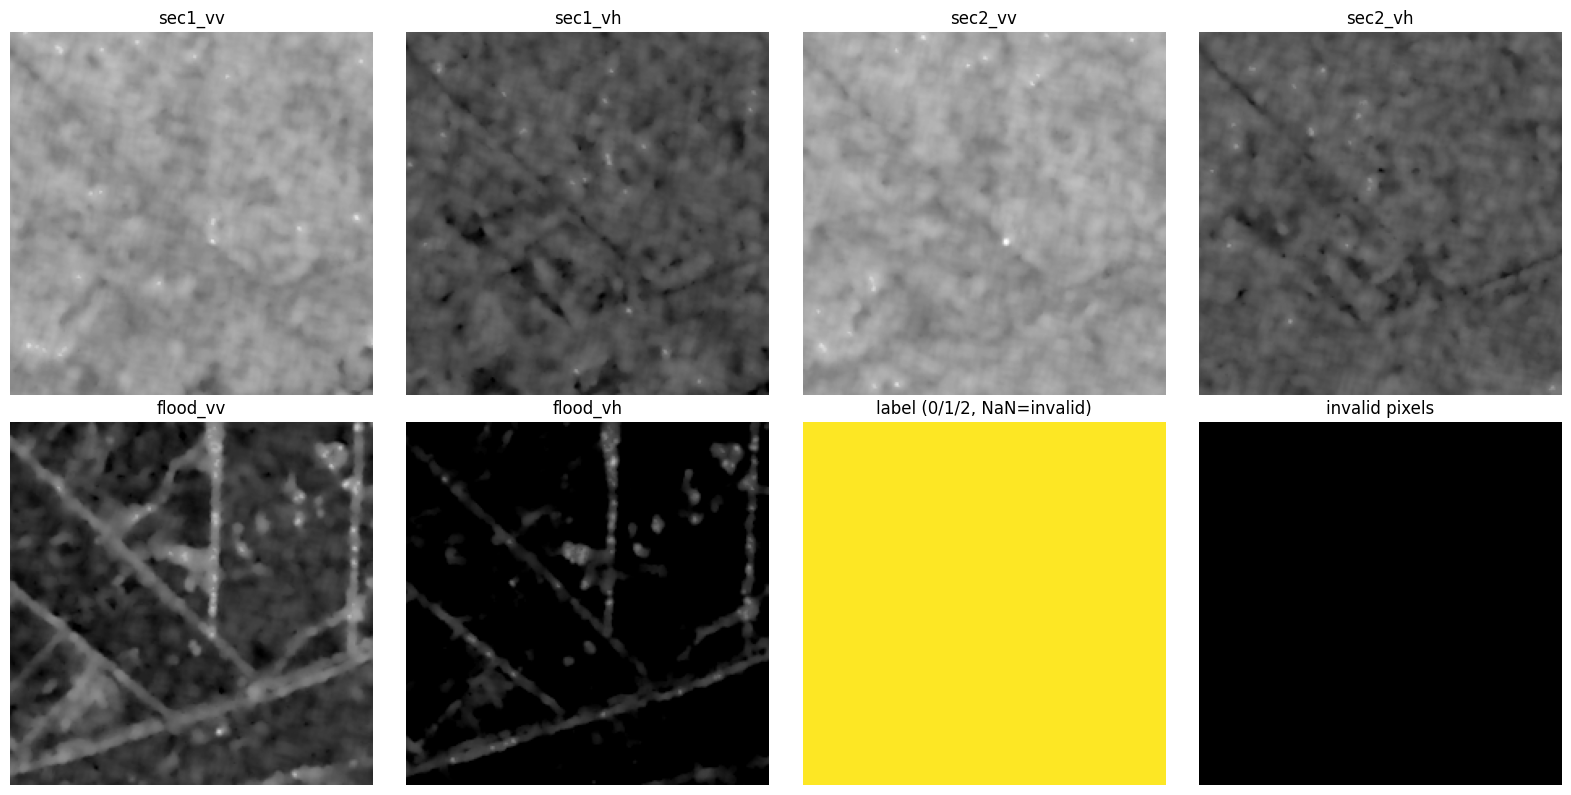

corr(stored flood %, metadata pflood): 1.0
X: (7925, 6, 224, 224) uint8 | Y: (7925, 224, 224) uint8


In [62]:
import matplotlib.pyplot as plt

k = int(np.argmax(manifest[manifest.split == "train"].pflood.to_numpy()))   # a flood-heavy patch
fig, ax = plt.subplots(2, 4, figsize=(16, 8))
for c in range(6):
    ax.flat[c].imshow(Xtr[k, c] * SCALE + DB_MIN, cmap="gray", vmin=-25, vmax=0)
    ax.flat[c].set_title(SAR_FIELDS[c]); ax.flat[c].axis("off")
lab = np.asarray(Ytr[k]).astype(float); lab[lab == IGNORE] = np.nan
ax.flat[6].imshow(lab, cmap="viridis", vmin=0, vmax=2); ax.flat[6].set_title("label (0/1/2, NaN=invalid)"); ax.flat[6].axis("off")
ax.flat[7].imshow(np.asarray(Ytr[k]) == IGNORE, cmap="gray"); ax.flat[7].set_title("invalid pixels"); ax.flat[7].axis("off")
plt.tight_layout(); plt.show()

tr = manifest[manifest.split == "train"]
frac = np.array([(np.asarray(Ytr[i]) == 2).mean() * 100 for i in range(len(Ytr))])
print("corr(stored flood %, metadata pflood):", round(np.corrcoef(frac, tr.pflood.to_numpy())[0, 1], 4))
print("X:", Xtr.shape, Xtr.dtype, "| Y:", Ytr.shape, Ytr.dtype)

## 8. Test set: official `test_GRD` shard(s)
Downloads a test shard, reads its metadata, converts **all** its patches with the same encoding (no cap, no normalization needed yet), and deletes it. Then checks whether its events are disjoint from training/validation events.
Start with one shard (about 10 GB download); add more indices to `TEST_SHARDS` later if you need more test data.

In [63]:
TEST_SHARDS = [0]

for i in TEST_SHARDS:
    split = f"test_{i:02d}"
    if split in done:
        print(split, "already done"); continue
    p = download_shard("test_GRD", i)
    meta = extract_metadata(p, f"{i:05d}")
    meta["split"] = split; meta["row"] = np.arange(len(meta))
    Xt, Yt = open_arrays(split, len(meta))
    wanted = {r.sample_id: (split, r.row) for r in meta.itertuples()}
    preprocess_shard(p, wanted, {split: Xt}, {split: Yt})
    meta.to_csv(PROC / f"manifest_{split}.csv", index=False)
    p.unlink(); gc.collect(); mark_done(split)
    print(f"{split}: {len(meta):,} patches, {meta.actid.nunique()} events")

test_events = set()
for f in PROC.glob("manifest_test_*.csv"):
    test_events |= set(pd.read_csv(f)["actid"].unique())
print("Test events:", sorted(test_events))
print("Overlap with train/val events:", sorted(test_events & set(df2.actid.unique())) or "none")

test_00 already done
Test events: [np.int64(118), np.int64(130), np.int64(147), np.int64(174), np.int64(205), np.int64(267), np.int64(273), np.int64(275), np.int64(277)]
Overlap with train/val events: none


### Test-set check (result)
Test shard 0: 6,000 patches, 9 events (118, 130, 147, 174, 205, 267, 273, 275, 277), **none** shared with training/validation. The official test split is event-disjoint, so it is our test set. It is used only for final reporting.

## 9. Dataset and DataLoader
Reads the stored uint8 arrays, converts back to dB, and standardizes with the training statistics (`normalize=True`). `normalize=False` returns raw dB (used by the change-detection baseline).
Each item: `x` (6,224,224) float32, `target` (224,224) float32 (flood = 1), `valid` (224,224) bool.
Augmentation (training only): random horizontal flip, vertical flip and 90-degree rotation, applied identically to image and label.

In [64]:
from torch.utils.data import Dataset, DataLoader

NORM = json.loads((PROC / "norm_stats.json").read_text())
MEAN = np.array(NORM["mean_db"], dtype=np.float32)[:, None, None]
STD  = np.array(NORM["std_db"],  dtype=np.float32)[:, None, None]

class FloodDataset(Dataset):
    def __init__(self, split, augment=False, normalize=True):
        self.split, self.augment, self.normalize = split, augment, normalize
        self.X = self.Y = None                                   # opened lazily (per worker)
        man = (pd.read_csv(PROC / "manifest_trainval.csv", dtype={"sample_id": str, "shard": str})
               if split in ("train", "val")
               else pd.read_csv(PROC / f"manifest_{split}.csv", dtype={"sample_id": str, "shard": str}))
        self.meta = man[man["split"] == split].sort_values("row").reset_index(drop=True)
        self.actid = self.meta["actid"].to_numpy()

    def __len__(self):
        return len(self.meta)

    def __getitem__(self, i):
        if self.X is None:
            self.X = np.load(PROC / f"X_{self.split}.npy", mmap_mode="r")
            self.Y = np.load(PROC / f"Y_{self.split}.npy", mmap_mode="r")
        x = np.asarray(self.X[i]).astype(np.float32) * SCALE + DB_MIN          # dB
        if self.normalize:
            x = (x - MEAN) / STD
        lab = np.asarray(self.Y[i])
        target = (lab == 2).astype(np.float32)
        valid = lab != IGNORE
        if self.augment:
            if random.random() < 0.5: x, target, valid = x[:, :, ::-1], target[:, ::-1], valid[:, ::-1]
            if random.random() < 0.5: x, target, valid = x[:, ::-1], target[::-1], valid[::-1]
            k = random.randint(0, 3)
            if k: x, target, valid = np.rot90(x, k, (1, 2)), np.rot90(target, k), np.rot90(valid, k)
        return (torch.from_numpy(np.ascontiguousarray(x)),
                torch.from_numpy(np.ascontiguousarray(target)),
                torch.from_numpy(np.ascontiguousarray(valid)))

def make_loader(split, batch_size=16, augment=False, normalize=True, shuffle=False, workers=2):
    return DataLoader(FloodDataset(split, augment, normalize), batch_size=batch_size, shuffle=shuffle,
                      num_workers=workers, pin_memory=True, drop_last=False,
                      persistent_workers=workers > 0)

ds = FloodDataset("train", augment=True)
x, t, v = ds[0]
print(len(ds), x.shape, x.dtype, t.shape, v.dtype, "| flood px:", int(t.sum()), "| invalid px:", int((~v).sum()))
print("per-channel mean/std of this sample (should be roughly 0 / 1):", x.mean((1, 2)).numpy().round(2), x.std((1, 2)).numpy().round(2))

7925 torch.Size([6, 224, 224]) torch.float32 torch.Size([224, 224]) torch.bool | flood px: 879 | invalid px: 0
per-channel mean/std of this sample (should be roughly 0 / 1): [-0.41 -0.6  -0.39 -0.66  0.17  0.3 ] [0.37 0.46 0.37 0.44 0.35 0.36]


## 10. Metrics
Pooled over **valid** pixels (flood = positive class): IoU, F1, precision, recall. Counts are accumulated across all patches (not averaged per patch), and also per event.

In [65]:
def metrics_from_counts(tp, fp, fn, tn):
    tp, fp, fn, tn = map(float, (tp, fp, fn, tn))
    return {"IoU": tp / max(tp + fp + fn, 1), "F1": 2 * tp / max(2 * tp + fp + fn, 1),
            "precision": tp / max(tp + fp, 1), "recall": tp / max(tp + fn, 1)}

def evaluate(predict_fn, loader, threshold=0.5):
    """predict_fn(x) -> flood probability (B,H,W). Returns (pooled metrics dict, per-event DataFrame)."""
    actid = loader.dataset.actid
    per_event, tot, i = {}, np.zeros(4), 0
    for x, t, v in loader:
        pred = predict_fn(x.to(DEVICE, non_blocking=True)).detach().cpu() > threshold
        t, v = t.bool(), v.bool()
        for j in range(len(x)):
            vj, pj, tj = v[j], pred[j], t[j]
            c = np.array([(pj & tj & vj).sum(), (pj & ~tj & vj).sum(), (~pj & tj & vj).sum(), (~pj & ~tj & vj).sum()], dtype=np.float64)
            per_event.setdefault(int(actid[i + j]), np.zeros(4))
            per_event[int(actid[i + j])] += c; tot += c
        i += len(x)
    rows = [{"actid": e, "patches": int((actid == e).sum()), **metrics_from_counts(*c)} for e, c in sorted(per_event.items())]
    return metrics_from_counts(*tot), pd.DataFrame(rows)

def show(name, pooled, per_event=None):
    print(f"{name}: " + " | ".join(f"{k} {v:.4f}" for k, v in pooled.items()))
    if per_event is not None:
        display(per_event.round(4))

## 11. Baseline 1: change detection (no learning)
Flood water lowers radar backscatter, so a simple rule is: flag a pixel as flood if the post-event dB is much lower than the pre-event dB.
Feature candidates (all in dB): `vv_change = post_VV - mean(pre_VV)`, `vh_change`, `vv_vh_change` (average of both), and `post_vv_only` (no pre-event information; shows what temporal information adds).
The single threshold is chosen on the **training** set (maximum IoU), then applied unchanged to validation and test.

In [66]:
def feature(name, x):
    """x: (B,6,H,W) raw dB tensor -> (B,H,W) feature; flood if feature < threshold."""
    s1v, s1h, s2v, s2h, fv, fh = (x[:, i] for i in range(6))
    if name == "vv_change":    return fv - (s1v + s2v) / 2
    if name == "vh_change":    return fh - (s1h + s2h) / 2
    if name == "vv_vh_change": return ((fv - (s1v + s2v) / 2) + (fh - (s1h + s2h) / 2)) / 2
    if name == "post_vv_only": return fv
    raise ValueError(name)

FEATURES = ["vv_change", "vh_change", "vv_vh_change", "post_vv_only"]
EDGES = np.arange(-60, 40.01, 0.1)

def fit_threshold(loader, name):
    pos, neg = np.zeros(len(EDGES) - 1), np.zeros(len(EDGES) - 1)
    for x, t, v in loader:
        f = feature(name, x).clamp(EDGES[0], EDGES[-1] - 1e-3)
        v, t = v.bool(), t.bool()
        pos += np.histogram(f[v & t].numpy(), EDGES)[0]
        neg += np.histogram(f[v & ~t].numpy(), EDGES)[0]
    tp, fp = np.cumsum(pos), np.cumsum(neg)               # predict flood if feature < upper bin edge
    fn = pos.sum() - tp
    iou = tp / np.maximum(tp + fp + fn, 1)
    b = int(np.argmax(iou))
    return float(EDGES[b + 1]), float(iou[b])

train_raw = make_loader("train", batch_size=32, normalize=False, workers=2)
thresholds = {}
for name in FEATURES:
    thr, iou = fit_threshold(train_raw, name)
    thresholds[name] = thr
    print(f"{name:14s} best threshold {thr:6.1f} dB | train IoU {iou:.4f}")

vv_change      best threshold   -3.0 dB | train IoU 0.6349
vh_change      best threshold   -3.1 dB | train IoU 0.5609
vv_vh_change   best threshold   -2.9 dB | train IoU 0.6387
post_vv_only   best threshold  -14.0 dB | train IoU 0.5728


In [67]:
val_raw  = make_loader("val",     batch_size=32, normalize=False, workers=2)
test_raw = make_loader("test_00", batch_size=32, normalize=False, workers=2)

baseline_results = {}
for name in FEATURES:
    fn = lambda x, n=name: (feature(n, x) < thresholds[n]).float()
    pv, _ = evaluate(fn, val_raw)
    pt, pe = evaluate(fn, test_raw)
    baseline_results[name] = {"val": pv, "test": pt, "test_per_event": pe}

summary = pd.DataFrame({f"{n}_{s}": r[s] for n, r in baseline_results.items() for s in ("val", "test")}).T
display(summary.round(4))

BEST_BASELINE = summary.filter(like="_val", axis=0)["IoU"].idxmax().replace("_val", "")
print("Best baseline on validation:", BEST_BASELINE)
display(baseline_results[BEST_BASELINE]["test_per_event"].round(4))
pd.DataFrame(summary).to_csv(ROOT / "results" / "baseline_change_detection.csv")

,IoU,F1,precision,recall
vv_change_val,0.5758,0.7308,0.6810,0.7884
vv_change_test,0.5244,0.6880,0.5825,0.8403
vh_change_val,0.5220,0.6859,0.5927,0.8140
vh_change_test,0.4848,0.6531,0.5137,0.8962
vv_vh_change_val,0.5757,0.7307,0.6634,0.8132
vv_vh_change_test,0.5475,0.7076,0.5873,0.8900
post_vv_only_val,0.4800,0.6487,0.5787,0.7380
post_vv_only_test,0.3109,0.4743,0.3280,0.8561


Best baseline on validation: vv_change


,actid,patches,IoU,F1,precision,recall
0,118,342,0.1403,0.2461,0.1895,0.3507
1,130,373,0.8565,0.9227,0.9365,0.9093
2,147,1958,0.1491,0.2595,0.1848,0.4358
3,174,120,0.1775,0.3014,0.1957,0.6559
4,205,130,0.4673,0.6370,0.6662,0.6102
5,267,504,0.3632,0.5329,0.3815,0.8836
6,273,256,0.1951,0.3264,0.2093,0.7415
7,275,1356,0.6499,0.7878,0.7688,0.8079
8,277,961,0.4101,0.5816,0.4238,0.9267


## 12. Baseline 2: conventional U-Net (early fusion, 6 channels)
Standard 4-level U-Net on the six stacked channels. Loss = BCE + Dice computed on **valid pixels only**. AdamW, cosine learning-rate schedule, mixed precision. The checkpoint with the best **validation IoU** is kept.
The training function is model-agnostic, so the Multi-Temporal Attention U-Net can reuse it unchanged.

In [68]:
import torch.nn as nn, torch.nn.functional as F, time

class DoubleConv(nn.Sequential):
    def __init__(self, i, o):
        super().__init__(nn.Conv2d(i, o, 3, padding=1, bias=False), nn.BatchNorm2d(o), nn.ReLU(inplace=True),
                         nn.Conv2d(o, o, 3, padding=1, bias=False), nn.BatchNorm2d(o), nn.ReLU(inplace=True))

class UNet(nn.Module):
    def __init__(self, in_ch=6, base=32):
        super().__init__()
        c = [base, base * 2, base * 4, base * 8, base * 16]
        self.enc = nn.ModuleList([DoubleConv(in_ch, c[0])] + [DoubleConv(c[i], c[i + 1]) for i in range(4)])
        self.up  = nn.ModuleList([nn.ConvTranspose2d(c[i + 1], c[i], 2, stride=2) for i in range(4)])
        self.dec = nn.ModuleList([DoubleConv(c[i] * 2, c[i]) for i in range(4)])
        self.head = nn.Conv2d(c[0], 1, 1)

    def forward(self, x):                       # returns logits (B,H,W)
        skips = []
        for i, e in enumerate(self.enc):
            x = e(x if i == 0 else F.max_pool2d(x, 2)); skips.append(x)
        x = skips.pop()
        for i in reversed(range(4)):
            x = self.dec[i](torch.cat([self.up[i](x), skips.pop()], 1))
        return self.head(x).squeeze(1)

def masked_bce_dice(logits, target, valid, eps=1.0):
    v = valid.float()
    bce = (F.binary_cross_entropy_with_logits(logits, target, reduction="none") * v).sum() / v.sum().clamp(min=1)
    p = torch.sigmoid(logits) * v
    inter = (p * target).sum(); denom = p.sum() + (target * v).sum()
    return bce + 1 - (2 * inter + eps) / (denom + eps)

def train_model(model, name, epochs=20, lr=1e-3, batch_size=16, patience=6):
    model = model.to(DEVICE)
    tr = make_loader("train", batch_size, augment=True, shuffle=True)
    va = make_loader("val", batch_size)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    scaler = torch.amp.GradScaler(enabled=DEVICE.type == "cuda")
    ckpt = ROOT / "checkpoints" / f"{name}.pt"
    best, bad, hist = -1.0, 0, []
    for ep in range(1, epochs + 1):
        model.train(); t0 = time.time(); run = 0.0
        for x, t, v in tr:
            x, t, v = x.to(DEVICE), t.to(DEVICE), v.to(DEVICE)
            opt.zero_grad(set_to_none=True)
            with torch.autocast(DEVICE.type, enabled=DEVICE.type == "cuda"):
                logits = model(x)
            loss = masked_bce_dice(logits.float(), t, v)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            run += loss.item() * len(x)
        sched.step()
        model.eval()
        with torch.no_grad():
            pooled, _ = evaluate(lambda x: torch.sigmoid(model(x)), va)
        hist.append({"epoch": ep, "train_loss": run / len(tr.dataset), **{f"val_{k}": v for k, v in pooled.items()}})
        print(f"[{name}] epoch {ep:02d} | loss {hist[-1]['train_loss']:.4f} | val IoU {pooled['IoU']:.4f} F1 {pooled['F1']:.4f} | {time.time() - t0:.0f}s")
        if pooled["IoU"] > best:
            best, bad = pooled["IoU"], 0
            torch.save(model.state_dict(), ckpt)
        else:
            bad += 1
            if bad >= patience:
                print("early stopping"); break
    pd.DataFrame(hist).to_csv(ROOT / "logs" / f"{name}_history.csv", index=False)
    model.load_state_dict(torch.load(ckpt, map_location=DEVICE))
    return model.eval(), best

def evaluate_model(model, split):
    with torch.no_grad():
        return evaluate(lambda x: torch.sigmoid(model(x)), make_loader(split, 16))

In [69]:
# Model size. Next cell trains; watch the first epoch (time per epoch, loss going down) before leaving it running.
n_params = sum(p.numel() for p in UNet().parameters())
print(f"U-Net parameters: {n_params / 1e6:.2f} M")

U-Net parameters: 7.76 M


In [70]:
unet, best_val_iou = train_model(UNet(in_ch=6, base=32), "unet_6ch", epochs=20)
print("best val IoU:", round(best_val_iou, 4))

[unet_6ch] epoch 01 | loss 0.5600 | val IoU 0.6332 F1 0.7754 | 81s
[unet_6ch] epoch 02 | loss 0.4127 | val IoU 0.6630 F1 0.7973 | 81s
[unet_6ch] epoch 03 | loss 0.3821 | val IoU 0.6739 F1 0.8052 | 81s
[unet_6ch] epoch 04 | loss 0.3593 | val IoU 0.6584 F1 0.7940 | 81s
[unet_6ch] epoch 05 | loss 0.3477 | val IoU 0.6557 F1 0.7921 | 81s
[unet_6ch] epoch 06 | loss 0.3326 | val IoU 0.6650 F1 0.7988 | 81s
[unet_6ch] epoch 07 | loss 0.3311 | val IoU 0.6667 F1 0.8000 | 81s
[unet_6ch] epoch 08 | loss 0.3230 | val IoU 0.6491 F1 0.7872 | 81s
[unet_6ch] epoch 09 | loss 0.3100 | val IoU 0.6355 F1 0.7772 | 81s
early stopping
best val IoU: 0.6739


In [71]:
unet_val, _ = evaluate_model(unet, "val")
unet_test, unet_test_events = evaluate_model(unet, "test_00")
show("U-Net  val ", unet_val)
show("U-Net  test", unet_test, unet_test_events)
pd.DataFrame({"val": unet_val, "test": unet_test}).T.to_csv(ROOT / "results" / "unet_6ch.csv")

U-Net  val : IoU 0.6739 | F1 0.8052 | precision 0.8357 | recall 0.7769
U-Net  test: IoU 0.6613 | F1 0.7961 | precision 0.7304 | recall 0.8748


,actid,patches,IoU,F1,precision,recall
0,118,342,0.2236,0.3655,0.3125,0.4400
1,130,373,0.8733,0.9324,0.9417,0.9233
2,147,1958,0.4072,0.5788,0.7088,0.4891
3,174,120,0.6118,0.7591,0.9543,0.6302
4,205,130,0.4335,0.6048,0.8895,0.4582
5,267,504,0.4085,0.5800,0.4179,0.9475
6,273,256,0.3975,0.5689,0.4499,0.7732
7,275,1356,0.7552,0.8605,0.8517,0.8695
8,277,961,0.7531,0.8592,0.7946,0.9352


### First-run results (summary)
Baseline (VV change) test IoU 0.524; U-Net (6 channels) val IoU 0.674, test IoU 0.661 (single seed). Test IoU per event ranges from 0.22 to 0.87.
The sections below (1) diagnose where the U-Net fails, (2) fix a training recipe and run several seeds, and (3) test whether using pre-event images helps (channel ablation).
**Policy:** diagnostics may look at test events to *understand* failures, but recipe, threshold and architecture decisions use **validation only**.

## 13. Diagnostics (no training)
First a helper for channel-selectable loaders (also used later). Then the saved U-Net checkpoint is loaded if the model is not already in memory.

In [72]:
class FloodDatasetCh(FloodDataset):
    """FloodDataset with a channel subset (normalization is per channel, so selecting afterwards is equivalent)."""
    def __init__(self, split, channels=range(6), **kw):
        super().__init__(split, **kw)
        self.ch = list(channels)
    def __getitem__(self, i):
        x, t, v = super().__getitem__(i)
        return x[self.ch], t, v

def make_loader2(split, batch_size=16, channels=range(6), augment=False, shuffle=False, workers=2):
    return DataLoader(FloodDatasetCh(split, channels, augment=augment), batch_size=batch_size, shuffle=shuffle,
                      num_workers=workers, pin_memory=DEVICE.type == "cuda", persistent_workers=workers > 0)

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(s)

In [73]:
if "unet" not in globals():
    unet = UNet(in_ch=6, base=32)
    unet.load_state_dict(torch.load(ROOT / "checkpoints" / "unet_6ch.pt", map_location=DEVICE))
    unet = unet.to(DEVICE).eval()

def _gap_days(meta):
    d = lambda c: pd.to_datetime(meta[c], errors="coerce", utc=True)
    return (d("post_date") - d("sl1_date")).dt.days

@torch.no_grad()
def predict_stats(model, split, channels=range(6), batch_size=16, bins=100):
    """Per-patch confusion counts at threshold 0.5, plus probability histograms for a threshold sweep."""
    loader = make_loader2(split, batch_size, channels)
    meta = loader.dataset.meta
    rows, pos, neg = [], np.zeros(bins), np.zeros(bins)
    for x, t, v in loader:
        p = torch.sigmoid(model(x.to(DEVICE))).cpu()
        t, v, pb = t.bool(), v.bool(), p > 0.5
        c = torch.stack([(pb & t & v).flatten(1).sum(1), (pb & ~t & v).flatten(1).sum(1),
                         (~pb & t & v).flatten(1).sum(1), v.flatten(1).sum(1)], 1).numpy()
        rows.append(c)
        idx = (p.clamp(0, 1 - 1e-6) * bins).long()
        pos += torch.bincount(idx[v & t], minlength=bins).numpy()
        neg += torch.bincount(idx[v & ~t], minlength=bins).numpy()
    c = np.concatenate(rows)
    df_ = pd.DataFrame({"actid": meta["actid"].to_numpy(), "gap_days": _gap_days(meta).to_numpy(),
                        "tp": c[:, 0], "fp": c[:, 1], "fn": c[:, 2], "valid_px": c[:, 3]})
    df_["flood_frac_%"] = (df_["tp"] + df_["fn"]) / df_["valid_px"].clip(lower=1) * 100
    return df_, pos, neg

def group_metrics(df_, by):
    g = df_.groupby(by, observed=True)[["tp", "fp", "fn"]].sum()
    out = pd.DataFrame([metrics_from_counts(r.tp, r.fp, r.fn, 0) for r in g.itertuples()], index=g.index)
    out.insert(0, "patches", df_.groupby(by, observed=True).size())
    return out

val_df,  val_pos,  val_neg  = predict_stats(unet, "val")
test_df, test_pos, test_neg = predict_stats(unet, "test_00")
val_df["family"] = np.where(val_df.actid >= 1111000, "1111xxx", "EMSR")
print("Validation per event (U-Net, threshold 0.5):"); display(group_metrics(val_df, "actid").round(3))
print("Validation per family:");                       display(group_metrics(val_df, "family").round(3))

Validation per event (U-Net, threshold 0.5):


,patches,IoU,F1,precision,recall
actid,,,,,
555,684,0.489,0.656,0.779,0.567
1111007,1500,0.601,0.750,0.902,0.642
1111011,1500,0.758,0.862,0.803,0.932


Validation per family:


,patches,IoU,F1,precision,recall
family,,,,,
1111xxx,3000,0.688,0.815,0.839,0.792
EMSR,684,0.489,0.656,0.779,0.567


In [74]:
# Does performance depend on the pre->post time gap, or on how much flood a patch contains?
gap_bins   = [0, 15, 30, 60, 100000]
flood_bins = [-1, 0, 5, 20, 100]
flood_lbl  = ["no flood", "0-5 %", "5-20 %", ">20 %"]
for name, d in [("VALIDATION", val_df), ("TEST", test_df)]:
    d = d.copy()
    d["gap_bin"]   = pd.cut(d["gap_days"], gap_bins)
    d["flood_bin"] = pd.cut(d["flood_frac_%"], flood_bins, labels=flood_lbl)
    print(f"\n{name}: IoU by pre->post gap (days)");        display(group_metrics(d, "gap_bin").round(3))
    print(f"{name}: by flood fraction of the patch");         display(group_metrics(d, "flood_bin").round(3))
    nf = d[d["flood_bin"] == "no flood"]
    print(f"{name}: patches with no flood: {len(nf)} | mean false-positive pixels per such patch: {nf.fp.mean():.0f}")


VALIDATION: IoU by pre->post gap (days)


,patches,IoU,F1,precision,recall
gap_bin,,,,,
"(0, 15]",1500,0.758,0.862,0.803,0.932
"(30, 60]",1500,0.601,0.750,0.902,0.642
"(60, 100000]",684,0.489,0.656,0.779,0.567


VALIDATION: by flood fraction of the patch


,patches,IoU,F1,precision,recall
flood_bin,,,,,
no flood,1007,0.000,0.000,0.000,0.000
0-5 %,1373,0.348,0.516,0.538,0.496
5-20 %,649,0.492,0.659,0.707,0.617
>20 %,655,0.750,0.857,0.887,0.830


VALIDATION: patches with no flood: 1007 | mean false-positive pixels per such patch: 97

TEST: IoU by pre->post gap (days)


,patches,IoU,F1,precision,recall
gap_bin,,,,,
"(60, 100000]",6000,0.661,0.796,0.73,0.875


TEST: by flood fraction of the patch


,patches,IoU,F1,precision,recall
flood_bin,,,,,
no flood,4140,0.000,0.000,0.000,0.000
0-5 %,779,0.297,0.458,0.397,0.542
5-20 %,504,0.570,0.726,0.686,0.771
>20 %,577,0.818,0.900,0.892,0.908


TEST: patches with no flood: 4140 | mean false-positive pixels per such patch: 691


In [75]:
# Probability-threshold sweep on VALIDATION (only change the 0.5 default if the gain is clear and not tiny).
def sweep(pos, neg):
    tp = np.cumsum(pos[::-1])[::-1]; fp = np.cumsum(neg[::-1])[::-1]; fn = pos.sum() - tp
    thr = np.arange(len(pos)) / len(pos)
    return pd.DataFrame({"threshold": thr, "IoU": tp / np.maximum(tp + fp + fn, 1),
                         "precision": tp / np.maximum(tp + fp, 1), "recall": tp / np.maximum(tp + fn, 1)})

sw = sweep(val_pos, val_neg)
print("Validation IoU at selected thresholds:")
display(sw[sw.threshold.round(2).isin([0.3, 0.4, 0.5, 0.6, 0.7])].round(4))
best = sw.loc[sw.IoU.idxmax()]
print(f"Best validation threshold: {best.threshold:.2f} (IoU {best.IoU:.4f}) vs 0.50 (IoU {sw.loc[50, 'IoU']:.4f})")

Validation IoU at selected thresholds:


,threshold,IoU,precision,recall
30,0.3,0.6723,0.8015,0.8066
40,0.4,0.6750,0.8212,0.7913
50,0.5,0.6739,0.8357,0.7769
60,0.6,0.6707,0.8493,0.7614
70,0.7,0.6644,0.8635,0.7425


Best validation threshold: 0.41 (IoU 0.6750) vs 0.50 (IoU 0.6739)


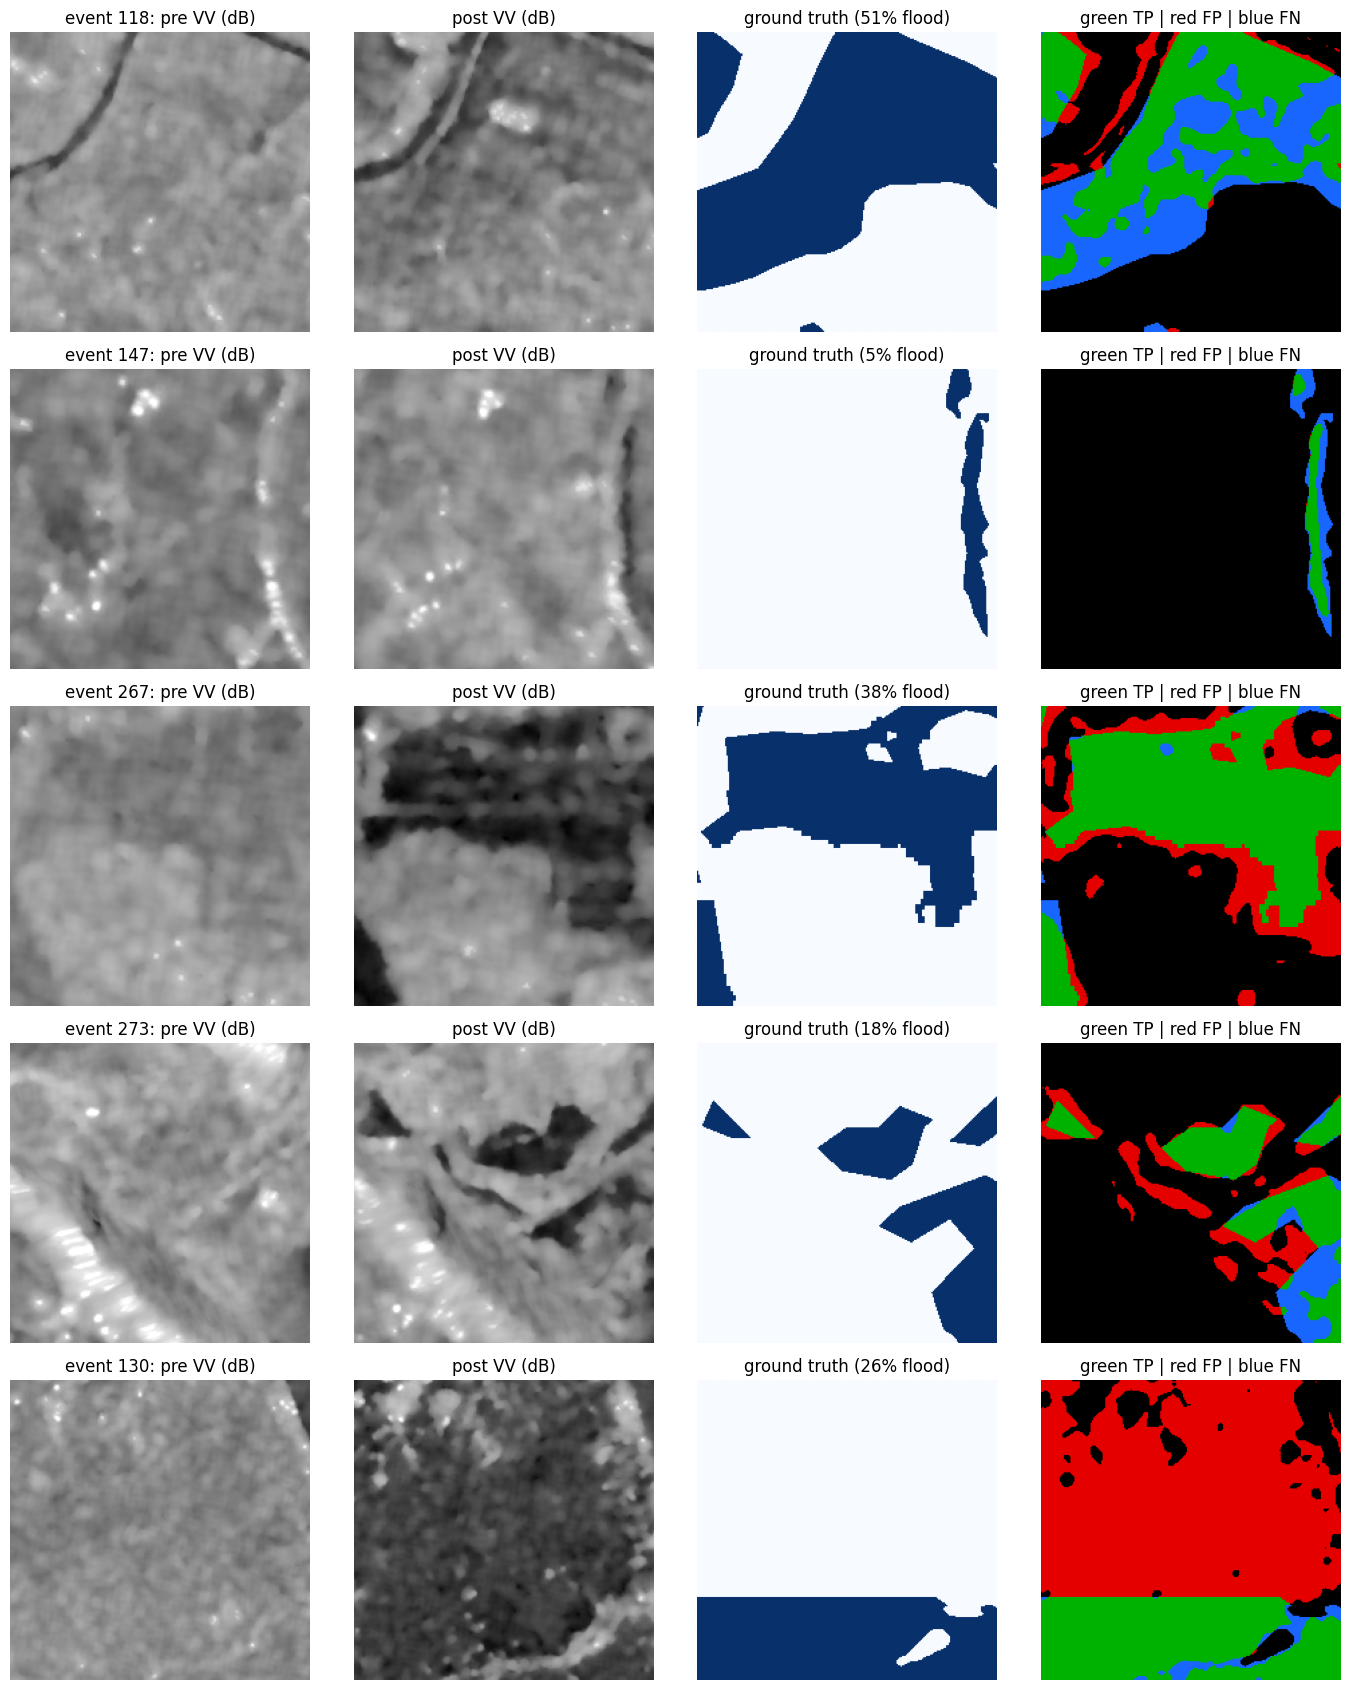

In [76]:
import matplotlib.pyplot as plt

@torch.no_grad()
def show_predictions(model, split, events, seed=0, lo=5, hi=60):
    """One flood-containing patch per event: first pre-event VV, post-event VV, ground truth, error map."""
    rs = np.random.default_rng(seed)
    ds = FloodDataset(split)
    fig, ax = plt.subplots(len(events), 4, figsize=(14, 3.4 * len(events)), squeeze=False)
    for r, ev in enumerate(events):
        cand = rs.permutation(np.where(ds.actid == ev)[0])
        if len(cand) == 0:
            print(f"event {ev} not found in {split}"); [a.axis("off") for a in ax[r]]; continue
        pick = None
        for i in cand[:80]:
            x, t, v = ds[int(i)]
            f = float((t.bool() & v).sum() / v.sum().clamp(min=1) * 100)
            if lo <= f <= hi: pick = (int(i), x, t, v, f); break
        if pick is None:
            pick = (int(cand[0]),) + tuple(ds[int(cand[0])]) + (float("nan"),)
        i, x, t, v, f = pick
        pred = (torch.sigmoid(model(x[None].to(DEVICE)))[0].cpu() > 0.5)
        tb, vb = t.bool(), v.bool()
        db = x.numpy() * STD + MEAN
        err = np.zeros((224, 224, 3)); err[~vb.numpy()] = 0.35
        err[(pred & tb & vb).numpy()] = (0, 0.7, 0); err[(pred & ~tb & vb).numpy()] = (0.9, 0, 0); err[(~pred & tb & vb).numpy()] = (0.1, 0.4, 1)
        ax[r, 0].imshow(db[0], cmap="gray", vmin=-25, vmax=0); ax[r, 0].set_title(f"event {ev}: pre VV (dB)")
        ax[r, 1].imshow(db[4], cmap="gray", vmin=-25, vmax=0); ax[r, 1].set_title("post VV (dB)")
        ax[r, 2].imshow(np.where(vb, tb, np.nan), cmap="Blues", vmin=0, vmax=1); ax[r, 2].set_title(f"ground truth ({f:.0f}% flood)")
        ax[r, 3].imshow(err); ax[r, 3].set_title("green TP | red FP | blue FN")
        for a in ax[r]: a.axis("off")
    plt.tight_layout(); plt.show()

show_predictions(unet, "test_00", events=[118, 147, 267, 273, 130])     # weak events and the best one

## 14. Training recipe, seeds and channel selection
New training function with: a cosine schedule that **ends** at the last epoch, a seed per run, selectable input channels, and results saved per run (`results/<run>.json`) so an interrupted session can resume.
Test data is **not** touched here; only validation is evaluated. Final test numbers come later from the saved checkpoints on a fresh test shard.

In [77]:
def evaluate_model2(model, split, channels):
    with torch.no_grad():
        return evaluate(lambda x: torch.sigmoid(model(x)), make_loader2(split, 16, channels))

def train_model2(model, run, channels, epochs, lr, batch_size=16, patience=5, weight_decay=1e-4):
    model = model.to(DEVICE)
    tr = make_loader2("train", batch_size, channels, augment=True, shuffle=True)
    va = make_loader2("val", batch_size, channels)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    scaler = torch.amp.GradScaler(enabled=DEVICE.type == "cuda")
    ckpt = ROOT / "checkpoints" / f"{run}.pt"
    best, best_ep, bad, hist = -1.0, 0, 0, []
    for ep in range(1, epochs + 1):
        model.train(); t0 = time.time(); run_loss = 0.0
        for x, t, v in tr:
            x, t, v = x.to(DEVICE), t.to(DEVICE), v.to(DEVICE)
            opt.zero_grad(set_to_none=True)
            with torch.autocast(DEVICE.type, enabled=DEVICE.type == "cuda"):
                logits = model(x)
            loss = masked_bce_dice(logits.float(), t, v)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            run_loss += loss.item() * len(x)
        sched.step(); model.eval()
        with torch.no_grad():
            pooled, _ = evaluate(lambda x: torch.sigmoid(model(x)), va)
        hist.append({"epoch": ep, "train_loss": run_loss / len(tr.dataset), **{f"val_{k}": val for k, val in pooled.items()}})
        print(f"[{run}] ep {ep:02d} | loss {hist[-1]['train_loss']:.4f} | val IoU {pooled['IoU']:.4f} | {time.time() - t0:.0f}s")
        if pooled["IoU"] > best:
            best, best_ep, bad = pooled["IoU"], ep, 0
            torch.save(model.state_dict(), ckpt)
        else:
            bad += 1
            if bad >= patience:
                print("early stopping"); break
    pd.DataFrame(hist).to_csv(ROOT / "logs" / f"{run}_history.csv", index=False)
    model.load_state_dict(torch.load(ckpt, map_location=DEVICE))
    del tr, va; gc.collect()
    return model.eval(), {"best_val_iou": best, "best_epoch": best_ep, "epochs_run": len(hist)}

def run_experiment(name, channels, seeds, epochs, lr, base=32, model_fn=None):
    """Train one model per seed (skipping finished runs); results saved to results/<name>_s<seed>.json."""
    for s in seeds:
        run = f"{name}_s{s}"
        out = ROOT / "results" / f"{run}.json"
        if out.exists():
            print(run, "already done"); continue
        set_seed(s)
        model = model_fn(len(channels)) if model_fn else UNet(in_ch=len(channels), base=base)
        model, info = train_model2(model, run, list(channels), epochs, lr)
        pooled, per_event = evaluate_model2(model, "val", list(channels))
        out.write_text(json.dumps({"run": run, "channels": list(channels), "epochs": epochs, "lr": lr,
                                   "params": sum(p.numel() for p in model.parameters()),
                                   **info, "val": pooled, "val_per_event": per_event.to_dict("records")}))
        del model; gc.collect(); torch.cuda.empty_cache()

def summarize(prefixes):
    """Mean +/- sd over seeds of validation metrics, one row per experiment name."""
    rows = []
    for p in prefixes:
        rs = [json.loads(f.read_text()) for f in sorted((ROOT / "results").glob(f"{p}_s*.json"))]
        if not rs:
            continue
        row = {"experiment": p, "seeds": len(rs), "params_M": round(rs[0]["params"] / 1e6, 2),
               "best_epoch": ", ".join(str(r["best_epoch"]) for r in rs)}
        for k in ["IoU", "F1", "precision", "recall"]:
            a = np.array([r["val"][k] for r in rs])
            row[k] = f"{a.mean():.3f} +/- {a.std(ddof=1) if len(a) > 1 else 0:.3f}"
        rows.append(row)
    return pd.DataFrame(rows).set_index("experiment")

### 14a. Compare two training recipes (6 channels, one seed each, about 15 min per run)
Recipe A: learning rate 1e-3, 10 epochs. Recipe B: learning rate 3e-4, 12 epochs. The recipe with the higher **validation** IoU (and smoother curve) is used for everything that follows.

In [78]:
ALL_CH = list(range(6))
RECIPES = {"A": dict(lr=1e-3, epochs=10), "B": dict(lr=3e-4, epochs=12)}

for k, r in RECIPES.items():
    run_experiment(f"recipe{k}_6ch", ALL_CH, seeds=(0,), **r)

display(summarize([f"recipe{k}_6ch" for k in RECIPES]))
for k in RECIPES:
    display(pd.read_csv(ROOT / "logs" / f"recipe{k}_6ch_s0_history.csv").round(4))

[recipeA_6ch_s0] ep 01 | loss 0.5405 | val IoU 0.6614 | 81s
[recipeA_6ch_s0] ep 02 | loss 0.4044 | val IoU 0.6723 | 81s
[recipeA_6ch_s0] ep 03 | loss 0.3778 | val IoU 0.6569 | 81s
[recipeA_6ch_s0] ep 04 | loss 0.3517 | val IoU 0.6688 | 81s
[recipeA_6ch_s0] ep 05 | loss 0.3356 | val IoU 0.6640 | 81s
[recipeA_6ch_s0] ep 06 | loss 0.3276 | val IoU 0.6636 | 81s
[recipeA_6ch_s0] ep 07 | loss 0.3159 | val IoU 0.6637 | 81s
early stopping
[recipeB_6ch_s0] ep 01 | loss 0.7049 | val IoU 0.6522 | 81s
[recipeB_6ch_s0] ep 02 | loss 0.4529 | val IoU 0.6733 | 81s
[recipeB_6ch_s0] ep 03 | loss 0.3845 | val IoU 0.6267 | 81s
[recipeB_6ch_s0] ep 04 | loss 0.3524 | val IoU 0.6603 | 81s
[recipeB_6ch_s0] ep 05 | loss 0.3331 | val IoU 0.6373 | 81s
[recipeB_6ch_s0] ep 06 | loss 0.3192 | val IoU 0.6737 | 81s
[recipeB_6ch_s0] ep 07 | loss 0.3041 | val IoU 0.6708 | 81s
[recipeB_6ch_s0] ep 08 | loss 0.2938 | val IoU 0.6209 | 81s
[recipeB_6ch_s0] ep 09 | loss 0.2771 | val IoU 0.6250 | 81s
[recipeB_6ch_s0] ep 10 | 

,seeds,params_M,best_epoch,IoU,F1,precision,recall
experiment,,,,,,,
recipeA_6ch,1,7.76,2,0.672 +/- 0.000,0.804 +/- 0.000,0.834 +/- 0.000,0.777 +/- 0.000
recipeB_6ch,1,7.76,6,0.674 +/- 0.000,0.805 +/- 0.000,0.802 +/- 0.000,0.808 +/- 0.000


,epoch,train_loss,val_IoU,val_F1,val_precision,val_recall
0,1,0.5405,0.6614,0.7962,0.8026,0.7899
1,2,0.4044,0.6723,0.8040,0.8336,0.7765
2,3,0.3778,0.6569,0.7929,0.8487,0.7440
3,4,0.3517,0.6688,0.8015,0.8147,0.7888
4,5,0.3356,0.6640,0.7981,0.7916,0.8047
5,6,0.3276,0.6636,0.7978,0.7823,0.8139
6,7,0.3159,0.6637,0.7979,0.8260,0.7716


,epoch,train_loss,val_IoU,val_F1,val_precision,val_recall
0,1,0.7049,0.6522,0.7895,0.7488,0.8348
1,2,0.4529,0.6733,0.8047,0.8274,0.7833
2,3,0.3845,0.6267,0.7705,0.7699,0.7711
3,4,0.3524,0.6603,0.7954,0.7772,0.8145
4,5,0.3331,0.6373,0.7784,0.7246,0.8409
5,6,0.3192,0.6737,0.8050,0.8019,0.8082
6,7,0.3041,0.6708,0.8030,0.8310,0.7767
7,8,0.2938,0.6209,0.7661,0.7169,0.8226
8,9,0.2771,0.6250,0.7692,0.7407,0.8001
9,10,0.2708,0.6427,0.7825,0.7591,0.8073


In [79]:
res = summarize([f"recipe{k}_6ch" for k in RECIPES])
best_key = max(RECIPES, key=lambda k: json.loads((ROOT / "results" / f"recipe{k}_6ch_s0.json").read_text())["best_val_iou"])
RECIPE = RECIPES[best_key]          # <- override by hand if the curves tell a different story
print("Recipe used from now on:", best_key, RECIPE)

Recipe used from now on: B {'lr': 0.0003, 'epochs': 12}


## 15. Channel ablation: does pre-event information help?
Same U-Net and recipe, three input sets, 3 seeds each (9 runs, roughly 2-2.5 hours in total; finished runs are skipped, so the cell can be re-run after an interruption).
- `post2`: post-event VV, VH only.
- `pre1_post4`: the pre-event image closer in time to the flood, plus post-event.
- `all6`: both pre-event images plus post-event.

In [80]:
m = pd.read_csv(PROC / "manifest_trainval.csv")
d = lambda c: pd.to_datetime(m[c], errors="coerce", utc=True)
g1, g2 = (d("post_date") - d("sl1_date")).dt.days.median(), (d("post_date") - d("sl2_date")).dt.days.median()
closer = [2, 3] if (pd.notna(g2) and g2 < g1) else [0, 1]
print(f"median days pre->post: SL1 {g1}, SL2 {g2} -> closer pre-event image = {'sec2' if closer == [2, 3] else 'sec1'}")

CONFIGS = {"post2": [4, 5], "pre1_post4": closer + [4, 5], "all6": ALL_CH}
for name, ch in CONFIGS.items():
    run_experiment(f"abl_{name}", ch, seeds=(0, 1, 2), **RECIPE)

ablation = summarize([f"abl_{n}" for n in CONFIGS])
display(ablation)
ablation.to_csv(ROOT / "results" / "ablation_channels_val.csv")

median days pre->post: SL1 36.0, SL2 60.0 -> closer pre-event image = sec1
[abl_post2_s0] ep 01 | loss 0.9031 | val IoU 0.5206 | 80s
[abl_post2_s0] ep 02 | loss 0.6320 | val IoU 0.5044 | 80s
[abl_post2_s0] ep 03 | loss 0.5601 | val IoU 0.5089 | 80s
[abl_post2_s0] ep 04 | loss 0.5294 | val IoU 0.5125 | 80s
[abl_post2_s0] ep 05 | loss 0.5203 | val IoU 0.5180 | 80s
[abl_post2_s0] ep 06 | loss 0.5019 | val IoU 0.5294 | 80s
[abl_post2_s0] ep 07 | loss 0.4933 | val IoU 0.5191 | 80s
[abl_post2_s0] ep 08 | loss 0.4858 | val IoU 0.5175 | 80s
[abl_post2_s0] ep 09 | loss 0.4811 | val IoU 0.5203 | 80s
[abl_post2_s0] ep 10 | loss 0.4722 | val IoU 0.5179 | 80s
[abl_post2_s0] ep 11 | loss 0.4701 | val IoU 0.5219 | 80s
early stopping
[abl_post2_s1] ep 01 | loss 0.8304 | val IoU 0.5096 | 80s
[abl_post2_s1] ep 02 | loss 0.6083 | val IoU 0.5126 | 80s
[abl_post2_s1] ep 03 | loss 0.5517 | val IoU 0.5162 | 80s
[abl_post2_s1] ep 04 | loss 0.5247 | val IoU 0.5080 | 80s
[abl_post2_s1] ep 05 | loss 0.5136 | val

,seeds,params_M,best_epoch,IoU,F1,precision,recall
experiment,,,,,,,
abl_post2,3,7.76,"6, 9, 12",0.532 +/- 0.003,0.695 +/- 0.002,0.639 +/- 0.013,0.762 +/- 0.014
abl_pre1_post4,3,7.76,"8, 3, 5",0.684 +/- 0.008,0.812 +/- 0.006,0.816 +/- 0.009,0.809 +/- 0.002
abl_all6,3,7.76,"6, 1, 8",0.668 +/- 0.005,0.801 +/- 0.003,0.793 +/- 0.015,0.810 +/- 0.013


In [81]:
# ============================================================
# NEXT: (1) test-vs-train distribution check
#       (2) Multi-Temporal U-Nets: "mt_diff" (no attention) and "mt_attn" (temporal attention + attention gates)
#       (3) train both with the fixed recipe, 3 seeds, and compare with the earlier ablation (validation only)
# ============================================================
import math

# ---------------------------------------------------------------- 1. distribution check
def _gap(m):
    d = lambda c: pd.to_datetime(m[c], errors="coerce", utc=True)
    return (d("post_date") - d("sl1_date")).dt.days

_man = pd.read_csv(PROC / "manifest_trainval.csv", dtype={"sample_id": str, "shard": str})
_test = pd.read_csv(PROC / "manifest_test_00.csv", dtype={"sample_id": str, "shard": str})
_parts = {"train": _man[_man.split == "train"], "val": _man[_man.split == "val"], "test": _test}

rows = []
for k, mm in _parts.items():
    g = _gap(mm)
    rows.append({"split": k, "patches": len(mm), "events": mm.actid.nunique(),
                 "no_flood_%": round((mm.pflood == 0).mean() * 100, 1), "mean_flood_%": round(mm.pflood.mean(), 1),
                 "gap_median_d": g.median(), "gap_p10": g.quantile(.1), "gap_p90": g.quantile(.9),
                 "gap>60d_%": round((g > 60).mean() * 100, 1)})
print("Train vs validation vs test (gap = days from first pre-event image to post-event image):")
display(pd.DataFrame(rows).set_index("split"))

ev = pd.concat([mm.assign(split=k) for k, mm in _parts.items() if k != "train"])
ev["gap"] = _gap(ev)
display(ev.groupby(["split", "actid"]).agg(patches=("pflood", "size"), gap_median=("gap", "median"),
                                           no_flood_pct=("pflood", lambda x: round((x == 0).mean() * 100, 1))))

if all(k in globals() for k in ("val_df", "test_df", "group_metrics")):
    for name, d in [("VALIDATION", val_df), ("TEST", test_df)]:
        empty = d["flood_frac_%"] == 0
        full = metrics_from_counts(d.tp.sum(), d.fp.sum(), d.fn.sum(), 0)["IoU"]
        no_fp = metrics_from_counts(d.tp.sum(), d.fp[~empty].sum(), d.fn.sum(), 0)["IoU"]
        print(f"{name}: IoU {full:.3f} | IoU if empty patches had zero false positives {no_fp:.3f} | "
              f"empty patches give {d.fp[empty].sum() / max(d.fp.sum(), 1) * 100:.0f}% of all false-positive pixels")
    t = test_df.copy(); t["gap_bin"] = pd.cut(t.gap_days, [60, 90, 180, 365, 100000])
    print("TEST: U-Net (6 channels) IoU by pre->post gap:"); display(group_metrics(t, "gap_bin").round(3))

# ---------------------------------------------------------------- 2. models
class AttentionGate(nn.Module):
    """Additive attention gate on a skip connection (Oktay et al., Attention U-Net)."""
    def __init__(self, g_ch, x_ch, inter):
        super().__init__()
        self.wg  = nn.Sequential(nn.Conv2d(g_ch, inter, 1, bias=False), nn.BatchNorm2d(inter))
        self.wx  = nn.Sequential(nn.Conv2d(x_ch, inter, 1, bias=False), nn.BatchNorm2d(inter))
        self.psi = nn.Sequential(nn.Conv2d(inter, 1, 1), nn.BatchNorm2d(1), nn.Sigmoid())
    def forward(self, g, x):                                   # g: upsampled decoder features, x: skip features
        return x * self.psi(F.relu(self.wg(g) + self.wx(x)))

class TemporalFusion(nn.Module):
    """Fuse per-timestep features f (B,3,C,H,W; order pre1, pre2, post) into one map.
       attention=False: reference = mean of the two pre-event features.
       attention=True : reference = per-pixel softmax-weighted mix of the pre-event features, the weights
                        coming from similarity to the post-event features (the model chooses which pre-event image to trust)."""
    def __init__(self, c, attention):
        super().__init__()
        self.attention = attention
        if attention:
            self.q = nn.Conv2d(c, max(c // 2, 8), 1); self.k = nn.Conv2d(c, max(c // 2, 8), 1)
        self.mix = nn.Sequential(nn.Conv2d(3 * c, c, 1, bias=False), nn.BatchNorm2d(c), nn.ReLU(inplace=True))
    def forward(self, f):
        pre, post = f[:, :2], f[:, 2]
        if self.attention:
            q = self.q(post)
            k = torch.stack([self.k(pre[:, i]) for i in range(2)], 1)
            w = torch.softmax((k * q[:, None]).sum(2, keepdim=True) / math.sqrt(q.shape[1]), dim=1)
            ref = (w * pre).sum(1)
        else:
            ref = pre.mean(1)
        return self.mix(torch.cat([post, post - ref, ref], 1))      # post, change, reference

class MTUNet(nn.Module):
    """Multi-temporal U-Net: ONE encoder shared by the 3 timesteps (2 channels each), temporal fusion at every scale,
       U-Net decoder (with attention gates on the skips if attention=True). Input: (B,6,H,W) in the usual channel order."""
    def __init__(self, base=32, attention=True):
        super().__init__()
        self.attention = attention
        c = [base, base * 2, base * 4, base * 8, base * 16]
        self.enc  = nn.ModuleList([DoubleConv(2, c[0])] + [DoubleConv(c[i], c[i + 1]) for i in range(4)])
        self.fuse = nn.ModuleList([TemporalFusion(ch, attention) for ch in c])
        self.up   = nn.ModuleList([nn.ConvTranspose2d(c[i + 1], c[i], 2, stride=2) for i in range(4)])
        self.gate = nn.ModuleList([AttentionGate(c[i], c[i], max(c[i] // 2, 8)) for i in range(4)]) if attention else None
        self.dec  = nn.ModuleList([DoubleConv(c[i] * 2, c[i]) for i in range(4)])
        self.head = nn.Conv2d(c[0], 1, 1)

    def forward(self, x):
        B, _, H, W = x.shape
        h = x.reshape(B, 3, 2, H, W).reshape(B * 3, 2, H, W)         # (pre1, pre2, post) x (VV, VH)
        feats = []
        for i, e in enumerate(self.enc):
            h = e(h if i == 0 else F.max_pool2d(h, 2))
            feats.append(self.fuse[i](h.reshape(B, 3, *h.shape[1:])))
        x = feats.pop()
        for i in reversed(range(4)):
            u, s = self.up[i](x), feats.pop()
            if self.attention:
                s = self.gate[i](u, s)
            x = self.dec[i](torch.cat([u, s], 1))
        return self.head(x).squeeze(1)

MT_BASE = 30                          # ~7.8 M parameters for mt_diff, i.e. the same size as the plain U-Net
for att in (False, True):
    print(f"MTUNet(attention={att}, base={MT_BASE}) parameters: {sum(p.numel() for p in MTUNet(MT_BASE, att).parameters()) / 1e6:.2f} M "
          f"(plain U-Net: 7.76 M)")

# ---------------------------------------------------------------- 3. train (fixed recipe, validation only; resumable)
RECIPE = globals().get("RECIPE", dict(lr=3e-4, epochs=12))
ALL_CH = globals().get("ALL_CH", list(range(6)))
SEEDS = (0, 1, 2)                       # use (0,) for a first quick look; finished runs are skipped on re-run

for name, att in [("mt_diff", False), ("mt_attn", True)]:
    run_experiment(name, ALL_CH, seeds=SEEDS, model_fn=lambda n, a=att: MTUNet(MT_BASE, a), **RECIPE)

NAMES = ["abl_post2", "abl_pre1_post4", "abl_all6", "mt_diff", "mt_attn"]
table = summarize(NAMES)
display(table)
table.to_csv(ROOT / "results" / "model_comparison_val.csv")

def per_event_table(prefixes):
    out = {}
    for p in prefixes:
        rs = [json.loads(f.read_text()) for f in sorted((ROOT / "results").glob(f"{p}_s*.json"))]
        out[p] = pd.DataFrame([{r_["actid"]: r_["IoU"] for r_ in r["val_per_event"]} for r in rs]).mean()
    return pd.DataFrame(out).round(3)
print("Validation IoU per event (mean over seeds):")
display(per_event_table(NAMES))

Train vs validation vs test (gap = days from first pre-event image to post-event image):


,patches,events,no_flood_%,mean_flood_%,gap_median_d,gap_p10,gap_p90,gap>60d_%
split,,,,,,,,
train,7925,22,14.2,15.2,24.0,12.0,108.0,32.3
val,3684,3,27.3,10.8,48.0,12.0,102.0,18.6
test,6000,9,69.0,6.3,168.0,144.0,228.0,100.0


patches  gap_median  no_flood_pct
split actid                                     
test  118          342        96.0          71.9
      130          373       144.0          35.1
      147         1958       168.0          88.3
      174          120       360.0          90.8
      205          130       126.0          48.5
      267          504       156.0          62.7
      273          256       203.0          74.2
      275         1356       228.0          49.3
      277          961       210.0          71.5
val   555          684       102.0          33.9
      1111007     1500        48.0          35.1
      1111011     1500        12.0          16.5

VALIDATION: IoU 0.674 | IoU if empty patches had zero false positives 0.677 | empty patches give 3% of all false-positive pixels
TEST: IoU 0.661 | IoU if empty patches had zero false positives 0.747 | empty patches give 47% of all false-positive pixels
TEST: U-Net (6 channels) IoU by pre->post gap:


,patches,IoU,F1,precision,recall
gap_bin,,,,,
"(60, 90]",168,0.425,0.597,0.821,0.469
"(90, 180]",3139,0.641,0.781,0.695,0.892
"(180, 365]",2693,0.715,0.834,0.792,0.880


MTUNet(attention=False, base=30) parameters: 7.75 M (plain U-Net: 7.76 M)
MTUNet(attention=True, base=30) parameters: 8.13 M (plain U-Net: 7.76 M)
[mt_diff_s0] ep 01 | loss 0.6999 | val IoU 0.6451 | 168s
[mt_diff_s0] ep 02 | loss 0.4368 | val IoU 0.6684 | 167s
[mt_diff_s0] ep 03 | loss 0.3653 | val IoU 0.6524 | 167s
[mt_diff_s0] ep 04 | loss 0.3352 | val IoU 0.6446 | 168s
[mt_diff_s0] ep 05 | loss 0.3131 | val IoU 0.6448 | 167s
[mt_diff_s0] ep 06 | loss 0.2951 | val IoU 0.6245 | 167s
[mt_diff_s0] ep 07 | loss 0.2858 | val IoU 0.6466 | 167s
early stopping
[mt_diff_s1] ep 01 | loss 0.6578 | val IoU 0.6737 | 168s
[mt_diff_s1] ep 02 | loss 0.4156 | val IoU 0.6369 | 167s
[mt_diff_s1] ep 03 | loss 0.3503 | val IoU 0.6669 | 167s
[mt_diff_s1] ep 04 | loss 0.3245 | val IoU 0.6471 | 168s
[mt_diff_s1] ep 05 | loss 0.3073 | val IoU 0.6582 | 167s
[mt_diff_s1] ep 06 | loss 0.2910 | val IoU 0.6504 | 167s
early stopping
[mt_diff_s2] ep 01 | loss 0.7417 | val IoU 0.5656 | 168s
[mt_diff_s2] ep 02 | loss

,seeds,params_M,best_epoch,IoU,F1,precision,recall
experiment,,,,,,,
abl_post2,3,7.76,"6, 9, 12",0.532 +/- 0.003,0.695 +/- 0.002,0.639 +/- 0.013,0.762 +/- 0.014
abl_pre1_post4,3,7.76,"8, 3, 5",0.684 +/- 0.008,0.812 +/- 0.006,0.816 +/- 0.009,0.809 +/- 0.002
abl_all6,3,7.76,"6, 1, 8",0.668 +/- 0.005,0.801 +/- 0.003,0.793 +/- 0.015,0.810 +/- 0.013
mt_diff,3,7.75,"2, 1, 2",0.666 +/- 0.010,0.799 +/- 0.007,0.793 +/- 0.018,0.806 +/- 0.017
mt_attn,3,8.13,"1, 1, 6",0.665 +/- 0.001,0.798 +/- 0.001,0.784 +/- 0.022,0.814 +/- 0.023


Validation IoU per event (mean over seeds):


,abl_post2,abl_pre1_post4,abl_all6,mt_diff,mt_attn
555,0.372,0.532,0.516,0.503,0.506
1111007,0.481,0.632,0.625,0.615,0.624
1111011,0.606,0.750,0.723,0.726,0.717


In [82]:
# ============================================================
# NEXT: fix the "too many false alarms on flood-free patches" problem (test set: 69% empty patches, training: 14%)
#   1. add extra flood-free TRAINING patches (hard ones first: patches that contain permanent water)
#   2. retrain the chosen configuration with them (3 seeds)
#   3. evaluate on validation three ways: as is, and re-weighted so that flood-free patches are 50% / 69% of patches,
#      plus a "minimum predicted flood area" rule (patches with fewer predicted flood pixels are set to no-flood)
# Validation only. Nothing here is tuned on test. (The 69% is a rough prior taken from the test set's metadata; say so in the report.)
# ============================================================

# ---------------------------------------------------------------- settings
MODEL_NAME = "pre1_post4"                                     # best conventional configuration so far (val IoU 0.684)
CHANNELS   = globals().get("closer", [0, 1]) + [4, 5]         # closer pre-event image + post-event image
MODEL_FN   = lambda n: UNet(in_ch=n, base=32)
# To use a multi-temporal model instead (once you have seen its table), e.g.:
#   MODEL_NAME, CHANNELS, MODEL_FN = "mt_attn", list(range(6)), (lambda n: MTUNet(30, True))
SEEDS = (0, 1, 2)
EXTRA_PER_EVENT_CAP = 1000
BASE_RUN = {"pre1_post4": "abl_pre1_post4", "all6": "abl_all6", "post2": "abl_post2"}.get(MODEL_NAME, MODEL_NAME)
RECIPE = globals().get("RECIPE", dict(lr=3e-4, epochs=12))

# ---------------------------------------------------------------- 1. extra flood-free training patches
EXTRA_MANIFEST = PROC / "manifest_train_extra.csv"
if EXTRA_MANIFEST.exists():
    extra = pd.read_csv(EXTRA_MANIFEST, dtype={"sample_id": str, "shard": str})
else:
    cur = pd.read_csv(PROC / "manifest_trainval.csv", dtype={"sample_id": str, "shard": str})
    allm = pd.read_csv(DATA / "train_metadata_v2.csv", dtype={"sample_id": str, "shard": str})
    val_events = set(cur[cur.split == "val"].actid)
    used = set(zip(cur.shard, cur.sample_id))
    allm["used"] = [k in used for k in zip(allm.shard, allm.sample_id)]
    cand = allm[~allm.actid.isin(val_events) & (allm.pflood == 0) & ~allm.used]
    rng = np.random.default_rng(SEED)
    picks = []
    for ev, g in cand.groupby("actid"):
        g = g.assign(hard=g.pwater > 0, r=rng.random(len(g))).sort_values(["hard", "r"], ascending=[False, True])
        picks.append(g.head(EXTRA_PER_EVENT_CAP))
    extra = pd.concat(picks).sort_values(["shard", "sample_id"]).reset_index(drop=True)
    extra["split"] = "train_extra"; extra["row"] = np.arange(len(extra))
    extra.to_csv(EXTRA_MANIFEST, index=False)

cur = pd.read_csv(PROC / "manifest_trainval.csv")
n_tr = int((cur.split == "train").sum()); n_tr_empty = int(((cur.split == "train") & (cur.pflood == 0)).sum())
print(f"Extra flood-free patches: {len(extra)} from {extra.actid.nunique()} events "
      f"({int((extra.pwater > 0).sum())} contain permanent water)")
print(f"Training flood-free share: {n_tr_empty / n_tr * 100:.1f}% -> {(n_tr_empty + len(extra)) / (n_tr + len(extra)) * 100:.1f}% "
      f"(test set: 69%)")
display(extra.groupby("actid").size().rename("extra_patches").to_frame().T)

Xe, Ye = open_arrays("train_extra", len(extra))
for i in sorted(extra.shard.astype(int).unique()):
    key = f"extra_{i:05d}"
    if key in done:
        print(key, "already done"); continue
    sub = extra[extra.shard == f"{i:05d}"]
    p = download_shard("train_GRD", i)
    preprocess_shard(p, {r.sample_id: ("train_extra", r.row) for r in sub.itertuples()}, {"train_extra": Xe}, {"train_extra": Ye})
    p.unlink(); gc.collect(); mark_done(key)
    print(f"{key}: wrote {len(sub)} patches")

# ---------------------------------------------------------------- 2. retrain with the extra patches
from torch.utils.data import ConcatDataset
USE_EXTRA_TRAIN = False

def make_loader2(split, batch_size=16, channels=range(6), augment=False, shuffle=False, workers=2):
    if split == "train" and USE_EXTRA_TRAIN:                 # training = original train + extra flood-free patches
        ds = ConcatDataset([FloodDatasetCh("train", channels, augment=augment),
                            FloodDatasetCh("train_extra", channels, augment=augment)])
    else:
        ds = FloodDatasetCh(split, channels, augment=augment)
    return DataLoader(ds, batch_size=batch_size, shuffle=shuffle, num_workers=workers,
                      pin_memory=DEVICE.type == "cuda", persistent_workers=workers > 0)

USE_EXTRA_TRAIN = True
run_experiment(f"extra_{MODEL_NAME}", CHANNELS, seeds=SEEDS, model_fn=MODEL_FN, **RECIPE)
USE_EXTRA_TRAIN = False

# ---------------------------------------------------------------- 3. evaluation on re-weighted validation + minimum-area rule
def load_model(run):
    m = MODEL_FN(len(CHANNELS))
    m.load_state_dict(torch.load(ROOT / "checkpoints" / f"{run}.pt", map_location=DEVICE))
    return m.to(DEVICE).eval()

def weighted_metrics(d, empty_share):
    """Pooled metrics where flood-free patches carry the weight needed to make up `empty_share` of all patches."""
    empty = d["flood_frac_%"] == 0
    w = (empty_share / (1 - empty_share)) * (~empty).sum() / max(empty.sum(), 1)
    return metrics_from_counts(d.tp.sum(), d.fp[~empty].sum() + w * d.fp[empty].sum(), d.fn.sum(), 0)

def with_min_area(d, area):
    """Patches with fewer than `area` predicted flood pixels are set to 'no flood'."""
    d = d.copy()
    drop = (d.tp + d.fp) < area
    d.loc[drop, "fn"] = d.loc[drop, "fn"] + d.loc[drop, "tp"]
    d.loc[drop, ["tp", "fp"]] = 0
    return d

AREAS = [0, 100, 250, 500, 1000, 2500, 5000]

def eval_group(prefix):
    rows = []
    for s in SEEDS:
        run = f"{prefix}_s{s}"
        if not (ROOT / "checkpoints" / f"{run}.pt").exists():
            continue
        d, _, _ = predict_stats(load_model(run), "val", CHANNELS)
        for a in AREAS:
            dd = with_min_area(d, a)
            rows.append({"run": prefix, "seed": s, "min_area_px": a,
                         "IoU_val": metrics_from_counts(dd.tp.sum(), dd.fp.sum(), dd.fn.sum(), 0)["IoU"],
                         "IoU_empty50": weighted_metrics(dd, 0.50)["IoU"], "IoU_empty69": weighted_metrics(dd, 0.69)["IoU"]})
    return pd.DataFrame(rows)

res = pd.concat([eval_group(BASE_RUN), eval_group(f"extra_{MODEL_NAME}")], ignore_index=True)
res.to_csv(ROOT / "results" / f"extra_empty_{MODEL_NAME}_val.csv", index=False)

print("No post-processing (min area 0): mean +/- sd over seeds")
a0 = res[res.min_area_px == 0].groupby("run")[["IoU_val", "IoU_empty50", "IoU_empty69"]].agg(["mean", "std"]).round(4)
display(a0)
print("Mean validation IoU by minimum predicted flood area (pixels):")
display(res.groupby(["min_area_px", "run"])[["IoU_val", "IoU_empty50", "IoU_empty69"]].mean().round(4).unstack("run"))

Extra flood-free patches: 1160 from 3 events (1160 contain permanent water)
Training flood-free share: 14.2% -> 25.2% (test set: 69%)


actid,1111004,1111009,1111013
extra_patches,35,125,1000


train_GRD/shard-00000.tar: reconstructing file:   0%|          |  0.00B / 10.9GB            

train_GRD/shard-00000.tar: downloading bytes:           |  0.00B            

extra_00000: wrote 26 patches


train_GRD/shard-00001.tar: reconstructing file:   0%|          |  0.00B / 10.9GB            

... (10 outputs left out)

extra_00004: wrote 276 patches
[extra_pre1_post4_s0] ep 01 | loss 0.8326 | val IoU 0.6806 | 90s
[extra_pre1_post4_s0] ep 02 | loss 0.4981 | val IoU 0.6663 | 90s
[extra_pre1_post4_s0] ep 03 | loss 0.3988 | val IoU 0.6767 | 90s
[extra_pre1_post4_s0] ep 04 | loss 0.3569 | val IoU 0.6874 | 90s
[extra_pre1_post4_s0] ep 05 | loss 0.3442 | val IoU 0.6410 | 90s
[extra_pre1_post4_s0] ep 06 | loss 0.3321 | val IoU 0.6232 | 90s
[extra_pre1_post4_s0] ep 07 | loss 0.3246 | val IoU 0.6844 | 90s
[extra_pre1_post4_s0] ep 08 | loss 0.3100 | val IoU 0.6757 | 90s
[extra_pre1_post4_s0] ep 09 | loss 0.2990 | val IoU 0.6781 | 90s
early stopping
[extra_pre1_post4_s1] ep 01 | loss 0.8133 | val IoU 0.6806 | 90s
[extra_pre1_post4_s1] ep 02 | loss 0.4739 | val IoU 0.6815 | 90s
[extra_pre1_post4_s1] ep 03 | loss 0.3946 | val IoU 0.6761 | 90s
[extra_pre1_post4_s1] ep 04 | loss 0.3577 | val IoU 0.6639 | 90s
[extra_pre1_post4_s1] ep 05 | loss 0.3412 | val IoU 0.6822 | 90s
[extra_pre1_post4_s1] ep 06 | loss 0.3273 | 

IoU_val         IoU_empty50         IoU_empty69        
                    mean     std        mean     std        mean     std
run                                                                     
abl_pre1_post4    0.6841  0.0080      0.6773  0.0090      0.6644  0.0112
extra_pre1_post4  0.6860  0.0033      0.6796  0.0028      0.6672  0.0020

Mean validation IoU by minimum predicted flood area (pixels):


IoU_val                     IoU_empty50                   \
run         abl_pre1_post4 extra_pre1_post4 abl_pre1_post4 extra_pre1_post4   
min_area_px                                                                   
0                   0.6841           0.6860         0.6773           0.6796   
100                 0.6843           0.6861         0.6779           0.6800   
250                 0.6842           0.6859         0.6783           0.6803   
500                 0.6837           0.6853         0.6786           0.6806   
1000                0.6816           0.6828         0.6776           0.6789   
2500                0.6709           0.6713         0.6681           0.6685   
5000                0.6488           0.6477         0.6474           0.6463   

               IoU_empty69                   
run         abl_pre1_post4 extra_pre1_post4  
min_area_px                                  
0                   0.6644           0.6672  
100                 0.6656           0.6683  
250                 0.6671           0.6696  
500                 0.6689           0.6714  
1000                0.6698           0.6713  
2500                0.6626           0.6632  
5000                0.6447           0.6436

In [83]:
# ============================================================
# FINAL EVALUATION on FRESH test shard(s) (never looked at before).
#   1. download + convert the fresh test shard(s), check that their events are not in train/val
#   2. evaluate every trained configuration (all seeds) once, with the post-processing rule fixed in advance
#   3. report mean +/- sd over seeds, per-event IoU, and differences between configurations
# Rules: no model selection, no tuning and no re-runs based on these numbers. MIN_AREA was chosen on validation.
# ============================================================
FRESH_SHARDS = [1, 2]            # [1] for a quicker look (each shard: ~10 GB download, about 6,000 patches)
MIN_AREA = 500                   # pixels; fixed in advance from the validation sweep
SEEDS = (0, 1, 2)
BASE = globals().get("closer", [0, 1])
ALL_CH = list(range(6))

# ---------------------------------------------------------------- 1. fresh test data
trainval_events = set(pd.read_csv(PROC / "manifest_trainval.csv").actid)
test0_events = set(pd.read_csv(PROC / "manifest_test_00.csv").actid)
EVAL_SPLITS, LEAK = [], set()
for i in FRESH_SHARDS:
    split = f"test_{i:02d}"
    if split not in done:
        p = download_shard("test_GRD", i)
        meta = extract_metadata(p, f"{i:05d}")
        meta["split"] = split; meta["row"] = np.arange(len(meta))
        Xt, Yt = open_arrays(split, len(meta))
        preprocess_shard(p, {r.sample_id: (split, r.row) for r in meta.itertuples()}, {split: Xt}, {split: Yt})
        meta.to_csv(PROC / f"manifest_{split}.csv", index=False)
        p.unlink(); gc.collect(); mark_done(split)
    m = pd.read_csv(PROC / f"manifest_{split}.csv")
    ev = set(m.actid)
    LEAK |= ev & trainval_events
    EVAL_SPLITS.append(split)
    print(f"{split}: {len(m):,} patches, {len(ev)} events {sorted(ev)} | flood-free {(m.pflood == 0).mean() * 100:.0f}% | "
          f"events also in train/val: {sorted(ev & trainval_events) or 'none'} | also in test_00: {sorted(ev & test0_events) or 'none'}")
if LEAK:
    print("WARNING: events also present in train/val are EXCLUDED from the evaluation below:", sorted(LEAK))

# ---------------------------------------------------------------- 2. evaluate all configurations
CONFIGS = {
    "abl_post2":        ([4, 5],       lambda n: UNet(in_ch=n, base=32)),
    "abl_pre1_post4":   (BASE + [4, 5], lambda n: UNet(in_ch=n, base=32)),
    "extra_pre1_post4": (BASE + [4, 5], lambda n: UNet(in_ch=n, base=32)),
    "abl_all6":         (ALL_CH,       lambda n: UNet(in_ch=n, base=32)),
    "mt_diff":          (ALL_CH,       lambda n: MTUNet(30, False)),
    "mt_attn":          (ALL_CH,       lambda n: MTUNet(30, True)),
}

rows, ev_rows = [], []
for name, (ch, fn) in CONFIGS.items():
    for s in SEEDS:
        run = f"{name}_s{s}"
        ck = ROOT / "checkpoints" / f"{run}.pt"
        if not ck.exists():
            print("missing checkpoint:", run); continue
        model = fn(len(ch)); model.load_state_dict(torch.load(ck, map_location=DEVICE)); model = model.to(DEVICE).eval()
        d = pd.concat([predict_stats(model, sp, ch)[0] for sp in EVAL_SPLITS], ignore_index=True)
        d = d[~d.actid.isin(LEAK)]
        empty = d["flood_frac_%"] == 0
        for area in (0, MIN_AREA):
            dd = with_min_area(d, area)
            mt = metrics_from_counts(dd.tp.sum(), dd.fp.sum(), dd.fn.sum(), 0)
            rows.append({"model": name, "seed": s, "min_area": area, **mt,
                         "IoU_if_no_FP_on_empty": metrics_from_counts(dd.tp.sum(), dd.fp[~empty].sum(), dd.fn.sum(), 0)["IoU"]})
        ev_rows.append({"model": name, "seed": s, **group_metrics(with_min_area(d, MIN_AREA), "actid")["IoU"].to_dict()})
        del model; gc.collect(); torch.cuda.empty_cache()
    print(name, "done")

R = pd.DataFrame(rows)
R.to_csv(ROOT / "results" / "fresh_test_all_models.csv", index=False)

# ---------------------------------------------------------------- 3. report
ms = lambda x: f"{x.mean():.3f} +/- {(x.std(ddof=1) if len(x) > 1 else 0):.3f}"
order = [c for c in CONFIGS if c in set(R.model)]
for area in (0, MIN_AREA):
    print(f"\nFRESH TEST, pooled over valid pixels, minimum predicted area = {area} px (mean +/- sd over seeds):")
    t = R[R.min_area == area].groupby("model").agg(seeds=("seed", "size"), IoU=("IoU", ms), F1=("F1", ms),
                                                   precision=("precision", ms), recall=("recall", ms),
                                                   IoU_if_no_FP_on_empty=("IoU_if_no_FP_on_empty", ms)).loc[order]
    display(t)

print(f"\nPer-event IoU (minimum area {MIN_AREA} px, mean over seeds):")
E = pd.DataFrame(ev_rows).drop(columns="seed").groupby("model").mean().loc[order]
display(E.T.round(3))

print(f"\nDifference in mean IoU (minimum area {MIN_AREA} px) relative to abl_pre1_post4; compare with the seed sd above:")
mean_iou = R[R.min_area == MIN_AREA].groupby("model")["IoU"].mean()
display((mean_iou - mean_iou.get("abl_pre1_post4", np.nan)).loc[order].round(3).to_frame("delta_IoU"))

test_GRD/shard-00001.tar: reconstructing file:   0%|          |  0.00B / 10.9GB            

test_GRD/shard-00001.tar: downloading bytes:           |  0.00B            

test_01: 6,000 patches, 8 events [277, 279, 321, 324, 411, 417, 421, 427] | flood-free 82% | events also in train/val: none | also in test_00: [277]


AssertionError: not enough disk

In [84]:
# Read-only audit: inspect disk usage before fresh test evaluation

import shutil
from pathlib import Path

ROOT = Path("/kaggle/working/flood_mapping_project")
DATA = ROOT / "data"
PROC = DATA / "processed"

print("=" * 75)
print("DISK SPACE")
print("=" * 75)

usage = shutil.disk_usage("/kaggle/working")

print(f"Total disk : {usage.total / 1e9:.2f} GB")
print(f"Used disk  : {usage.used / 1e9:.2f} GB")
print(f"Free disk  : {usage.free / 1e9:.2f} GB")

print("\n" + "=" * 75)
print("PROJECT DIRECTORY SIZES")
print("=" * 75)

def directory_size(path):
    if not path.exists():
        return 0

    total = 0
    for f in path.rglob("*"):
        if f.is_file():
            try:
                total += f.stat().st_size
            except OSError:
                pass
    return total

for folder in [
    DATA / "kuro_siwo",
    PROC,
    ROOT / "checkpoints",
    ROOT / "results",
    ROOT / "logs",
]:
    print(
        f"{folder.name:20s}: "
        f"{directory_size(folder) / 1e9:8.2f} GB"
    )

print("\n" + "=" * 75)
print("PROCESSED NUMPY ARRAYS")
print("=" * 75)

if PROC.exists():
    for f in sorted(PROC.glob("*.npy")):
        print(f"{f.name:35s} {f.stat().st_size / 1e9:8.3f} GB")

print("\n" + "=" * 75)
print("FRESH TEST ARTIFACTS")
print("=" * 75)

for i in [1, 2]:
    split = f"test_{i:02d}"

    for filename in [
        f"X_{split}.npy",
        f"Y_{split}.npy",
        f"manifest_{split}.csv",
    ]:
        f = PROC / filename
        print(
            f"{filename:30s}: "
            f"{f.stat().st_size / 1e9:.3f} GB"
            if f.exists()
            else f"{filename:30s}: NOT FOUND"
        )

print("\nDone marker:")
print((PROC / "done.json").read_text() if (PROC / "done.json").exists() else "Not found")

DISK SPACE
Total disk : 20.96 GB
Used disk  : 9.38 GB
Free disk  : 11.56 GB

PROJECT DIRECTORY SIZES
kuro_siwo           :     0.00 GB
processed           :     8.71 GB
checkpoints         :     0.66 GB
results             :     0.00 GB
logs                :     0.00 GB

PROCESSED NUMPY ARRAYS
X_test_00.npy                          1.806 GB
X_test_01.npy                          1.806 GB
X_train.npy                            2.386 GB
X_train_extra.npy                      0.349 GB
X_val.npy                              1.109 GB
Y_test_00.npy                          0.301 GB
Y_test_01.npy                          0.301 GB
Y_train.npy                            0.398 GB
Y_train_extra.npy                      0.058 GB
Y_val.npy                              0.185 GB

FRESH TEST ARTIFACTS
X_test_01.npy                 : 1.806 GB
Y_test_01.npy                 : 0.301 GB
manifest_test_01.csv          : 0.001 GB
X_test_02.npy                 : NOT FOUND
Y_test_02.npy                 : NOT FO

In [85]:
# Cell 2: Remove only the already-evaluated exploratory test_00 arrays

files_to_remove = [
    PROC / "X_test_00.npy",
    PROC / "Y_test_00.npy",
]

print("Files selected for removal:")

for f in files_to_remove:
    if f.exists():
        print(f"{f.name}: {f.stat().st_size / 1e9:.3f} GB")
    else:
        print(f"{f.name}: already absent")

print("\nThe following files will be preserved:")
for f in [
    PROC / "manifest_test_00.csv",
    PROC / "X_test_01.npy",
    PROC / "Y_test_01.npy",
]:
    print(f"{f.name}: {'EXISTS' if f.exists() else 'NOT FOUND'}")

# Delete only the two exploratory arrays
for f in files_to_remove:
    if f.exists():
        f.unlink()

gc.collect()

usage = shutil.disk_usage("/kaggle/working")

print("\n" + "=" * 60)
print("DISK SPACE AFTER CLEANUP")
print("=" * 60)
print(f"Free disk: {usage.free / 1e9:.2f} GB")

Files selected for removal:
X_test_00.npy: 1.806 GB
Y_test_00.npy: 0.301 GB

The following files will be preserved:
manifest_test_00.csv: EXISTS
X_test_01.npy: EXISTS
Y_test_01.npy: EXISTS

DISK SPACE AFTER CLEANUP
Free disk: 11.56 GB


In [86]:
# Cell 3: Verify deleted files and inspect filesystem usage

import os
import shutil
import subprocess
import gc

gc.collect()

print("=" * 65)
print("CHECK DELETED ARRAYS")
print("=" * 65)

for name in ["X_test_00.npy", "Y_test_00.npy"]:
    path = PROC / name
    print(f"{name}: {'STILL EXISTS' if path.exists() else 'DELETED'}")

print("\n" + "=" * 65)
print("CHECK PROCESSED DIRECTORY")
print("=" * 65)

total_size = sum(
    f.stat().st_size
    for f in PROC.iterdir()
    if f.is_file()
)

print(f"Processed directory size: {total_size / 1e9:.2f} GB")

print("\n" + "=" * 65)
print("FILESYSTEM REPORT")
print("=" * 65)

print(subprocess.run(
    ["df", "-h", "/kaggle/working"],
    capture_output=True,
    text=True
).stdout)

print("=" * 65)
print("OPEN FILE HANDLES")
print("=" * 65)

try:
    import psutil

    process = psutil.Process(os.getpid())
    open_files = process.open_files()

    deleted_handles = [
        f.path for f in open_files
        if "test_00" in f.path
    ]

    print("Open test_00 handles:", deleted_handles)

except Exception as e:
    print("Could not inspect open handles:", e)

CHECK DELETED ARRAYS
X_test_00.npy: DELETED
Y_test_00.npy: DELETED

CHECK PROCESSED DIRECTORY
Processed directory size: 6.60 GB

FILESYSTEM REPORT
Filesystem      Size  Used Avail Use% Mounted on
/dev/loop2       20G  8.8G   11G  45% /kaggle/working

OPEN FILE HANDLES
Open test_00 handles: []


In [89]:
# Cell 6: Extract test shard 2 metadata directly from Hugging Face

import requests
import tarfile
import json
import time
from pathlib import Path

SHARD_ID = 2
SHARD_NAME = f"{SHARD_ID:05d}"

STREAM_URL = (
    "https://huggingface.co/datasets/"
    "orion-ai-lab/Kuro-Siwo-Webdataset/"
    f"resolve/main/test_GRD/shard-{SHARD_NAME}.tar"
)

def extract_metadata_stream(url, shard):
    rows = []
    start = time.time()

    response = requests.get(
        url,
        stream=True,
        allow_redirects=True,
        timeout=(30, 300)
    )
    response.raise_for_status()

    print("Connected to remote shard.")
    print("Archive size:", round(
        int(response.headers.get("Content-Length", 0)) / 1e9, 2
    ), "GB")

    try:
        with tarfile.open(fileobj=response.raw, mode="r|*") as tar:
            for member in tar:
                if not member.isfile() or not member.name.endswith(".info.json"):
                    continue

                info_file = tar.extractfile(member)
                if info_file is None:
                    continue

                info = json.loads(info_file.read())

                row = {
                    "sample_id": Path(member.name).name.split(".")[0],
                    "shard": shard
                }

                row.update({
                    k: v for k, v in info.items()
                    if isinstance(v, (int, float, str, bool, type(None)))
                })

                sources = info.get("sources", {})
                row["sl1_date"] = sources.get("SL1", {}).get("source_date")
                row["sl2_date"] = sources.get("SL2", {}).get("source_date")
                row["post_date"] = sources.get("MS1", {}).get("source_date")

                rows.append(row)

                if len(rows) % 500 == 0:
                    print(f"Metadata extracted: {len(rows):,} samples")

    finally:
        response.close()

    print(f"\nCompleted in {(time.time() - start) / 60:.1f} minutes.")

    return pd.DataFrame(rows)


df_test02 = extract_metadata_stream(STREAM_URL, SHARD_NAME)

assert len(df_test02) > 0, "No metadata extracted!"
assert df_test02["sample_id"].is_unique, "Duplicate sample IDs detected!"

# Identify event overlap
trainval_events = set(
    pd.read_csv(PROC / "manifest_trainval.csv")["actid"]
)

test0_events = set(
    pd.read_csv(PROC / "manifest_test_00.csv")["actid"]
)

test02_events = set(df_test02["actid"])

overlap_trainval = test02_events & trainval_events
overlap_test0 = test02_events & test0_events

print("\n" + "=" * 70)
print("TEST SHARD 2 METADATA SUMMARY")
print("=" * 70)

print("Samples:", len(df_test02))
print("Events:", len(test02_events))
print("Event IDs:", sorted(test02_events))

print("\nOverlap with training/validation:", sorted(overlap_trainval))
print("Overlap with exploratory test shard 0:", sorted(overlap_test0))

print("\nEvent distribution:")
display(
    df_test02.groupby("actid")
    .agg(
        samples=("sample_id", "count"),
        flood_date=("flood_date", "first"),
        mean_flood=("pflood", "mean"),
        zero_flood_patches=("pflood", lambda x: (x == 0).sum())
    )
    .sort_values("samples", ascending=False)
)

# Save metadata only; do not mark the shard as processed.
manifest_path = PROC / "manifest_test_02.csv"
df_test02.to_csv(manifest_path, index=False)

print("\nMetadata saved:", manifest_path)
print("Processed-array completion marker has NOT been changed.")

Connected to remote shard.
Archive size: 10.91 GB
Metadata extracted: 500 samples
Metadata extracted: 1,000 samples
Metadata extracted: 1,500 samples
Metadata extracted: 2,000 samples
Metadata extracted: 2,500 samples
Metadata extracted: 3,000 samples
Metadata extracted: 3,500 samples
Metadata extracted: 4,000 samples
Metadata extracted: 4,500 samples
Metadata extracted: 5,000 samples
Metadata extracted: 5,500 samples
Metadata extracted: 6,000 samples

Completed in 1.5 minutes.

TEST SHARD 2 METADATA SUMMARY
Samples: 6000
Events: 5
Event IDs: [427, 437, 445, 470, 492]

Overlap with training/validation: [470, 492]
Overlap with exploratory test shard 0: []

Event distribution:


,samples,flood_date,mean_flood,zero_flood_patches
actid,,,,
427,4309,2020-02-18 12:00:00,0.459703,3995
470,821,2020-10-05 18:00:00,10.597027,448
445,361,2020-06-26 08:00:00,1.897597,277
492,340,2021-01-01 12:00:00,5.091091,188
437,169,2020-05-10 22:00:00,0.754763,132



Metadata saved: /kaggle/working/flood_mapping_project/data/processed/manifest_test_02.csv
Processed-array completion marker has NOT been changed.


In [90]:
# Cell 7: Final event-overlap audit for test shard 2

# Load manifests
trainval_manifest = pd.read_csv(PROC / "manifest_trainval.csv")
test01_manifest = pd.read_csv(PROC / "manifest_test_01.csv")

trainval_events = set(trainval_manifest["actid"].dropna().astype(int))
test01_events = set(test01_manifest["actid"].dropna().astype(int))

df_test02["actid"] = df_test02["actid"].astype(int)

test02_events = set(df_test02["actid"])

# Identify overlaps
overlap_trainval = test02_events & trainval_events
overlap_test01 = test02_events & test01_events

# Exclude only events already used in training/validation
df_test02["eligible"] = ~df_test02["actid"].isin(trainval_events)

df_test02["exclusion_reason"] = np.where(
    df_test02["eligible"],
    "Eligible",
    "Overlaps training/validation"
)

df_test02_eligible = df_test02[df_test02["eligible"]].copy()

print("=" * 75)
print("TEST SHARD 2: EVENT OVERLAP AUDIT")
print("=" * 75)

print("Events in shard 2:", sorted(test02_events))
print("Training/validation overlap:", sorted(overlap_trainval))
print("Shard 1 overlap:", sorted(overlap_test01))

print("\nEligible events:", sorted(
    set(df_test02_eligible["actid"])
))

print("Eligible samples:", len(df_test02_eligible))
print("Excluded samples:", len(df_test02) - len(df_test02_eligible))

print("\nEvent-level decision:")
display(
    df_test02.groupby("actid")
    .agg(
        samples=("sample_id", "count"),
        eligible=("eligible", "first"),
        exclusion_reason=("exclusion_reason", "first"),
        mean_flood=("pflood", "mean"),
        zero_flood_patches=("pflood", lambda x: (x == 0).sum())
    )
    .sort_values("samples", ascending=False)
)

# Save the eligible manifest separately
eligible_manifest_path = PROC / "manifest_test_02_eligible.csv"

df_test02_eligible.to_csv(
    eligible_manifest_path,
    index=False
)

print("\nEligible manifest saved:", eligible_manifest_path)

assert len(df_test02_eligible) > 0
assert not (
    set(df_test02_eligible["actid"]) & trainval_events
), "Training/validation event leakage detected!"

TEST SHARD 2: EVENT OVERLAP AUDIT
Events in shard 2: [427, 437, 445, 470, 492]
Training/validation overlap: [470, 492]
Shard 1 overlap: [427]

Eligible events: [427, 437, 445]
Eligible samples: 4839
Excluded samples: 1161

Event-level decision:


,samples,eligible,exclusion_reason,mean_flood,zero_flood_patches
actid,,,,,
427,4309,True,Eligible,0.459703,3995
470,821,False,Overlaps training/validation,10.597027,448
445,361,True,Eligible,1.897597,277
492,340,False,Overlaps training/validation,5.091091,188
437,169,True,Eligible,0.754763,132



Eligible manifest saved: /kaggle/working/flood_mapping_project/data/processed/manifest_test_02_eligible.csv


In [2]:
# %% ---- cell 0
# ============================================================
# CELL 0 - RESTORE (run once after a kernel restart, BEFORE the improvement-round cells).
# Re-defines what the earlier notebook cells provided (setup, dataset, metrics, U-Net, helpers). No downloads, no training.
# If you have just run the earlier cells in this same session, you can skip it (it is harmless to run anyway).
# ============================================================
import gc, json, random, shutil, time
from pathlib import Path
import numpy as np, pandas as pd, torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
 
SEED = 42
ROOT = Path("/kaggle/working/flood_mapping_project"); DATA = ROOT / "data"; PROC = DATA / "processed"
for p in [ROOT / "checkpoints", ROOT / "results", ROOT / "logs", ROOT / "figures"]:
    p.mkdir(parents=True, exist_ok=True)
assert (PROC / "norm_stats.json").exists() and (PROC / "X_train.npy").exists(), \
    "processed data not found - /kaggle/working may have been reset; restore data/processed/ and checkpoints/ first"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DB_MIN, DB_MAX, IGNORE = -30.0, 5.0, 255
SCALE = (DB_MAX - DB_MIN) / 255.0
RECIPE = dict(lr=3e-4, epochs=12)          # recipe B (the one used for all earlier runs)
closer = [0, 1]                            # sec1 (median 36 d) is the closer pre-event image
ALL_CH = list(range(6))
 
def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(s)
set_seed(SEED)
 
NORM = json.loads((PROC / "norm_stats.json").read_text())
MEAN = np.array(NORM["mean_db"], dtype=np.float32)[:, None, None]
STD  = np.array(NORM["std_db"],  dtype=np.float32)[:, None, None]
 
class FloodDataset(Dataset):
    def __init__(self, split, augment=False, normalize=True):
        self.split, self.augment, self.normalize = split, augment, normalize
        self.X = self.Y = None
        man = (pd.read_csv(PROC / "manifest_trainval.csv", dtype={"sample_id": str, "shard": str})
               if split in ("train", "val")
               else pd.read_csv(PROC / f"manifest_{split}.csv", dtype={"sample_id": str, "shard": str}))
        self.meta = man[man["split"] == split].sort_values("row").reset_index(drop=True)
        self.actid = self.meta["actid"].to_numpy()
    def __len__(self): return len(self.meta)
    def __getitem__(self, i):
        if self.X is None:
            self.X = np.load(PROC / f"X_{self.split}.npy", mmap_mode="r"); self.Y = np.load(PROC / f"Y_{self.split}.npy", mmap_mode="r")
        x = np.asarray(self.X[i]).astype(np.float32) * SCALE + DB_MIN
        if self.normalize: x = (x - MEAN) / STD
        lab = np.asarray(self.Y[i]); target = (lab == 2).astype(np.float32); valid = lab != IGNORE
        if self.augment:
            if random.random() < 0.5: x, target, valid = x[:, :, ::-1], target[:, ::-1], valid[:, ::-1]
            if random.random() < 0.5: x, target, valid = x[:, ::-1], target[::-1], valid[::-1]
            k = random.randint(0, 3)
            if k: x, target, valid = np.rot90(x, k, (1, 2)), np.rot90(target, k), np.rot90(valid, k)
        return (torch.from_numpy(np.ascontiguousarray(x)), torch.from_numpy(np.ascontiguousarray(target)),
                torch.from_numpy(np.ascontiguousarray(valid)))
 
def metrics_from_counts(tp, fp, fn, tn):
    tp, fp, fn, tn = map(float, (tp, fp, fn, tn))
    return {"IoU": tp / max(tp + fp + fn, 1), "F1": 2 * tp / max(2 * tp + fp + fn, 1),
            "precision": tp / max(tp + fp, 1), "recall": tp / max(tp + fn, 1)}
 
def evaluate(predict_fn, loader, threshold=0.5):
    actid = loader.dataset.actid
    per_event, tot, i = {}, np.zeros(4), 0
    for x, t, v in loader:
        pred = predict_fn(x.to(DEVICE, non_blocking=True)).detach().cpu() > threshold
        t, v = t.bool(), v.bool()
        for j in range(len(x)):
            vj, pj, tj = v[j], pred[j], t[j]
            c = np.array([(pj & tj & vj).sum(), (pj & ~tj & vj).sum(), (~pj & tj & vj).sum(), (~pj & ~tj & vj).sum()], dtype=np.float64)
            per_event.setdefault(int(actid[i + j]), np.zeros(4)); per_event[int(actid[i + j])] += c; tot += c
        i += len(x)
    rows = [{"actid": e, "patches": int((actid == e).sum()), **metrics_from_counts(*c)} for e, c in sorted(per_event.items())]
    return metrics_from_counts(*tot), pd.DataFrame(rows)
 
class DoubleConv(nn.Sequential):
    def __init__(self, i, o):
        super().__init__(nn.Conv2d(i, o, 3, padding=1, bias=False), nn.BatchNorm2d(o), nn.ReLU(inplace=True),
                         nn.Conv2d(o, o, 3, padding=1, bias=False), nn.BatchNorm2d(o), nn.ReLU(inplace=True))
 
class UNet(nn.Module):
    def __init__(self, in_ch=6, base=32):
        super().__init__()
        c = [base, base * 2, base * 4, base * 8, base * 16]
        self.enc = nn.ModuleList([DoubleConv(in_ch, c[0])] + [DoubleConv(c[i], c[i + 1]) for i in range(4)])
        self.up  = nn.ModuleList([nn.ConvTranspose2d(c[i + 1], c[i], 2, stride=2) for i in range(4)])
        self.dec = nn.ModuleList([DoubleConv(c[i] * 2, c[i]) for i in range(4)])
        self.head = nn.Conv2d(c[0], 1, 1)
    def forward(self, x):
        skips = []
        for i, e in enumerate(self.enc):
            x = e(x if i == 0 else F.max_pool2d(x, 2)); skips.append(x)
        x = skips.pop()
        for i in reversed(range(4)):
            x = self.dec[i](torch.cat([self.up[i](x), skips.pop()], 1))
        return self.head(x).squeeze(1)
 
def summarize(prefixes):
    rows = []
    for p in prefixes:
        rs = [json.loads(f.read_text()) for f in sorted((ROOT / "results").glob(f"{p}_s*.json"))]
        if not rs: continue
        row = {"experiment": p, "seeds": len(rs), "params_M": round(rs[0]["params"] / 1e6, 2),
               "best_epoch": ", ".join(str(r["best_epoch"]) for r in rs)}
        for k in ["IoU", "F1", "precision", "recall"]:
            a = np.array([r["val"][k] for r in rs]); row[k] = f"{a.mean():.3f} +/- {a.std(ddof=1) if len(a) > 1 else 0:.3f}"
        rows.append(row)
    return pd.DataFrame(rows).set_index("experiment")
 
print("restored | device:", DEVICE, "| checkpoints found:", len(list((ROOT / "checkpoints").glob("*.pt"))),
      "| base seeds:", sorted(p.stem for p in (ROOT / "checkpoints").glob("abl_pre1_post4_s*.pt")))
 

restored | device: cuda | checkpoints found: 46 | base seeds: ['abl_pre1_post4_s0', 'abl_pre1_post4_s1', 'abl_pre1_post4_s2']


In [3]:
# %% ---- cell 1
# ============================================================
# IMPROVEMENT ROUND (validation only; fresh test shards are NOT touched here)
#   Method 1  Seed ensemble + test-time augmentation (TTA)          -> cell 3 (no retraining)
#   Method 2  Better inputs: explicit change channels (dB differences) -> config "v2_inputs"
#   Method 3  Better training: Tversky loss (penalises false alarms), hard-negative sampling of flood-free
#             patches, shift augmentation (dB offsets + noise), EMA weights  -> config "v2_train"
#   "v2_both" = methods 2 + 3 together.   Baseline = "base" (= your abl_pre1_post4 checkpoints, 3 seeds).
# This cell only defines things (plus a tiny statistics pass over ~400 training patches).
# ============================================================
import copy
from torch.utils.data import ConcatDataset, WeightedRandomSampler
 
BASE4 = list(globals().get("closer", [0, 1])) + [4, 5]          # [pre_vv, pre_vh, post_vv, post_vh]
RECIPE = globals().get("RECIPE", dict(lr=3e-4, epochs=12))
USE_AMP = DEVICE.type == "cuda"
 
# ---------------------------------------------------------------- configurations
_common = dict(channels=BASE4, diff=False, shift_aug=False, tv_alpha=0.5, hard_neg=False, ema=False, extra=False)
_train3 = dict(shift_aug=True, tv_alpha=0.6, hard_neg=True, ema=True, extra=True)
CFGS = {
    "base":      {**_common, "ckpt": "abl_pre1_post4"},                  # existing checkpoints, 3 seeds
    "v2_inputs": {**_common, "diff": True},                              # method 2 only
    "v2_train":  {**_common, **_train3},                                 # method 3 only
    "v2_both":   {**_common, **_train3, "diff": True},                   # methods 2 + 3
}
cfg_in_ch = lambda cfg: len(cfg["channels"]) + (3 if cfg["diff"] else 0)
 
# ---------------------------------------------------------------- statistics of the dB-difference channels (training patches only)
DIFF_JSON = PROC / "diff_stats.json"
def _db(Xarr, i, ch):
    return np.asarray(Xarr[i][ch]).astype(np.float32) * SCALE + DB_MIN
 
def diff_features(x):
    """x: (4,H,W) dB in the order pre_vv, pre_vh, post_vv, post_vh -> (3,H,W): post-pre (VV), post-pre (VH), post VV - post VH."""
    return np.stack([x[2] - x[0], x[3] - x[1], x[2] - x[3]])
 
if not DIFF_JSON.exists():
    _X = np.load(PROC / "X_train.npy", mmap_mode="r"); _Y = np.load(PROC / "Y_train.npy", mmap_mode="r")
    _idx = np.sort(np.random.default_rng(0).choice(len(_X), min(400, len(_X)), replace=False))
    _f = np.stack([diff_features(_db(_X, i, BASE4)) for i in _idx])                 # (400,3,H,W)
    _v = (np.asarray([_Y[i] for i in _idx]) != IGNORE)[:, None]
    _m = [float(_f[:, c][_v[:, 0]].mean()) for c in range(3)]; _s = [float(_f[:, c][_v[:, 0]].std()) for c in range(3)]
    DIFF_JSON.write_text(json.dumps({"mean": _m, "std": _s, "channels": BASE4})); del _X, _Y, _f, _v
DIFF = json.loads(DIFF_JSON.read_text())
DIFF_MEAN = np.array(DIFF["mean"], np.float32)[:, None, None]; DIFF_STD = np.array(DIFF["std"], np.float32)[:, None, None]
print("diff-channel mean:", DIFF["mean"], "std:", DIFF["std"])
 
# ---------------------------------------------------------------- dataset
class FloodDatasetV2(FloodDataset):
    """Selected SAR channels (dB) + optional change channels; optional shift augmentation (training only).
       Returns (x, target, valid) like FloodDataset."""
    def __init__(self, split, cfg, augment=False):
        super().__init__(split, augment=False, normalize=False)
        self.cfg, self.aug, self.ch = cfg, augment, list(cfg["channels"])
        self.mean, self.std = MEAN[self.ch], STD[self.ch]
 
    def __getitem__(self, i):
        if self.X is None:
            self.X = np.load(PROC / f"X_{self.split}.npy", mmap_mode="r")
            self.Y = np.load(PROC / f"Y_{self.split}.npy", mmap_mode="r")
        x = _db(self.X, i, self.ch)                                        # (4,H,W) dB
        lab = np.asarray(self.Y[i]); target = (lab == 2).astype(np.float32); valid = lab != IGNORE
        if self.aug and self.cfg["shift_aug"]:                             # mimic event-to-event radiometric shift
            x = x + random.gauss(0, 1.0)                                   # whole stack (calibration / incidence angle)
            x[:2] += random.gauss(0, 0.5); x[2:] += random.gauss(0, 0.5)   # pre and post acquisitions independently
            x = x + np.random.standard_normal(x.shape).astype(np.float32) * 0.5   # speckle-like pixel noise
            x = np.clip(x, DB_MIN, DB_MAX)
        feats = (x - self.mean) / self.std
        if self.cfg["diff"]:
            feats = np.concatenate([feats, (diff_features(x) - DIFF_MEAN) / DIFF_STD])
        x = feats.astype(np.float32)
        if self.aug:
            if random.random() < 0.5: x, target, valid = x[:, :, ::-1], target[:, ::-1], valid[:, ::-1]
            if random.random() < 0.5: x, target, valid = x[:, ::-1], target[::-1], valid[::-1]
            k = random.randint(0, 3)
            if k: x, target, valid = np.rot90(x, k, (1, 2)), np.rot90(target, k), np.rot90(valid, k)
        return (torch.from_numpy(np.ascontiguousarray(x)), torch.from_numpy(np.ascontiguousarray(target)),
                torch.from_numpy(np.ascontiguousarray(valid)))
 
HN_W = None            # hard-negative sampling weights over [train, train_extra]; filled by mine_hard_negatives()
 
def make_loader_v2(split, cfg, batch_size=16, train=False, workers=2):
    if train:
        parts = [FloodDatasetV2("train", cfg, augment=True)]
        if cfg["extra"]:
            parts.append(FloodDatasetV2("train_extra", cfg, augment=True))
        ds = parts[0] if len(parts) == 1 else ConcatDataset(parts)
        sampler = None
        if cfg["hard_neg"]:
            assert HN_W is not None, "run mine_hard_negatives() first"
            sampler = WeightedRandomSampler(torch.as_tensor(HN_W[:len(ds)], dtype=torch.double), num_samples=len(ds), replacement=True)
        return DataLoader(ds, batch_size=batch_size, sampler=sampler, shuffle=sampler is None, num_workers=workers,
                          pin_memory=USE_AMP, persistent_workers=workers > 0)
    return DataLoader(FloodDatasetV2(split, cfg), batch_size=batch_size, shuffle=False, num_workers=workers,
                      pin_memory=USE_AMP, persistent_workers=workers > 0)
 
# ---------------------------------------------------------------- loss: BCE + Tversky (alpha_fp = 0.5 -> identical to BCE + Dice)
def masked_bce_tversky(logits, target, valid, alpha_fp=0.6, eps=1.0):
    v = valid.float()
    bce = (F.binary_cross_entropy_with_logits(logits, target, reduction="none") * v).sum() / v.sum().clamp(min=1)
    p = torch.sigmoid(logits) * v
    tp = (p * target).sum(); fp = (p * (1 - target)).sum(); fn = ((1 - p) * target * v).sum()
    return bce + 1 - (tp + eps) / (tp + alpha_fp * fp + (1 - alpha_fp) * fn + eps)
 
# ---------------------------------------------------------------- EMA of weights
class EMA:
    def __init__(self, model, decay=0.998):
        self.module, self.decay, self.n = copy.deepcopy(model).eval(), decay, 0
        for p in self.module.parameters(): p.requires_grad_(False)
    @torch.no_grad()
    def update(self, model):
        self.n += 1; d = min(self.decay, (1 + self.n) / (10 + self.n))
        for e, m in zip(self.module.parameters(), model.parameters()): e.mul_(d).add_(m.detach(), alpha=1 - d)
        for e, m in zip(self.module.buffers(), model.buffers()): e.copy_(m)
 
# ---------------------------------------------------------------- hard-negative mining (uses the existing base model, which never saw train_extra)
def load_cfg_model(cfg, run):
    m = UNet(in_ch=cfg_in_ch(cfg), base=32)
    m.load_state_dict(torch.load(ROOT / "checkpoints" / f"{run}.pt", map_location=DEVICE))
    return m.to(DEVICE).eval()
 
HN_BOOST, HN_FP_REF = 3.0, 2000      # flood-free patch weight = 1 + 3 * min(false-positive pixels / 2000, 1)
 
def mine_hard_negatives(base_run="abl_pre1_post4_s0"):
    out = PROC / "hard_neg_weights.npy"
    if out.exists():
        return np.load(out)
    cfg0 = CFGS["base"]; model = load_cfg_model(cfg0, base_run)
    ds = ConcatDataset([FloodDatasetV2("train", cfg0), FloodDatasetV2("train_extra", cfg0)])
    fps, fls = [], []
    with torch.no_grad():
        for x, t, v in DataLoader(ds, batch_size=32, num_workers=2):
            pred = torch.sigmoid(model(x.to(DEVICE))).cpu() > 0.5
            t, v = t.bool(), v.bool()
            fps.append((pred & ~t & v).flatten(1).sum(1)); fls.append((t & v).flatten(1).sum(1))
    fp, fl = torch.cat(fps).numpy(), torch.cat(fls).numpy()
    w = np.ones(len(fp)); empty = fl == 0
    w[empty] = 1 + HN_BOOST * np.clip(fp[empty] / HN_FP_REF, 0, 1)
    np.save(out, w); del model; gc.collect(); torch.cuda.empty_cache()
    print(f"mined {len(w)} patches: {int(empty.sum())} flood-free, {int((w > 1.5).sum())} of them hard (weight > 1.5); "
          f"flood-free share of sampling mass {w[empty].sum() / w.sum() * 100:.1f}% (uniform: {empty.mean() * 100:.1f}%)")
    return w
 
# ---------------------------------------------------------------- training
def train_v2(model, run, cfg, epochs, lr, batch_size=16, patience=5, weight_decay=1e-4):
    model = model.to(DEVICE)
    tr = make_loader_v2("train", cfg, batch_size, train=True); va = make_loader_v2("val", cfg, batch_size)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    scaler = torch.amp.GradScaler(enabled=USE_AMP)
    ema = EMA(model) if cfg["ema"] else None
    ckpt = ROOT / "checkpoints" / f"{run}.pt"
    best, best_ep, bad, hist = -1.0, 0, 0, []
    for ep in range(1, epochs + 1):
        model.train(); t0 = time.time(); run_loss = 0.0
        for x, t, v in tr:
            x, t, v = x.to(DEVICE), t.to(DEVICE), v.to(DEVICE)
            opt.zero_grad(set_to_none=True)
            with torch.autocast(DEVICE.type, enabled=USE_AMP):
                logits = model(x)
            loss = masked_bce_tversky(logits.float(), t, v, cfg["tv_alpha"])
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            if ema: ema.update(model)
            run_loss += loss.item() * len(x)
        sched.step()
        ev_model = (ema.module if ema else model).eval()
        with torch.no_grad():
            pooled, _ = evaluate(lambda x: torch.sigmoid(ev_model(x)), va)
        hist.append({"epoch": ep, "train_loss": run_loss / len(tr.dataset), **{f"val_{k}": val for k, val in pooled.items()}})
        print(f"[{run}] ep {ep:02d} | loss {hist[-1]['train_loss']:.4f} | val IoU {pooled['IoU']:.4f} | {time.time() - t0:.0f}s")
        if pooled["IoU"] > best:
            best, best_ep, bad = pooled["IoU"], ep, 0
            torch.save(ev_model.state_dict(), ckpt)
        else:
            bad += 1
            if bad >= patience:
                print("early stopping"); break
    pd.DataFrame(hist).to_csv(ROOT / "logs" / f"{run}_history.csv", index=False)
    model.load_state_dict(torch.load(ckpt, map_location=DEVICE))
    del tr, va; gc.collect()
    return model.eval(), {"best_val_iou": best, "best_epoch": best_ep, "epochs_run": len(hist)}
 
def run_v2(name, seeds, epochs=None, lr=None):
    """Train one model per seed (finished runs are skipped). Results: results/<name>_s<seed>.json (same schema as run_experiment)."""
    cfg = CFGS[name]; epochs = epochs or RECIPE["epochs"]; lr = lr or RECIPE["lr"]
    for s in seeds:
        run = f"{name}_s{s}"; out = ROOT / "results" / f"{run}.json"
        if out.exists():
            print(run, "already done"); continue
        set_seed(s)
        model, info = train_v2(UNet(in_ch=cfg_in_ch(cfg), base=32), run, cfg, epochs, lr)
        pooled, per_event = evaluate(lambda x: torch.sigmoid(model(x)), make_loader_v2("val", cfg))
        out.write_text(json.dumps({"run": run, "cfg": cfg, "epochs": epochs, "lr": lr,
                                   "params": sum(p.numel() for p in model.parameters()), **info,
                                   "val": pooled, "val_per_event": per_event.to_dict("records")},
                                  default=lambda o: o.item() if hasattr(o, "item") else str(o)))
        del model; gc.collect(); torch.cuda.empty_cache()
 
# ---------------------------------------------------------------- quick shape / loss check
_x, _t, _v = FloodDatasetV2("train", CFGS["v2_both"], augment=True)[0]
print("v2_both sample:", tuple(_x.shape), "| channel means", _x.mean((1, 2)).numpy().round(2), "| stds", _x.std((1, 2)).numpy().round(2))
print("parameters (7-ch model):", round(sum(p.numel() for p in UNet(in_ch=7, base=32).parameters()) / 1e6, 2), "M")

diff-channel mean: [-0.2814609408378601, 0.07657971233129501, 6.642655372619629] std: [4.127928256988525, 4.005572319030762, 2.3745362758636475]
v2_both sample: (7, 224, 224) | channel means [-0.48 -0.65  0.13  0.26  0.56  1.03 -0.29] | stds [0.39 0.48 0.36 0.37 0.48 0.61 0.65]
parameters (7-ch model): 7.76 M


In [4]:

# %% ---- cell 2
# ============================================================
# TRAIN the improved configurations (validation monitoring only). Resumable: finished runs are skipped.
# ~20 min per run on a T4; 3 configs x 3 seeds is roughly 3 hours. Use SEEDS = (0,) for a first look (about 1 hour).
# ============================================================
SEEDS = (0, 1, 2)
 
HN_W = mine_hard_negatives("abl_pre1_post4_s0")        # needed by v2_train / v2_both (about 1-2 minutes, cached)
 
for name in ["v2_inputs", "v2_train", "v2_both"]:
    run_v2(name, SEEDS)
 
table = summarize(["abl_pre1_post4", "v2_inputs", "v2_train", "v2_both"])
display(table)
table.to_csv(ROOT / "results" / "improvement_round_val.csv")
 

mined 9085 patches: 2288 flood-free, 88 of them hard (weight > 1.5); flood-free share of sampling mass 26.7% (uniform: 25.2%)
[v2_inputs_s0] ep 01 | loss 0.7771 | val IoU 0.6787 | 84s
[v2_inputs_s0] ep 02 | loss 0.4732 | val IoU 0.6769 | 84s
[v2_inputs_s0] ep 03 | loss 0.4006 | val IoU 0.6295 | 85s
[v2_inputs_s0] ep 04 | loss 0.3674 | val IoU 0.6687 | 84s
[v2_inputs_s0] ep 05 | loss 0.3567 | val IoU 0.6626 | 85s
[v2_inputs_s0] ep 06 | loss 0.3423 | val IoU 0.6328 | 85s
early stopping
[v2_inputs_s1] ep 01 | loss 0.6691 | val IoU 0.6588 | 85s
[v2_inputs_s1] ep 02 | loss 0.4535 | val IoU 0.6799 | 85s
[v2_inputs_s1] ep 03 | loss 0.3956 | val IoU 0.5907 | 84s
[v2_inputs_s1] ep 04 | loss 0.3645 | val IoU 0.6582 | 85s
[v2_inputs_s1] ep 05 | loss 0.3541 | val IoU 0.6404 | 85s
[v2_inputs_s1] ep 06 | loss 0.3358 | val IoU 0.6815 | 85s
[v2_inputs_s1] ep 07 | loss 0.3283 | val IoU 0.6610 | 84s
[v2_inputs_s1] ep 08 | loss 0.3121 | val IoU 0.6511 | 85s
[v2_inputs_s1] ep 09 | loss 0.2987 | val IoU 0.

,seeds,params_M,best_epoch,IoU,F1,precision,recall
experiment,,,,,,,
abl_pre1_post4,3,7.76,"8, 3, 5",0.684 +/- 0.008,0.812 +/- 0.006,0.816 +/- 0.009,0.809 +/- 0.002
v2_inputs,3,7.76,"1, 6, 6",0.683 +/- 0.006,0.812 +/- 0.004,0.811 +/- 0.022,0.814 +/- 0.014
v2_train,3,7.76,"5, 5, 5",0.674 +/- 0.003,0.805 +/- 0.002,0.825 +/- 0.018,0.787 +/- 0.013
v2_both,3,7.76,"1, 1, 3",0.668 +/- 0.001,0.801 +/- 0.001,0.797 +/- 0.001,0.805 +/- 0.002


In [8]:
# EVALUATE on validation: single models, seed ensemble, ensemble + test-time augmentation (TTA).
#   n_tta = 1 (none), 4 (the 4 flips) or 8 (flips x 90-degree rotations). Probabilities are averaged, then thresholded at 0.5.
#   Reports: IoU (as is), IoU with the fixed 500 px minimum-area rule, and IoU with flood-free patches re-weighted to 69%
#   (plus 500 px rule) - the last one is the closest proxy for the test-set problem. All validation only.
# ============================================================
N_TTA = 8
AREA = 500
_T8 = [(0, False), (1, False), (2, False), (3, False), (0, True), (1, True), (2, True), (3, True)]
_TS = {1: [(0, False)], 4: [(0, False), (2, False), (0, True), (2, True)], 8: _T8}
 
def prob_fn(models, n_tta=1):
    """Average of sigmoid outputs over models and dihedral transforms; x (B,C,H,W) -> probability (B,H,W)."""
    T = _TS[n_tta]
    @torch.no_grad()
    def fn(x):
        acc, n = 0.0, 0
        with torch.autocast(DEVICE.type, enabled=USE_AMP):
            for m in models:
                for k, f in T:
                    xi = torch.rot90(torch.flip(x, (3,)) if f else x, k, (2, 3))
                    p = torch.rot90(torch.sigmoid(m(xi).float()), -k, (1, 2))
                    acc = acc + (torch.flip(p, (2,)) if f else p); n += 1
        return acc / n
    return fn
 
@torch.no_grad()
def predict_stats_fn(fn, loader):
    """Per-patch confusion counts at threshold 0.5 for any probability function."""
    meta, rows = loader.dataset.meta, []
    for x, t, v in loader:
        pb = fn(x.to(DEVICE)).cpu() > 0.5
        t, v = t.bool(), v.bool()
        rows.append(torch.stack([(pb & t & v).flatten(1).sum(1), (pb & ~t & v).flatten(1).sum(1),
                                 (~pb & t & v).flatten(1).sum(1), v.flatten(1).sum(1)], 1).numpy())
    c = np.concatenate(rows)
    d = pd.DataFrame({"actid": meta["actid"].to_numpy(), "tp": c[:, 0], "fp": c[:, 1], "fn": c[:, 2], "valid_px": c[:, 3]})
    d["flood_frac_%"] = (d.tp + d.fn) / d.valid_px.clip(lower=1) * 100
    return d
 
def weighted_metrics(d, empty_share):
    empty = d["flood_frac_%"] == 0
    w = (empty_share / (1 - empty_share)) * (~empty).sum() / max(empty.sum(), 1)
    return metrics_from_counts(d.tp.sum(), d.fp[~empty].sum() + w * d.fp[empty].sum(), d.fn.sum(), 0)
 
def with_min_area(d, area):
    d = d.copy(); drop = (d.tp + d.fp) < area
    d.loc[drop, "fn"] = d.loc[drop, "fn"] + d.loc[drop, "tp"]; d.loc[drop, ["tp", "fp"]] = 0
    return d
 
def summarize_stats(d):
    d5 = with_min_area(d, AREA)
    m0 = metrics_from_counts(d.tp.sum(), d.fp.sum(), d.fn.sum(), 0)
    return {"IoU": m0["IoU"], f"IoU_min{AREA}": metrics_from_counts(d5.tp.sum(), d5.fp.sum(), d5.fn.sum(), 0)["IoU"],
            f"IoU_empty69_min{AREA}": weighted_metrics(d5, 0.69)["IoU"], "F1": m0["F1"],
            "precision": m0["precision"], "recall": m0["recall"]}
 
def eval_config(name, seeds=(0, 1, 2), split="val", n_tta=N_TTA):
    cfg = CFGS[name]; prefix = cfg.get("ckpt", name)
    runs = [f"{prefix}_s{s}" for s in seeds if (ROOT / "checkpoints" / f"{prefix}_s{s}.pt").exists()]
    models = [load_cfg_model(cfg, r) for r in runs]; loader = make_loader_v2(split, cfg)
    rows = [{"model": name, "kind": f"single s{r[-1]}", **summarize_stats(predict_stats_fn(prob_fn([m], 1), loader))} for r, m in zip(runs, models)]
    if len(models) > 1:
        rows.append({"model": name, "kind": f"ensemble x{len(models)}", **summarize_stats(predict_stats_fn(prob_fn(models, 1), loader))})
    rows.append({"model": name, "kind": f"single + TTA{n_tta} (s{runs[0][-1]})", **summarize_stats(predict_stats_fn(prob_fn(models[:1], n_tta), loader))})
    if len(models) > 1:
        rows.append({"model": name, "kind": f"ensemble x{len(models)} + TTA{n_tta}", **summarize_stats(predict_stats_fn(prob_fn(models, n_tta), loader))})
    del models, loader; gc.collect(); torch.cuda.empty_cache()
    return pd.DataFrame(rows)
 
parts = [eval_config(n) for n in ["base", "v2_inputs", "v2_train", "v2_both"]
         if any((ROOT / "checkpoints" / f"{CFGS[n].get('ckpt', n)}_s{s}.pt").exists() for s in range(3))]
R = pd.concat(parts, ignore_index=True)
R.to_csv(ROOT / "results" / "improvement_round_val_detail.csv", index=False)
display(R.round(4))
 
# mean +/- sd over seeds for the single models, then the ensemble rows
num = [c for c in R.columns if c.startswith("IoU") or c in ("F1", "precision", "recall")]
single = R[R.kind.str.startswith("single s")].groupby("model")[num].agg(["mean", "std"]).round(4)
print("Single models, mean / sd over seeds:"); display(single)
 
# decision rule (fixed before looking at results):
#   a training/input variant replaces 'base' only if its mean single-model IoU is higher by >= 0.015 AND its IoU_empty69_min500 is not lower.
#   ensembling / TTA is adopted if it gains >= 0.005 IoU over the single-model mean for the same configuration.
base_iou = R[(R.model == "base") & R.kind.str.startswith("single s")].IoU.mean()
for n in ["v2_inputs", "v2_train", "v2_both"]:
    s = R[(R.model == n) & R.kind.str.startswith("single s")]
    if len(s):
        b69 = R[(R.model == "base") & R.kind.str.startswith("single s")][f"IoU_empty69_min{AREA}"].mean()
        gain, g69 = s.IoU.mean() - base_iou, s[f"IoU_empty69_min{AREA}"].mean() - b69
        print(f"{n}: dIoU {gain:+.3f} | dIoU_empty69 {g69:+.3f} -> {'ADOPT' if gain >= 0.015 and g69 >= 0 else 'do not adopt'}")
 

,model,kind,IoU,IoU_min500,IoU_empty69_min500,F1,precision,recall
0,base,single s0,0.6885,0.6880,0.6712,0.8155,0.8212,0.8099
1,base,single s1,0.6890,0.6888,0.6787,0.8159,0.8208,0.8110
2,base,single s2,0.6748,0.6743,0.6567,0.8059,0.8047,0.8070
3,base,ensemble x3,0.6918,0.6911,0.6782,0.8178,0.8277,0.8082
4,base,single + TTA8 (s0),0.6901,0.6896,0.6733,0.8166,0.8233,0.8101
5,base,ensemble x3 + TTA8,0.6926,0.6919,0.6789,0.8184,0.8286,0.8084
6,v2_inputs,single s0,0.6787,0.6790,0.6521,0.8086,0.7900,0.8281
7,v2_inputs,single s1,0.6815,0.6814,0.6626,0.8106,0.8091,0.8121
8,v2_inputs,single s2,0.6900,0.6891,0.6792,0.8166,0.8334,0.8004
9,v2_inputs,ensemble x3,0.6870,0.6865,0.6720,0.8145,0.8211,0.8079


Single models, mean / sd over seeds:


IoU         IoU_min500         IoU_empty69_min500          \
             mean     std       mean     std               mean     std   
model                                                                     
base       0.6841  0.0080     0.6837  0.0081             0.6689  0.0112   
v2_both    0.6682  0.0007     0.6678  0.0011             0.6499  0.0024   
v2_inputs  0.6834  0.0059     0.6831  0.0053             0.6646  0.0137   
v2_train   0.6741  0.0029     0.6731  0.0023             0.6623  0.0048   

               F1         precision          recall          
             mean     std      mean     std    mean     std  
model                                                        
base       0.8124  0.0057    0.8156  0.0094  0.8093  0.0021  
v2_both    0.8011  0.0005    0.7974  0.0012  0.8048  0.0020  
v2_inputs  0.8119  0.0041    0.8108  0.0218  0.8135  0.0139  
v2_train   0.8053  0.0021    0.8254  0.0183  0.7866  0.0126

v2_inputs: dIoU -0.001 | dIoU_empty69 -0.004 -> do not adopt
v2_train: dIoU -0.010 | dIoU_empty69 -0.007 -> do not adopt
v2_both: dIoU -0.016 | dIoU_empty69 -0.019 -> do not adopt


In [8]:

# %% ---- cell 4
# ============================================================
# FROZEN FINAL EVALUATION on the fresh test shards. DO NOT RUN until the configuration (BEST) and the ensemble/TTA choice are
# fixed from the validation tables above. Run once; no tuning or re-runs based on these numbers.
# Requires the fresh shards to be preprocessed (X_/Y_/manifest_test_01 and _02 exist; see section 1 of the earlier final-evaluation cell).
# ============================================================
FINAL = False
BEST, FINAL_TTA = "v2_both", 8                                   # <- set from validation, then freeze
EVAL_SPLITS = ["test_01", "test_02"]
if FINAL:
    trainval_events = set(pd.read_csv(PROC / "manifest_trainval.csv").actid)
    rows = []
    for name in ["base", BEST]:
        cfg = CFGS[name]; prefix = cfg.get("ckpt", name)
        models = [load_cfg_model(cfg, f"{prefix}_s{s}") for s in range(3)]
        for kind, ms, n in [("single (mean of seeds)", None, 1), (f"ensemble x3 + TTA{FINAL_TTA}", models, FINAL_TTA)]:
            groups = [[m] for m in models] if ms is None else [ms]
            for g in groups:
                d = pd.concat([predict_stats_fn(prob_fn(g, n), make_loader_v2(sp, cfg)) for sp in EVAL_SPLITS], ignore_index=True)
                d = d[~d.actid.isin(trainval_events)]
                empty = d["flood_frac_%"] == 0; d5 = with_min_area(d, AREA)
                rows.append({"model": name, "kind": kind, **metrics_from_counts(d5.tp.sum(), d5.fp.sum(), d5.fn.sum(), 0),
                             "IoU_if_no_FP_on_empty": metrics_from_counts(d5.tp.sum(), d5.fp[~empty].sum(), d5.fn.sum(), 0)["IoU"],
                             "IoU_no_min_area": metrics_from_counts(d.tp.sum(), d.fp.sum(), d.fn.sum(), 0)["IoU"]})
        del models; gc.collect(); torch.cuda.empty_cache()
    F_ = pd.DataFrame(rows); F_.to_csv(ROOT / "results" / "fresh_test_improvement_round.csv", index=False)
    display(F_.groupby(["model", "kind"]).agg(["mean", "std"]).round(4))
else:
    print("FINAL = False: nothing evaluated. Freeze the choices first.")
 
 
 

FINAL = False: nothing evaluated. Freeze the choices first.


In [9]:
# %% ---- replacement for cell 4 (frozen final evaluation)
# ============================================================
# FROZEN FINAL EVALUATION of the improvement round on the fresh test shards. Run ONCE, only after the choices below are final.
#   Headline (decided from validation, see plan 5.7): base U-Net 1 pre + post, ensemble of 3 seeds, NO TTA.
#   Exploratory (reported as such, not used for selection): v2_inputs, v2_train, v2_both - each as single models and as ensemble.
#   500 px minimum-area rule applied (fixed in advance); the version without it is also stored.
# Requires X_/Y_/manifest of test_01 and test_02 (preprocessed as in the fresh-test cell). Events also in train/val are excluded.
# ============================================================
FINAL = False
EVAL_SPLITS = ["test_01", "test_02"]
FINAL_CONFIGS = ["base", "v2_inputs", "v2_train", "v2_both"]
if FINAL:
    trainval_events = set(pd.read_csv(PROC / "manifest_trainval.csv").actid)
    rows, ev_rows = [], []
    def _stats(models, cfg):
        d = pd.concat([predict_stats_fn(prob_fn(models, 1), make_loader_v2(sp, cfg)) for sp in EVAL_SPLITS], ignore_index=True)
        return d[~d.actid.isin(trainval_events)]
    for name in FINAL_CONFIGS:
        cfg = CFGS[name]; prefix = cfg.get("ckpt", name)
        models = [load_cfg_model(cfg, f"{prefix}_s{s}") for s in range(3)]
        for kind, groups in [("single", [[m] for m in models]), ("ensemble x3", [models])]:
            for gi, g in enumerate(groups):
                d = _stats(g, cfg); empty = d["flood_frac_%"] == 0; d5 = with_min_area(d, AREA)
                rows.append({"model": name, "kind": kind, "seed": gi if kind == "single" else -1,
                             **metrics_from_counts(d5.tp.sum(), d5.fp.sum(), d5.fn.sum(), 0),
                             "IoU_if_no_FP_on_empty": metrics_from_counts(d5.tp.sum(), d5.fp[~empty].sum(), d5.fn.sum(), 0)["IoU"],
                             "IoU_no_min_area": metrics_from_counts(d.tp.sum(), d.fp.sum(), d.fn.sum(), 0)["IoU"],
                             "FP_share_from_empty_%": 100 * d5.fp[empty].sum() / max(d5.fp.sum(), 1)})
                if kind == "ensemble x3":
                    ge = d5.groupby("actid")[["tp", "fp", "fn"]].sum()
                    ev_rows.append({"model": name, **{int(e): metrics_from_counts(r.tp, r.fp, r.fn, 0)["IoU"] for e, r in ge.iterrows()}})
        del models; gc.collect(); torch.cuda.empty_cache()
    F_ = pd.DataFrame(rows); F_.to_csv(ROOT / "results" / "fresh_test_improvement_round.csv", index=False)
    display(F_.groupby(["model", "kind"]).agg(["mean", "std"]).round(4))
    E_ = pd.DataFrame(ev_rows).set_index("model"); E_.to_csv(ROOT / "results" / "fresh_test_improvement_round_per_event.csv")
    print("Per-event IoU, ensemble x3, min area 500:"); display(E_.T.round(3))
else:
    print("FINAL = False: nothing evaluated. Freeze the choices first.")


# %% ---- new cell: backup
# ============================================================
# BACKUP of the improvement-round experiment (models, logs, results, helper files) -> one zip + a file list with sizes.
# Creates /kaggle/working/backup_improvement_round.zip (about 0.3-1 GB). Does not touch the big processed arrays.
# ============================================================
import zipfile, hashlib
OUT = Path("/kaggle/working/backup_improvement_round.zip")
ALL_CKPT = True            # True: all checkpoints (original + v2); False: only the v2_* ones
files = []
for pat in (["*.pt"] if ALL_CKPT else ["v2_*.pt"]):
    files += sorted((ROOT / "checkpoints").glob(pat))
files += sorted((ROOT / "results").glob("*")) + sorted((ROOT / "logs").glob("*"))
files += [PROC / n for n in ["diff_stats.json", "hard_neg_weights.npy", "norm_stats.json", "done.json",
                             "manifest_trainval.csv", "manifest_train_extra.csv", "manifest_test_00.csv",
                             "manifest_test_01.csv", "manifest_test_02.csv", "manifest_test_02_eligible.csv"]]
files += sorted(DATA.glob("*.csv"))
files = [f for f in files if f.is_file()]
listing = []
with zipfile.ZipFile(OUT, "w", zipfile.ZIP_DEFLATED) as z:
    for f in files:
        z.write(f, arcname=str(f.relative_to(ROOT)))
        listing.append({"file": str(f.relative_to(ROOT)), "MB": round(f.stat().st_size / 1e6, 2)})
pd.DataFrame(listing).to_csv(ROOT / "results" / "backup_listing.csv", index=False)
print(f"{len(files)} files -> {OUT} ({OUT.stat().st_size / 1e9:.2f} GB)")
print("v2 checkpoints:", sorted(p.name for p in (ROOT / "checkpoints").glob("v2_*.pt")))
display(pd.DataFrame(listing).sort_values("MB", ascending=False).head(12))

FINAL = False: nothing evaluated. Freeze the choices first.
112 files -> /kaggle/working/backup_improvement_round.zip (0.87 GB)
v2 checkpoints: ['v2_both_s0.pt', 'v2_both_s1.pt', 'v2_both_s2.pt', 'v2_inputs_s0.pt', 'v2_inputs_s1.pt', 'v2_inputs_s2.pt', 'v2_train_s0.pt', 'v2_train_s1.pt', 'v2_train_s2.pt']


,file,MB
14,checkpoints/mt_attn_s2.pt,32.63
12,checkpoints/mt_attn_s0.pt,32.63
13,checkpoints/mt_attn_s1.pt,32.63
0,checkpoints/abl_all6_s0.pt,31.12
6,checkpoints/abl_pre1_post4_s0.pt,31.12
1,checkpoints/abl_all6_s1.pt,31.12
2,checkpoints/abl_all6_s2.pt,31.12
7,checkpoints/abl_pre1_post4_s1.pt,31.12
11,checkpoints/extra_pre1_post4_s2.pt,31.12
10,checkpoints/extra_pre1_post4_s1.pt,31.12


In [4]:
# %% ---- MT cell A: definitions (run after cell 0, cell 1 and the definitions part of cell 3)
# ============================================================
# MULTI-TEMPORAL ROUND (validation only). Run AFTER cell 0 (restore) and cell 1 (improvement-round definitions) and cell 3's definitions
# (prob_fn, predict_stats_fn, with_min_area, eval_config ...). Defines:
#   MTGateUNet  - ONE shared encoder over the 3 timesteps (pre1, pre2, post), temporal fusion at every scale.
#                 Reference pre-event feature  ref = pre1 + g * (pre2 - pre1), g in (0,1) = "how much to trust the older image".
#                   * the gate g starts near 0 (bias -3): the model begins as a clean pre1-vs-post change model, and can only use pre2 if it helps
#                   * gap_aware: g also depends on the days from each pre-event image to the post image (metadata, fed as 2 constant input planes)
#                   * pdrop: temporal dropout - during training, with probability pdrop one pre-image is removed (g forced to 0 or 1)
#                   * norm: "bn" (BatchNorm) or "gn" (GroupNorm; no batch statistics shared between pre and post images)
#   Stabilised recipe (the old one peaked in epoch 1-2): lr 1e-4, weight decay 1e-2, EMA weights, bottleneck dropout, patience 6.
# ============================================================
import math
 
# ---------------------------------------------------------------- gap features (days from each pre-event image to the post image)
def gap_days(meta):
    d = lambda c: pd.to_datetime(meta[c], errors="coerce", utc=True)
    g = np.stack([(d("post_date") - d("sl1_date")).dt.days.to_numpy(dtype=float),
                  (d("post_date") - d("sl2_date")).dt.days.to_numpy(dtype=float)], 1)
    med = np.nanmedian(g, 0)
    return np.clip(np.where(np.isnan(g), med, g), 1, None)
 
GAP_JSON = PROC / "gap_stats.json"
if not GAP_JSON.exists():
    _m = pd.read_csv(PROC / "manifest_trainval.csv", dtype={"sample_id": str, "shard": str}); _m = _m[_m.split == "train"]
    _l = np.log1p(gap_days(_m)); GAP_JSON.write_text(json.dumps({"mean": _l.mean(0).tolist(), "std": _l.std(0).tolist()}))
GAPS = json.loads(GAP_JSON.read_text()); GAP_MU, GAP_SD = np.array(GAPS["mean"], np.float32), np.array(GAPS["std"], np.float32)
print("gap log-feature mean/std:", GAPS)
 
class FloodDatasetMT(FloodDatasetV2):
    """6 SAR channels + 2 constant planes with the standardized log(1 + days) from pre1 / pre2 to the post image."""
    def __init__(self, split, cfg, augment=False):
        super().__init__(split, cfg, augment)
        self.gf = ((np.log1p(gap_days(self.meta)) - GAP_MU) / GAP_SD).astype(np.float32)
    def __getitem__(self, i):
        x, t, v = super().__getitem__(i)
        g = torch.from_numpy(self.gf[i]).view(2, 1, 1).expand(2, *x.shape[1:])
        return torch.cat([x, g]), t, v
 
# ---------------------------------------------------------------- model
def _norm(kind, c):
    return nn.BatchNorm2d(c) if kind == "bn" else nn.GroupNorm(6, c)          # 30, 60, 120, 240, 480 are divisible by 6
 
class DoubleConvN(nn.Sequential):
    def __init__(self, i, o, norm="bn"):
        super().__init__(nn.Conv2d(i, o, 3, padding=1, bias=False), _norm(norm, o), nn.ReLU(inplace=True),
                         nn.Conv2d(o, o, 3, padding=1, bias=False), _norm(norm, o), nn.ReLU(inplace=True))
 
class GatedFusion(nn.Module):
    def __init__(self, c, gap_aware, norm):
        super().__init__()
        h = max(c // 2, 8)
        self.q, self.k = nn.Conv2d(c, h, 1), nn.Conv2d(c, h, 1)
        self.bias = nn.Parameter(torch.tensor(-3.0))                     # gate starts near 0: trust pre1
        self.gap = nn.Linear(2, 1) if gap_aware else None
        if self.gap is not None:
            nn.init.zeros_(self.gap.weight); nn.init.zeros_(self.gap.bias)
        self.mix = nn.Sequential(nn.Conv2d(3 * c, c, 1, bias=False), _norm(norm, c), nn.ReLU(inplace=True))
        self.last_g = None
    def forward(self, f, gap=None, drop=None):          # f (B,3,C,H,W): pre1, pre2, post; drop (B,) 0 none / 1 drop pre1 / 2 drop pre2
        pre1, pre2, post = f[:, 0], f[:, 1], f[:, 2]
        q = self.q(post); sc = math.sqrt(q.shape[1])
        s1, s2 = (self.k(pre1) * q).sum(1, keepdim=True) / sc, (self.k(pre2) * q).sum(1, keepdim=True) / sc
        l = self.bias + (s2 - s1)
        if self.gap is not None:
            l = l + self.gap(gap.to(l.dtype))[:, :, None, None]
        if drop is not None:
            l = torch.where((drop == 2)[:, None, None, None], torch.full_like(l, -20.0), l)
            l = torch.where((drop == 1)[:, None, None, None], torch.full_like(l, 20.0), l)
        g = torch.sigmoid(l)
        self.last_g = g.mean((1, 2, 3)).detach().float()
        ref = pre1 + g * (pre2 - pre1)
        return self.mix(torch.cat([post, post - ref, ref], 1))
 
class MTGateUNet(nn.Module):
    def __init__(self, base=30, gap_aware=False, pdrop=0.0, bott_drop=0.1, norm="bn"):
        super().__init__()
        self.gap_aware, self.pdrop = gap_aware, pdrop
        c = [base, base * 2, base * 4, base * 8, base * 16]
        self.enc  = nn.ModuleList([DoubleConvN(2, c[0], norm)] + [DoubleConvN(c[i], c[i + 1], norm) for i in range(4)])
        self.fuse = nn.ModuleList([GatedFusion(ch, gap_aware, norm) for ch in c])
        self.up   = nn.ModuleList([nn.ConvTranspose2d(c[i + 1], c[i], 2, stride=2) for i in range(4)])
        self.dec  = nn.ModuleList([DoubleConvN(c[i] * 2, c[i], norm) for i in range(4)])
        self.bdrop = nn.Dropout2d(bott_drop)
        self.head = nn.Conv2d(c[0], 1, 1)
    def forward(self, x):                                  # x: (B,6[+2],H,W)
        B, _, H, W = x.shape
        gap = x[:, 6:8, 0, 0] if self.gap_aware else None
        h = x[:, :6].reshape(B, 3, 2, H, W).reshape(B * 3, 2, H, W)
        drop = None
        if self.training and self.pdrop > 0:
            r = torch.rand(B, device=x.device); drop = torch.zeros(B, dtype=torch.long, device=x.device)
            drop[r < self.pdrop / 2] = 1; drop[(r >= self.pdrop / 2) & (r < self.pdrop)] = 2
        feats = []
        for i, e in enumerate(self.enc):
            h = e(h if i == 0 else F.max_pool2d(h, 2))
            feats.append(self.fuse[i](h.reshape(B, 3, *h.shape[1:]), gap, drop))
        x = self.bdrop(feats.pop())
        for i in reversed(range(4)):
            x = self.dec[i](torch.cat([self.up[i](x), feats.pop()], 1))
        return self.head(x).squeeze(1)
 
# ---------------------------------------------------------------- configs, factory, loaders (override the improvement-round versions)
_mt = dict(arch="mt", channels=list(range(6)), diff=False, shift_aug=False, tv_alpha=0.5, hard_neg=False, extra=False,
           ema=True, lr=1e-4, wd=1e-2, epochs=14, patience=6, base=30, gap=False, pdrop=0.0, norm="bn")
CFGS.update({
    "mt_g0": {**_mt},                                                      # gated fusion + stabilised recipe
    "mt_g1": {**_mt, "gap": True},                                         # + gap-aware gate
    "mt_g2": {**_mt, "gap": True, "pdrop": 0.3},                           # + temporal dropout
    "mt_g3": {**_mt, "gap": True, "pdrop": 0.3, "norm": "gn"},             # + GroupNorm
})
cfg_in_ch = lambda cfg: len(cfg["channels"]) + (3 if cfg["diff"] else 0) + (2 if cfg.get("gap") else 0)
 
def build_model(cfg):
    if cfg.get("arch") == "mt":
        return MTGateUNet(cfg["base"], cfg["gap"], cfg["pdrop"], norm=cfg["norm"])
    return UNet(in_ch=cfg_in_ch(cfg), base=32)
 
def load_cfg_model(cfg, run):
    m = build_model(cfg); m.load_state_dict(torch.load(ROOT / "checkpoints" / f"{run}.pt", map_location=DEVICE))
    return m.to(DEVICE).eval()
 
def make_loader_v2(split, cfg, batch_size=16, train=False, workers=2):
    cls = FloodDatasetMT if cfg.get("gap") else FloodDatasetV2
    if train:
        parts = [cls("train", cfg, augment=True)] + ([cls("train_extra", cfg, augment=True)] if cfg["extra"] else [])
        ds = parts[0] if len(parts) == 1 else ConcatDataset(parts)
        sampler = None
        if cfg["hard_neg"]:
            assert HN_W is not None, "run mine_hard_negatives() first"
            sampler = WeightedRandomSampler(torch.as_tensor(HN_W[:len(ds)], dtype=torch.double), num_samples=len(ds), replacement=True)
        return DataLoader(ds, batch_size=batch_size, sampler=sampler, shuffle=sampler is None, num_workers=workers,
                          pin_memory=USE_AMP, persistent_workers=workers > 0)
    return DataLoader(cls(split, cfg), batch_size=batch_size, shuffle=False, num_workers=workers,
                      pin_memory=USE_AMP, persistent_workers=workers > 0)
 
def run_mt(name, seeds):
    """Train one multi-temporal model per seed (finished runs skipped); results/<name>_s<seed>.json (same schema as run_v2)."""
    cfg = CFGS[name]
    for s in seeds:
        run = f"{name}_s{s}"; out = ROOT / "results" / f"{run}.json"
        if out.exists():
            print(run, "already done"); continue
        set_seed(s)
        model, info = train_v2(build_model(cfg), run, cfg, cfg["epochs"], cfg["lr"], weight_decay=cfg["wd"], patience=cfg["patience"])
        pooled, per_event = evaluate(lambda x: torch.sigmoid(model(x)), make_loader_v2("val", cfg))
        out.write_text(json.dumps({"run": run, "cfg": cfg, "epochs": cfg["epochs"], "lr": cfg["lr"],
                                   "params": sum(p.numel() for p in model.parameters()), **info,
                                   "val": pooled, "val_per_event": per_event.to_dict("records")},
                                  default=lambda o: o.item() if hasattr(o, "item") else str(o)))
        del model; gc.collect(); torch.cuda.empty_cache()
 
# ---------------------------------------------------------------- diagnostics: does the gate use the older image, and when?
@torch.no_grad()
def gate_report(name, seed=0, split="val"):
    cfg = CFGS[name]; m = load_cfg_model(cfg, f"{name}_s{seed}"); loader = make_loader_v2(split, cfg)
    G = []
    for x, t, v in loader:
        m(x.to(DEVICE)); G.append(torch.stack([f.last_g for f in m.fuse], 1).cpu())
    G = torch.cat(G).numpy(); gd = gap_days(loader.dataset.meta)
    df_ = pd.DataFrame(G, columns=[f"gate_scale{i}" for i in range(5)]); df_["gap_pre1_d"] = gd[:, 0]; df_["gap_pre2_d"] = gd[:, 1]
    df_["pre1_gap_bin"] = pd.cut(df_.gap_pre1_d, [0, 30, 60, 100, 100000])
    print(f"{name}_s{seed}: mean gate g (0 = only pre1, 1 = only pre2) per scale, fine -> coarse:", G.mean(0).round(3))
    display(df_.groupby("pre1_gap_bin", observed=True)[[f"gate_scale{i}" for i in (0, 2, 4)]].mean().round(3))
    del m; gc.collect(); torch.cuda.empty_cache()
 
def iou_by_gap(name, seeds=(0,), split="val", n_tta=1):
    """IoU by days from the closer pre-event image to the post image (long gaps resemble the test set)."""
    cfg = CFGS[name]; prefix = cfg.get("ckpt", name)
    ms = [load_cfg_model(cfg, f"{prefix}_s{s}") for s in seeds]; loader = make_loader_v2(split, cfg)
    d = predict_stats_fn(prob_fn(ms, n_tta), loader); d["gap"] = gap_days(loader.dataset.meta)[:, 0]
    d["bin"] = pd.cut(d.gap, [0, 30, 60, 100000]); out = {}
    for b, g in d.groupby("bin", observed=True):
        out[str(b)] = metrics_from_counts(g.tp.sum(), g.fp.sum(), g.fn.sum(), 0)["IoU"]; out[f"n[{b}]"] = len(g)
    del ms; gc.collect(); torch.cuda.empty_cache()
    return pd.Series(out, name=name)
 
# ---------------------------------------------------------------- quick checks
_cfg = CFGS["mt_g2"]; _x, _t, _v = FloodDatasetMT("train", _cfg, augment=True)[0]
print("input", tuple(_x.shape), "| gap planes constant:", bool((_x[6:].amax((1, 2)) == _x[6:].amin((1, 2))).all()))
for n in ["mt_g0", "mt_g1", "mt_g2", "mt_g3"]:
    print(n, "parameters:", round(sum(p.numel() for p in build_model(CFGS[n]).parameters()) / 1e6, 2), "M (plain U-Net 7.76 M)")


gap log-feature mean/std: {'mean': [3.562469118880692, 3.9993975429898447], 'std': [0.9521209514789634, 0.7447764218672328]}
input (8, 224, 224) | gap planes constant: True
mt_g0 parameters: 8.05 M (plain U-Net 7.76 M)
mt_g1 parameters: 8.05 M (plain U-Net 7.76 M)
mt_g2 parameters: 8.05 M (plain U-Net 7.76 M)
mt_g3 parameters: 8.05 M (plain U-Net 7.76 M)


In [10]:

# %% ---- MT cell B: screening (1 seed each)
# ============================================================
# SCREENING: one seed per configuration (about 40-45 min each on a T4; 4 configs about 3 hours). Resumable.
# The configurations are cumulative: g0 = gated fusion + stabilised recipe; g1 = + gap-aware gate; g2 = + temporal dropout; g3 = + GroupNorm.
# One seed cannot separate differences below about 0.02, so this only drops clearly bad ideas and picks FINALISTS for 3 seeds.
# ============================================================
SCREEN = ["mt_g0", "mt_g1", "mt_g2", "mt_g3"]
for name in SCREEN:
    run_mt(name, (0,))
 
tab = summarize(["abl_pre1_post4"] + SCREEN)
display(tab)
print("Reference (3 seeds, earlier recipe): mt_diff 0.666 +/- 0.010, mt_attn 0.665 +/- 0.001, plain U-Net 1 pre + post 0.684 +/- 0.008")
for n in SCREEN:
    h = pd.read_csv(ROOT / "logs" / f"{n}_s0_history.csv")
    print(f"{n}: best epoch {int(h.val_IoU.idxmax()) + 1}, val IoU by epoch:", h.val_IoU.round(3).tolist())
 

mt_g0_s0 already done
mt_g1_s0 already done
mt_g2_s0 already done
mt_g3_s0 already done


,seeds,params_M,best_epoch,IoU,F1,precision,recall
experiment,,,,,,,
abl_pre1_post4,3,7.76,"8, 3, 5",0.684 +/- 0.008,0.812 +/- 0.006,0.816 +/- 0.009,0.809 +/- 0.002
mt_g0,1,8.05,2,0.669 +/- 0.000,0.802 +/- 0.000,0.805 +/- 0.000,0.799 +/- 0.000
mt_g1,1,8.05,8,0.670 +/- 0.000,0.802 +/- 0.000,0.780 +/- 0.000,0.826 +/- 0.000
mt_g2,3,8.05,"8, 9, 5",0.669 +/- 0.004,0.802 +/- 0.003,0.788 +/- 0.006,0.816 +/- 0.013
mt_g3,1,8.05,7,0.667 +/- 0.000,0.801 +/- 0.000,0.796 +/- 0.000,0.805 +/- 0.000


Reference (3 seeds, earlier recipe): mt_diff 0.666 +/- 0.010, mt_attn 0.665 +/- 0.001, plain U-Net 1 pre + post 0.684 +/- 0.008
mt_g0: best epoch 2, val IoU by epoch: [0.639, 0.669, 0.63, 0.632, 0.621, 0.659, 0.647, 0.634]
mt_g1: best epoch 8, val IoU by epoch: [0.659, 0.664, 0.649, 0.639, 0.641, 0.647, 0.656, 0.67, 0.653, 0.662, 0.663, 0.655, 0.661, 0.662]
mt_g2: best epoch 8, val IoU by epoch: [0.661, 0.673, 0.664, 0.662, 0.659, 0.659, 0.658, 0.673, 0.652, 0.661, 0.663, 0.663, 0.662, 0.66]
mt_g3: best epoch 7, val IoU by epoch: [0.66, 0.665, 0.667, 0.666, 0.667, 0.667, 0.667, 0.662, 0.66, 0.662, 0.661, 0.661, 0.661]


In [11]:

# %% ---- MT cell C: finalists (3 seeds) + comparison
# ============================================================
# FINALISTS: 3 seeds of the best 1-2 screened configurations, then the full comparison (single / ensemble, long-gap IoU, gate behaviour).
# Pick FINALISTS from the cell above (highest IoU; prefer the simpler configuration when within 0.01).
# Decision rule (fixed now): the best multi-temporal configuration by 3-seed mean validation IoU becomes the "proposed model"; it is reported
# next to the plain U-Net whatever the outcome. Nothing is tuned further after this cell, and the fresh test shards are still untouched.
# ============================================================
FINALISTS = ["mt_g2"]          # <- edit after looking at the screening table
for name in FINALISTS:
    run_mt(name, (0, 1, 2))
 
R2 = pd.concat([eval_config(n, n_tta=1) for n in ["base"] + FINALISTS], ignore_index=True)
R2.to_csv(ROOT / "results" / "mt_round_val_detail.csv", index=False)
display(R2.round(4))
display(summarize(["abl_pre1_post4"] + FINALISTS))
 
print("IoU by days from the closer pre-event image to the post image (validation; long gaps resemble the test set):")
display(pd.concat([iou_by_gap("base", (0, 1, 2))] + [iou_by_gap(n, (0, 1, 2)) for n in FINALISTS], axis=1).T.round(3))
 
for n in FINALISTS:
    gate_report(n, 0)
 

mt_g2_s0 already done
mt_g2_s1 already done
mt_g2_s2 already done


,model,kind,IoU,IoU_min500,IoU_empty69_min500,F1,precision,recall
0,base,single s0,0.6885,0.6880,0.6712,0.8155,0.8212,0.8099
1,base,single s1,0.6890,0.6888,0.6787,0.8159,0.8208,0.8110
2,base,single s2,0.6748,0.6743,0.6567,0.8059,0.8047,0.8070
3,base,ensemble x3,0.6918,0.6911,0.6782,0.8178,0.8277,0.8082
4,base,single + TTA1 (s0),0.6885,0.6880,0.6712,0.8155,0.8212,0.8099
5,base,ensemble x3 + TTA1,0.6918,0.6911,0.6782,0.8178,0.8277,0.8082
6,mt_g2,single s0,0.6734,0.6734,0.6581,0.8049,0.7812,0.8300
7,mt_g2,single s1,0.6686,0.6680,0.6588,0.8014,0.7928,0.8102
8,mt_g2,single s2,0.6648,0.6645,0.6516,0.7987,0.7907,0.8068
9,mt_g2,ensemble x3,0.6779,0.6774,0.6661,0.8080,0.7983,0.8180


,seeds,params_M,best_epoch,IoU,F1,precision,recall
experiment,,,,,,,
abl_pre1_post4,3,7.76,"8, 3, 5",0.684 +/- 0.008,0.812 +/- 0.006,0.816 +/- 0.009,0.809 +/- 0.002
mt_g2,3,8.05,"8, 9, 5",0.669 +/- 0.004,0.802 +/- 0.003,0.788 +/- 0.006,0.816 +/- 0.013


IoU by days from the closer pre-event image to the post image (validation; long gaps resemble the test set):


,"(0, 30]","n[(0, 30]]","(30, 60]","n[(30, 60]]","(60, 100000]","n[(60, 100000]]"
base,0.757,1500.0,0.640,1500.0,0.538,684.0
mt_g2,0.727,1500.0,0.638,1500.0,0.529,684.0


mt_g2_s0: mean gate g (0 = only pre1, 1 = only pre2) per scale, fine -> coarse: [0.08  0.086 0.089 0.173 0.257]


,gate_scale0,gate_scale2,gate_scale4
pre1_gap_bin,,,
"(0, 30]",0.085,0.102,0.290
"(30, 60]",0.076,0.091,0.264
"(100, 100000]",0.079,0.057,0.169


In [5]:
 
# %% ---- DEM 1: definitions (no downloads, no training)
# ============================================================
# DEM channels = two static terrain features per patch, computed from the dataset's own `dem` field:
#   ch0  relief   = DEM minus the patch median (metres)  - local height above the typical ground of the patch (HAND-like).
#                   Patch-relative on purpose: absolute elevation differs between events and would not transfer.
#   ch1  slope    = degrees, from np.gradient with 10 m pixels (Sentinel-1 GRD patches in Kuro Siwo are 10 m).
# Stored as float16 in data/processed/D_<split>.npy, shape (n, 2, 224, 224), same row order as X_<split>.npy.
# Variants (everything else identical to the models they are compared with):
#   dem_unet   plain U-Net, 4 SAR channels (pre1 + post) + 2 DEM channels, recipe B   -> compare with base
#   mt_g2_dem  mt_g2 + a small DEM branch added to the fused features at every scale   -> compare with mt_g2
# ============================================================
import io, tarfile, hashlib, datetime
from huggingface_hub import HfApi, hf_hub_download
from torch.utils.data import ConcatDataset, WeightedRandomSampler
 
REPO = "orion-ai-lab/Kuro-Siwo-Webdataset"
TAR_DIR = DATA / "kuro_siwo"; TAR_DIR.mkdir(parents=True, exist_ok=True)
SAR_FIELDS = ["sec1_vv", "sec1_vh", "sec2_vv", "sec2_vh", "flood_vv", "flood_vh"]
DEM_PIXEL_M = 10.0
USE_AMP = DEVICE.type == "cuda"
 
def download_shard(split, i):
    name = f"{split}/shard-{i:05d}.tar"
    size = next(f.size for f in HfApi().list_repo_tree(REPO, path_in_repo=split, repo_type="dataset") if f.path == name)
    assert shutil.disk_usage("/kaggle/working").free > size + 1e9, "not enough disk (delete X_test_00/Y_test_00 and old tars first)"
    return Path(hf_hub_download(REPO, name, repo_type="dataset", local_dir=str(TAR_DIR)))
 
def encode_sar(x):                       # (6,H,W) linear -> uint8 dB (same as the original preprocessing)
    db = 10.0 * np.log10(np.clip(np.nan_to_num(x, nan=1e-4), 1e-4, None))
    return np.rint(np.clip((db - DB_MIN) / (DB_MAX - DB_MIN), 0, 1) * 255).astype(np.uint8)
 
def encode_label(mask, valid):
    lab = mask.astype(np.uint8); lab[valid <= 0] = IGNORE
    return lab
 
def open_arrays(split, n):
    out = []
    for name, shape in [("X", (n, 6, 224, 224)), ("Y", (n, 224, 224))]:
        f = PROC / f"{name}_{split}.npy"
        out.append(np.load(f, mmap_mode="r+") if f.exists() else np.lib.format.open_memmap(f, mode="w+", dtype=np.uint8, shape=shape))
    return out
 
def open_D(split, n):
    f = PROC / f"D_{split}.npy"
    return np.load(f, mmap_mode="r+") if f.exists() else np.lib.format.open_memmap(f, mode="w+", dtype=np.float16, shape=(n, 2, 224, 224))
 
def dem_features(dem):
    d = np.asarray(dem, dtype=np.float32)
    bad = ~np.isfinite(d) | (d < -1000)                      # nodata guard
    out = np.zeros((2,) + d.shape, np.float32)
    if bad.all():
        return out.astype(np.float16)
    med = float(np.median(d[~bad])); d = np.where(bad, med, d)
    gy, gx = np.gradient(d, DEM_PIXEL_M)
    out[0] = d - med
    out[1] = np.degrees(np.arctan(np.hypot(gx, gy)))
    return out.astype(np.float16)
 
def stream_shard(tar_path, wanted, X=None, Y=None, D=None):
    """One pass over a shard. wanted: {sample_id: (split, row)}. Writes SAR+labels if X, Y are given, DEM features if D is given."""
    need = set()
    if X is not None: need |= set(SAR_FIELDS) | {"mask", "valid_mask"}
    if D is not None: need |= {"dem"}
    buf, written = {}, 0
    with tarfile.open(tar_path, "r:") as tar:
        for m in tar:
            if not m.isfile():
                continue
            key, _, field = Path(m.name).name.partition(".")
            if key not in wanted or not field.endswith(".npy") or field[:-4] not in need:
                continue
            buf.setdefault(key, {})[field[:-4]] = np.load(io.BytesIO(tar.extractfile(m).read()), allow_pickle=False).squeeze()
            if len(buf[key]) == len(need):
                s = buf.pop(key); split, row = wanted[key]
                if X is not None:
                    X[split][row] = encode_sar(np.stack([s[f] for f in SAR_FIELDS])); Y[split][row] = encode_label(s["mask"], s["valid_mask"])
                if D is not None:
                    D[split][row] = dem_features(s["dem"])
                written += 1
    assert written == len(wanted) and not buf, f"wrote {written}/{len(wanted)}; incomplete: {len(buf)}"
    for a in list(X.values() if X else []) + list(Y.values() if Y else []) + list(D.values() if D else []):
        getattr(a, "flush", lambda: None)()
    return written
 
# ---------------------------------------------------------------- dataset (SAR [+ gap planes] + DEM), augmentation applied to all channels together
class FloodDatasetD(FloodDataset):
    """Channel layout: [selected SAR channels (standardized)] + [2 gap planes if cfg['gap']] + [2 DEM channels (last two)]."""
    def __init__(self, split, cfg, augment=False):
        super().__init__(split, augment=False, normalize=False)
        self.cfg, self.aug, self.ch, self.D = cfg, augment, list(cfg["channels"]), None
        self.mean, self.std = MEAN[self.ch], STD[self.ch]
        s = json.loads((PROC / "dem_stats.json").read_text())          # created in DEM 3 from training patches only
        self.rel_sd, self.sl_mu, self.sl_sd = s["rel_sd"], s["slope_log_mean"], s["slope_log_std"]
        self.gf = ((np.log1p(gap_days(self.meta)) - GAP_MU) / GAP_SD).astype(np.float32) if cfg.get("gap") else None
 
    def __getitem__(self, i):
        if self.X is None:
            self.X = np.load(PROC / f"X_{self.split}.npy", mmap_mode="r"); self.Y = np.load(PROC / f"Y_{self.split}.npy", mmap_mode="r")
        if self.D is None:
            self.D = np.load(PROC / f"D_{self.split}.npy", mmap_mode="r")
        x = (_db(self.X, i, self.ch) - self.mean) / self.std
        H, W = x.shape[1:]
        parts = [x]
        if self.gf is not None:
            parts.append(np.broadcast_to(self.gf[i][:, None, None], (2, H, W)))
        d = np.asarray(self.D[i]).astype(np.float32)
        parts.append(np.stack([np.clip(d[0] / self.rel_sd, -3, 3), (np.log1p(np.clip(d[1], 0, None)) - self.sl_mu) / self.sl_sd]))
        x = np.concatenate(parts).astype(np.float32)
        lab = np.asarray(self.Y[i]); target = (lab == 2).astype(np.float32); valid = lab != IGNORE
        if self.aug:
            if random.random() < 0.5: x, target, valid = x[:, :, ::-1], target[:, ::-1], valid[:, ::-1]
            if random.random() < 0.5: x, target, valid = x[:, ::-1], target[::-1], valid[::-1]
            k = random.randint(0, 3)
            if k: x, target, valid = np.rot90(x, k, (1, 2)), np.rot90(target, k), np.rot90(valid, k)
        return (torch.from_numpy(np.ascontiguousarray(x)), torch.from_numpy(np.ascontiguousarray(target)),
                torch.from_numpy(np.ascontiguousarray(valid)))
 
# ---------------------------------------------------------------- multi-temporal model + DEM branch
class MTGateUNetDEM(MTGateUNet):
    """MTGateUNet plus a light DEM encoder. Its features are added (through 1x1 convs initialised to ZERO, so training starts
       exactly as mt_g2) to the fused features at every scale. DEM channels are the last two input channels."""
    def __init__(self, base=30, gap_aware=False, pdrop=0.0, bott_drop=0.1, norm="bn"):
        super().__init__(base, gap_aware, pdrop, bott_drop, norm)
        c = [base, base * 2, base * 4, base * 8, base * 16]; w = [8, 16, 32, 64, 128]
        self.denc = nn.ModuleList([DoubleConvN(2, w[0], norm)] + [DoubleConvN(w[i], w[i + 1], norm) for i in range(4)])
        self.dproj = nn.ModuleList([nn.Conv2d(w[i], c[i], 1) for i in range(5)])
        for p in self.dproj:
            nn.init.zeros_(p.weight); nn.init.zeros_(p.bias)
    def forward(self, x):
        B, _, H, W = x.shape
        gap = x[:, 6:8, 0, 0] if self.gap_aware else None
        dem = x[:, -2:]
        h = x[:, :6].reshape(B, 3, 2, H, W).reshape(B * 3, 2, H, W)
        drop = None
        if self.training and self.pdrop > 0:
            r = torch.rand(B, device=x.device); drop = torch.zeros(B, dtype=torch.long, device=x.device)
            drop[r < self.pdrop / 2] = 1; drop[(r >= self.pdrop / 2) & (r < self.pdrop)] = 2
        feats, hd = [], dem
        for i, e in enumerate(self.enc):
            h = e(h if i == 0 else F.max_pool2d(h, 2))
            hd = self.denc[i](hd if i == 0 else F.max_pool2d(hd, 2))
            feats.append(self.fuse[i](h.reshape(B, 3, *h.shape[1:]), gap, drop) + self.dproj[i](hd))
        x = self.bdrop(feats.pop())
        for i in reversed(range(4)):
            x = self.dec[i](torch.cat([self.up[i](x), feats.pop()], 1))
        return self.head(x).squeeze(1)
 
# ---------------------------------------------------------------- configs, factory, loaders (override the earlier versions)
_d = {k: v for k, v in CFGS["base"].items() if k != "ckpt"}
CFGS["dem_unet"]  = {**_d, "dem": True}                                          # same recipe B as base
CFGS["mt_g2_dem"] = {**CFGS["mt_g2"], "dem": True, "arch": "mtd"}              # same recipe as mt_g2
CFGS.setdefault("abl_post2",        {**_d, "channels": [4, 5]})                  # original configurations, for the fresh test only
CFGS.setdefault("abl_all6",         {**_d, "channels": list(range(6))})
CFGS.setdefault("extra_pre1_post4", {**CFGS["base"], "ckpt": "extra_pre1_post4"})
if "MTUNet" in globals():                                                        # mt_diff / mt_attn from the first multi-temporal round
    CFGS.setdefault("mt_diff", {**_d, "channels": list(range(6)), "arch": "old_mt", "attn": False})
    CFGS.setdefault("mt_attn", {**_d, "channels": list(range(6)), "arch": "old_mt", "attn": True})
 
cfg_in_ch = lambda cfg: len(cfg["channels"]) + (3 if cfg["diff"] else 0) + (2 if cfg.get("gap") else 0) + (2 if cfg.get("dem") else 0)
 
def build_model(cfg):
    a = cfg.get("arch")
    if a == "mt":      return MTGateUNet(cfg["base"], cfg["gap"], cfg["pdrop"], norm=cfg["norm"])
    if a == "mtd":     return MTGateUNetDEM(cfg["base"], cfg["gap"], cfg["pdrop"], norm=cfg["norm"])
    if a == "old_mt":  return MTUNet(30, cfg["attn"])
    return UNet(in_ch=cfg_in_ch(cfg), base=32)
 
def load_cfg_model(cfg, run):
    m = build_model(cfg); m.load_state_dict(torch.load(ROOT / "checkpoints" / f"{run}.pt", map_location=DEVICE))
    return m.to(DEVICE).eval()
 
def make_loader_v2(split, cfg, batch_size=16, train=False, workers=2):
    cls = FloodDatasetD if cfg.get("dem") else (FloodDatasetMT if cfg.get("gap") else FloodDatasetV2)
    if train:
        parts = [cls("train", cfg, augment=True)] + ([cls("train_extra", cfg, augment=True)] if cfg["extra"] else [])
        ds = parts[0] if len(parts) == 1 else ConcatDataset(parts)
        sampler = None
        if cfg["hard_neg"]:
            assert HN_W is not None, "run mine_hard_negatives() first"
            sampler = WeightedRandomSampler(torch.as_tensor(HN_W[:len(ds)], dtype=torch.double), num_samples=len(ds), replacement=True)
        return DataLoader(ds, batch_size=batch_size, sampler=sampler, shuffle=sampler is None, num_workers=workers,
                          pin_memory=USE_AMP, persistent_workers=workers > 0)
    return DataLoader(cls(split, cfg), batch_size=batch_size, shuffle=False, num_workers=workers,
                      pin_memory=USE_AMP, persistent_workers=workers > 0)
 
# ---------------------------------------------------------------- evaluation helpers (same maths as the improvement-round cell)
def with_min_area(d, area):
    d = d.copy(); drop = (d.tp + d.fp) < area
    d.loc[drop, "fn"] = d.loc[drop, "fn"] + d.loc[drop, "tp"]; d.loc[drop, ["tp", "fp"]] = 0
    return d
 
def weighted_metrics(d, empty_share):
    empty = d["flood_frac_%"] == 0
    w = (empty_share / (1 - empty_share)) * (~empty).sum() / max(empty.sum(), 1)
    return metrics_from_counts(d.tp.sum(), d.fp[~empty].sum() + w * d.fp[empty].sum(), d.fn.sum(), 0)
 
AREA = 500
def fin_metrics(d, area=AREA):
    """d: per-patch counts (tp, fp, fn, valid_px, flood_frac_%). Headline numbers use the fixed minimum-area rule."""
    empty = d["flood_frac_%"] == 0; d5 = with_min_area(d, area)
    m5 = metrics_from_counts(d5.tp.sum(), d5.fp.sum(), d5.fn.sum(), 0)
    return {"IoU": m5["IoU"], "IoU_no_min_area": metrics_from_counts(d.tp.sum(), d.fp.sum(), d.fn.sum(), 0)["IoU"],
            "F1": m5["F1"], "precision": m5["precision"], "recall": m5["recall"],
            "IoU_empty69": weighted_metrics(d5, 0.69)["IoU"],
            "IoU_if_no_FP_on_empty": metrics_from_counts(d5.tp.sum(), d5.fp[~empty].sum(), d5.fn.sum(), 0)["IoU"],
            "FP_share_from_empty_%": 100 * d5.fp[empty].sum() / max(d5.fp.sum(), 1)}
 
@torch.no_grad()
def multi_stats(groups, splits, mixes=()):
    """groups: [(label, cfg, [models])]. ONE pass over the data; per-patch confusion counts at threshold 0.5 for every single model,
       every group ensemble, and every mix (a list of group labels whose models are averaged together).
       Returns ({key: DataFrame}, meta, gap_days_pre1). Keys: 'label|s0', 'label|ens', 'a+b|ens'."""
    keys = []
    for lab, cfg, ms in groups:
        keys += [f"{lab}|s{j}" for j in range(len(ms))] + [f"{lab}|ens"]
    keys += ["+".join(m) + "|ens" for m in mixes]
    acc = {k: [] for k in keys}; metas = []
    cnt = lambda pb, t, v: torch.stack([(pb & t & v).flatten(1).sum(1), (pb & ~t & v).flatten(1).sum(1),
                                        (~pb & t & v).flatten(1).sum(1), v.flatten(1).sum(1)], 1).numpy()
    for sp in splits:
        loaders = [make_loader_v2(sp, cfg) for _, cfg, _ in groups]
        metas.append(loaders[0].dataset.meta)
        for batches in zip(*loaders):
            t, v = batches[0][1].bool(), batches[0][2].bool()
            P = {}
            for (lab, cfg, ms), (x, _, _) in zip(groups, batches):
                x = x.to(DEVICE)
                with torch.autocast(DEVICE.type, enabled=USE_AMP):
                    P[lab] = [torch.sigmoid(m(x).float()).cpu() for m in ms]
                for j, p in enumerate(P[lab]):
                    acc[f"{lab}|s{j}"].append(cnt(p > 0.5, t, v))
                acc[f"{lab}|ens"].append(cnt(torch.stack(P[lab]).mean(0) > 0.5, t, v))
            for mix in mixes:
                acc["+".join(mix) + "|ens"].append(cnt(torch.stack([p for l in mix for p in P[l]]).mean(0) > 0.5, t, v))
    meta = pd.concat(metas, ignore_index=True); out = {}
    for k, v in acc.items():
        c = np.concatenate(v)
        d = pd.DataFrame({"actid": meta["actid"].to_numpy().astype(int), "tp": c[:, 0], "fp": c[:, 1], "fn": c[:, 2], "valid_px": c[:, 3]})
        d["flood_frac_%"] = (d.tp + d.fn) / d.valid_px.clip(lower=1) * 100
        out[k] = d
    return out, meta, gap_days(meta)[:, 0]
 
def load_group(name, seeds=(0, 1, 2)):
    cfg = CFGS[name]; prefix = cfg.get("ckpt", name)
    runs = [f"{prefix}_s{s}" for s in seeds if (ROOT / "checkpoints" / f"{prefix}_s{s}.pt").exists()]
    return (name, cfg, [load_cfg_model(cfg, r) for r in runs]), runs
 
# ---------------------------------------------------------------- quick shape check of the DEM model (random input, CPU/GPU)
for _gap in (False, True):
    _cfg = {**CFGS["mt_g2_dem"], "gap": _gap}
    _m = build_model(_cfg).to(DEVICE).eval()
    _x = torch.randn(2, 6 + (2 if _gap else 0) + 2, 224, 224, device=DEVICE)
    with torch.no_grad():
        _y = _m(_x)
    print(f"mt_g2_dem (gap={_gap}) output", tuple(_y.shape), "| parameters", round(sum(p.numel() for p in _m.parameters()) / 1e6, 2), "M")
del _m, _x, _y
print("plain U-Net + DEM parameters:", round(sum(p.numel() for p in build_model(CFGS["dem_unet"]).parameters()) / 1e6, 2), "M | in_ch", cfg_in_ch(CFGS["dem_unet"]))
 
# ---------------------------------------------------------------- one-off diagnostic (metadata only): is pre2 always older than pre1?
_m = pd.read_csv(PROC / "manifest_trainval.csv", dtype={"sample_id": str, "shard": str})
_g = gap_days(_m)
print(f"share of train+val patches where pre2 is older than pre1 (gap2 > gap1): {(_g[:, 1] > _g[:, 0]).mean() * 100:.1f}% | "
      f"pre2 closer (gap2 < gap1): {(_g[:, 1] < _g[:, 0]).mean() * 100:.1f}% | equal: {(_g[:, 1] == _g[:, 0]).mean() * 100:.1f}%")
 

mt_g2_dem (gap=False) output (2, 224, 224) | parameters 8.43 M
mt_g2_dem (gap=True) output (2, 224, 224) | parameters 8.43 M
plain U-Net + DEM parameters: 7.76 M | in_ch 6
share of train+val patches where pre2 is older than pre1 (gap2 > gap1): 100.0% | pre2 closer (gap2 < gap1): 0.0% | equal: 0.0%


In [9]:
import shutil
from pathlib import Path
from huggingface_hub import HfApi, hf_hub_download

TMP_TAR_DIR = Path("/tmp/kuro_siwo_dem")
TMP_TAR_DIR.mkdir(parents=True, exist_ok=True)

def download_shard(split, i):
    name = f"{split}/shard-{i:05d}.tar"

    files = HfApi().list_repo_tree(
        REPO,
        path_in_repo=split,
        repo_type="dataset"
    )

    size = next(
        f.size for f in files if f.path == name
    )

    free = shutil.disk_usage("/tmp").free

    assert free > size + 1e9, "Not enough temporary storage"

    path = Path(
        hf_hub_download(
            repo_id=REPO,
            filename=name,
            repo_type="dataset",
            local_dir=str(TMP_TAR_DIR)
        )
    )

    print("Downloaded:", path)
    print("File size:", round(path.stat().st_size / 1e9, 2), "GB")
    print("Working free:", round(
        shutil.disk_usage("/kaggle/working").free / 1e9, 2
    ), "GB")

    return path

In [4]:

# %% ---- DEM 2: DEM pass over the 5 training shards (downloads; one shard on disk at a time; resumable)
# ============================================================
# Writes D_train.npy and D_val.npy (float16). ~9-10 GB per shard, roughly 15-20 minutes each. Free disk needed: > 11 GB.
# The test shards get their DEM arrays later (cell FINAL), and only if DEM is adopted on validation.
# ============================================================
DEM_DONE = PROC / "dem_done.json"
dem_done = set(json.loads(DEM_DONE.read_text())) if DEM_DONE.exists() else set()
man = pd.read_csv(PROC / "manifest_trainval.csv", dtype={"sample_id": str, "shard": str})
D = {s: open_D(s, n) for s, n in man.groupby("split").size().to_dict().items()}
print("free disk (GB):", round(shutil.disk_usage("/kaggle/working").free / 1e9, 1), "| splits:", {s: len(a) for s, a in D.items()})
 
for i in range(5):
    key = f"dem_train_{i:05d}"
    if key in dem_done:
        print(key, "already done"); continue
    sub = man[man["shard"] == f"{i:05d}"]
    wanted = {r.sample_id: (r.split, r.row) for r in sub.itertuples()}
    p = download_shard("train_GRD", i)
    n = stream_shard(p, wanted, D=D)
    p.unlink(); gc.collect()
    dem_done.add(key); DEM_DONE.write_text(json.dumps(sorted(dem_done)))
    print(f"{key}: wrote {n} patches | free disk {shutil.disk_usage('/kaggle/working').free / 1e9:.1f} GB")
 
# sanity check of what was stored (values must look like terrain)
Dt = np.load(PROC / "D_train.npy", mmap_mode="r")
idx = np.linspace(0, len(Dt) - 1, 300).astype(int); a = np.stack([Dt[i] for i in idx]).astype(np.float32)
flat = float((np.abs(a[:, 0]).max((1, 2)) == 0).mean() * 100)
print("relief (m)  percentiles 1/50/99:", np.percentile(a[:, 0], [1, 50, 99]).round(2), "| max |relief| in a patch, median:", np.median(np.abs(a[:, 0]).max((1, 2))).round(1))
print("slope (deg) percentiles 50/90/99:", np.percentile(a[:, 1], [50, 90, 99]).round(2))
print(f"patches with no relief at all (all-nodata or perfectly flat): {flat:.1f}%")
print("CHECK: relief p99 should be a few to a few hundred metres and slope p99 a few to ~30 degrees. If the numbers are ~0 or ~1e4, "
      "the `dem` field has other units - stop and tell me before training.")
 

free disk (GB): 9.9 | splits: {'train': 7925, 'val': 3684}
dem_train_00000 already done
dem_train_00001 already done
dem_train_00002 already done
dem_train_00003 already done
dem_train_00004 already done
relief (m)  percentiles 1/50/99: [-41.69   0.    59.22] | max |relief| in a patch, median: 10.9
slope (deg) percentiles 50/90/99: [ 0.99  3.8  14.5 ]
patches with no relief at all (all-nodata or perfectly flat): 0.0%
CHECK: relief p99 should be a few to a few hundred metres and slope p99 a few to ~30 degrees. If the numbers are ~0 or ~1e4, the `dem` field has other units - stop and tell me before training.


In [12]:
 
# %% ---- DEM 3: train + decide on VALIDATION (fresh test shards are NOT touched)
# ============================================================
# Adoption rules, fixed BEFORE looking at any DEM result (same style as section 5.7 / 5.8 of the plan):
#   R1  dem_unet replaces base as the plain-U-Net headline  if mean single IoU >= base + 0.015  AND IoU_empty69 (min area 500) not lower.
#   R2  mt_g2_dem replaces mt_g2 as the proposed model     if mean single IoU >= mt_g2 + 0.015 AND IoU_empty69 not lower (needs 3 seeds).
#   R3  mixed ensemble (3 plain + 3 multi-temporal models) is adopted if its IoU >= the plain-U-Net ensemble of the headline + 0.005
#       AND IoU_empty69 not lower. Caveat to report: it uses 6 models against 3.
#   mt_g2_dem is trained with seed 0 first; seeds 1, 2 only if seed 0 >= mean of mt_g2 + 0.010 (otherwise reported as not promising).
# Hyperparameters, recipes and augmentation are exactly those of the models they are compared with; nothing is tuned.
# ============================================================
# --- statistics of the DEM channels from TRAINING patches only
DEM_STATS = PROC / "dem_stats.json"
if not DEM_STATS.exists():
    Dt = np.load(PROC / "D_train.npy", mmap_mode="r"); Yt = np.load(PROC / "Y_train.npy", mmap_mode="r")
    idx = np.sort(np.random.default_rng(0).choice(len(Dt), min(400, len(Dt)), replace=False))
    rel = np.concatenate([np.asarray(Dt[i][0], np.float32)[Yt[i] != IGNORE] for i in idx])
    slope = np.concatenate([np.asarray(Dt[i][1], np.float32)[Yt[i] != IGNORE] for i in idx])
    lo, hi = np.percentile(rel, [1, 99]); ls = np.log1p(np.clip(slope, 0, None))
    DEM_STATS.write_text(json.dumps({"rel_sd": float(max(np.clip(rel, lo, hi).std(), 1e-3)),
                                     "slope_log_mean": float(ls.mean()), "slope_log_std": float(max(ls.std(), 1e-3))}))
print("dem_stats:", DEM_STATS.read_text())
 
_x, _t, _v = FloodDatasetD("train", CFGS["dem_unet"], augment=True)[0]
print("dem_unet sample", tuple(_x.shape), "| channel means", _x.mean((1, 2)).numpy().round(2), "| stds", _x.std((1, 2)).numpy().round(2))
 
# --- training (resumable: finished runs are skipped)
SEEDS = (0, 1, 2)
run_v2("dem_unet", SEEDS)                                   # ~17 min per seed on a T4
 
run_mt("mt_g2_dem", (0,))                                   # ~45 min
_mt_ref = np.mean([json.loads((ROOT / "results" / f"mt_g2_s{s}.json").read_text())["val"]["IoU"] for s in SEEDS])
_mt_dem0 = json.loads((ROOT / "results" / "mt_g2_dem_s0.json").read_text())["val"]["IoU"]
PROMISING = _mt_dem0 >= _mt_ref + 0.010
print(f"mt_g2_dem seed 0: {_mt_dem0:.4f} vs mt_g2 3-seed mean {_mt_ref:.4f} -> {'promising, training seeds 1 and 2' if PROMISING else 'not promising, stopping at 1 seed'}")
if PROMISING:
    run_mt("mt_g2_dem", (1, 2))
 
display(summarize(["abl_pre1_post4", "dem_unet", "mt_g2", "mt_g2_dem"]))
 
# --- validation evaluation: singles, ensembles and the mixed ensemble, one pass over the validation set
G = []
for n in ["base", "dem_unet", "mt_g2", "mt_g2_dem"]:
    g, runs = load_group(n)
    if g[2]: G.append(g)
labels = [g[0] for g in G]
MIXES = [m for m in (["base", "mt_g2"], ["dem_unet", "mt_g2_dem"]) if all(l in labels for l in m)]
S, _, gapv = multi_stats(G, ["val"], mixes=MIXES)
rows = [{"model": k.split("|")[0], "kind": k.split("|")[1], **fin_metrics(d)} for k, d in S.items()]
V = pd.DataFrame(rows); V.to_csv(ROOT / "results" / "dem_round_val_detail.csv", index=False)
display(V.round(4))
 
single = V[V.kind.str.startswith("s")].groupby("model")[["IoU", "IoU_empty69", "F1", "precision", "recall"]].agg(["mean", "std"]).round(4)
print("Single models, mean / sd over seeds (min area 500):"); display(single)
 
def mean_single(m, col="IoU"):
    s = V[(V.model == m) & V.kind.str.startswith("s")]
    return (s[col].mean(), len(s)) if len(s) else (np.nan, 0)
def ens(m, col="IoU"):
    s = V[(V.model == m) & (V.kind == "ens")]
    return s[col].iloc[0] if len(s) else np.nan
 
dec = {}
for new, old, key in [("dem_unet", "base", "R1"), ("mt_g2_dem", "mt_g2", "R2")]:
    (a, na), (b, _) = mean_single(new), mean_single(old)
    (a69, _), (b69, _) = mean_single(new, "IoU_empty69"), mean_single(old, "IoU_empty69")
    ok = (na >= 3) and (a - b >= 0.015) and (a69 - b69 >= 0)
    dec[key] = {"new": new, "old": old, "n_seeds": int(na), "dIoU": float(a - b), "dIoU_empty69": float(a69 - b69), "adopt": bool(ok)}
    print(f"{key}: {new} vs {old}: dIoU {a - b:+.4f} | dIoU_empty69 {a69 - b69:+.4f} | seeds {na} -> {'ADOPT' if ok else 'do not adopt'}")
 
head_plain = "dem_unet" if dec["R1"]["adopt"] else "base"
head_mt = "mt_g2_dem" if dec["R2"]["adopt"] else "mt_g2"
mixname = f"{head_plain}+{head_mt}"
if any("+".join(m) == mixname for m in MIXES):
    mi = V[(V.model == mixname) & (V.kind == "ens")].iloc[0]
    d_iou, d69 = mi.IoU - ens(head_plain), mi.IoU_empty69 - ens(head_plain, "IoU_empty69")
    ok = (d_iou >= 0.005) and (d69 >= 0)
    dec["R3"] = {"mix": mixname, "dIoU_vs_plain_ensemble": float(d_iou), "dIoU_empty69": float(d69), "adopt": bool(ok)}
    print(f"R3: mixed ensemble {mixname}: dIoU {d_iou:+.4f} vs {head_plain} ensemble | dIoU_empty69 {d69:+.4f} -> {'ADOPT' if ok else 'do not adopt'} (6 models vs 3)")
else:
    dec["R3"] = {"mix": mixname, "adopt": False, "note": "mix not evaluated (models missing)"}
    print("R3: mixed ensemble", mixname, "not evaluated (models missing)")
 
dec["headline_plain"], dec["headline_mt"] = head_plain, head_mt
dec["dem_adopted_anywhere"] = bool(dec["R1"]["adopt"] or dec["R2"]["adopt"])
dec["decided_at"] = datetime.datetime.now().isoformat(timespec="seconds")
(ROOT / "results" / "dem_decision.json").write_text(json.dumps(dec, indent=2))
print("\nsaved results/dem_decision.json:\n", json.dumps(dec, indent=2))
 
# --- IoU by pre-to-post gap (validation) for the plain and multi-temporal heads
bins = pd.cut(gapv, [0, 30, 60, 100000]); gt = []
for k in [f"{head_plain}|ens", f"{head_mt}|ens"]:
    if k in S:
        gt.append(pd.Series({str(b): fin_metrics(S[k][bins == b])["IoU"] for b in bins.categories}, name=k))
display(pd.DataFrame(gt).round(3))
print("Back up checkpoints/, results/ and data/processed/D_*.npy + dem_stats.json now.")
 

dem_stats: {"rel_sd": 9.492206949078863, "slope_log_mean": 0.804275393486023, "slope_log_std": 0.5449684858322144}
dem_unet sample (6, 224, 224) | channel means [-0.41 -0.6   0.17  0.3  -0.28 -0.06] | stds [0.37 0.46 0.35 0.36 0.8  0.59]
dem_unet_s0 already done
dem_unet_s1 already done
dem_unet_s2 already done
mt_g2_dem_s0 already done
mt_g2_dem seed 0: 0.6591 vs mt_g2 3-seed mean 0.6690 -> not promising, stopping at 1 seed


,seeds,params_M,best_epoch,IoU,F1,precision,recall
experiment,,,,,,,
abl_pre1_post4,3,7.76,"8, 3, 5",0.684 +/- 0.008,0.812 +/- 0.006,0.816 +/- 0.009,0.809 +/- 0.002
dem_unet,3,7.76,"7, 2, 8",0.675 +/- 0.007,0.806 +/- 0.005,0.802 +/- 0.012,0.810 +/- 0.007
mt_g2,3,8.05,"8, 9, 5",0.669 +/- 0.004,0.802 +/- 0.003,0.788 +/- 0.006,0.816 +/- 0.013
mt_g2_dem,1,8.43,9,0.659 +/- 0.000,0.795 +/- 0.000,0.811 +/- 0.000,0.779 +/- 0.000


,model,kind,IoU,IoU_no_min_area,F1,precision,recall,IoU_empty69,IoU_if_no_FP_on_empty,FP_share_from_empty_%
0,base,s0,0.6880,0.6885,0.8152,0.8245,0.8061,0.6712,0.6915,3.4885
1,base,s1,0.6888,0.6890,0.8157,0.8240,0.8075,0.6787,0.6908,2.0454
2,base,s2,0.6743,0.6748,0.8055,0.8076,0.8034,0.6567,0.6780,3.3960
3,base,ens,0.6911,0.6918,0.8174,0.8307,0.8045,0.6782,0.6938,2.7625
4,dem_unet,s0,0.6831,0.6827,0.8117,0.8209,0.8028,0.6677,0.6864,3.1646
5,dem_unet,s1,0.6754,0.6758,0.8063,0.7982,0.8146,0.6579,0.6791,3.1705
6,dem_unet,s2,0.6673,0.6679,0.8005,0.7977,0.8033,0.6565,0.6696,1.9878
7,dem_unet,ens,0.6843,0.6847,0.8126,0.8203,0.8050,0.6717,0.6870,2.5475
8,mt_g2,s0,0.6734,0.6734,0.8048,0.7842,0.8266,0.6581,0.6765,2.5435
9,mt_g2,s1,0.6680,0.6686,0.8009,0.7953,0.8067,0.6588,0.6699,1.6487


Single models, mean / sd over seeds (min area 500):


IoU         IoU_empty69              F1         precision  \
             mean     std        mean     std    mean     std      mean   
model                                                                     
base       0.6837  0.0081      0.6689  0.0112  0.8121  0.0058    0.8187   
dem_unet   0.6753  0.0079      0.6607  0.0061  0.8062  0.0056    0.8056   
mt_g2      0.6686  0.0045      0.6562  0.0040  0.8014  0.0032    0.7911   
mt_g2_dem  0.6584     NaN      0.6491     NaN  0.7940     NaN    0.8137   

                   recall          
              std    mean     std  
model                              
base       0.0096  0.8057  0.0021  
dem_unet   0.0132  0.8069  0.0066  
mt_g2      0.0060  0.8121  0.0126  
mt_g2_dem     NaN  0.7753     NaN

R1: dem_unet vs base: dIoU -0.0084 | dIoU_empty69 -0.0082 | seeds 3 -> do not adopt
R2: mt_g2_dem vs mt_g2: dIoU -0.0102 | dIoU_empty69 -0.0070 | seeds 1 -> do not adopt
R3: mixed ensemble base+mt_g2: dIoU +0.0016 vs base ensemble | dIoU_empty69 +0.0042 -> do not adopt (6 models vs 3)

saved results/dem_decision.json:
 {
  "R1": {
    "new": "dem_unet",
    "old": "base",
    "n_seeds": 3,
    "dIoU": -0.008384210463230346,
    "dIoU_empty69": -0.008165774383613211,
    "adopt": false
  },
  "R2": {
    "new": "mt_g2_dem",
    "old": "mt_g2",
    "n_seeds": 1,
    "dIoU": -0.010170503470626868,
    "dIoU_empty69": -0.007012555470032988,
    "adopt": false
  },
  "R3": {
    "mix": "base+mt_g2",
    "dIoU_vs_plain_ensemble": 0.0015592953331134973,
    "dIoU_empty69": 0.004204849259409116,
    "adopt": false
  },
  "headline_plain": "base",
  "headline_mt": "mt_g2",
  "dem_adopted_anywhere": false,
  "decided_at": "2026-11-01T16:31:56"
}


,"(0, 30]","(30, 60]","(60, 100000]"
base|ens,0.757,0.640,0.533
mt_g2|ens,0.727,0.637,0.524


Back up checkpoints/, results/ and data/processed/D_*.npy + dem_stats.json now.


In [16]:

# %% ---- FINAL: fresh test evaluation (shards 1 and 2), RUNS ONCE
# ============================================================
# Reads results/FROZEN_CHOICES.json. Refuses to run if results/fresh_test_final.csv already exists (no re-runs, no tuning).
#   1. makes sure the test arrays exist: test_01 (already converted), test_02 (eligible events only: 427, 437, 445) and, only if a DEM
#      model is part of the frozen list, D_test_01 / D_test_02
#   2. evaluates headline + proposed multi-temporal model + (if frozen) the mixed ensemble + all exploratory configurations
#   3. reports pooled IoU/F1/precision/recall with the 500 px rule (mean +/- sd over seeds, ensemble), IoU without the rule,
#      "IoU if flood-free patches had no false positives", per-event IoU, IoU by gap, and a patch-level bootstrap of the
#      multi-temporal-vs-plain difference.
# Events that also appear in train/val are excluded. Disk: needs > 12 GB free while a shard is being downloaded.
# ============================================================
assert FROZEN.exists(), "run the FREEZE cell first"
assert not FINAL_CSV.exists(), "fresh_test_final.csv exists: the fresh test has been evaluated already; it is run once only"
fz = json.loads(FROZEN.read_text()); hp, hm = fz["headline_plain"]["model"], fz["proposed_multitemporal"]["model"]
SPLITS = ["test_01", "test_02"]
trainval_events = set(pd.read_csv(PROC / "manifest_trainval.csv").actid.astype(int))
 
# ---- 1. test arrays
READY2 = PROC / "test_02_ready.json"
if not READY2.exists():
    full = PROC / "manifest_test_02_full.csv"
    if not full.exists():
        shutil.copy(PROC / "manifest_test_02.csv", full)
    el = pd.read_csv(PROC / "manifest_test_02_eligible.csv", dtype={"sample_id": str, "shard": str})
    assert not (set(el.actid.astype(int)) & trainval_events), "leak in eligible manifest"
    el["split"] = "test_02"; el["row"] = np.arange(len(el)); el.to_csv(PROC / "manifest_test_02.csv", index=False)
    need_D = bool(fz["dem_arrays_needed_for_test"])
    Xt, Yt = open_arrays("test_02", len(el)); Dd = {"test_02": open_D("test_02", len(el))} if need_D else None
    p = download_shard("test_GRD", 2)
    stream_shard(p, {r.sample_id: ("test_02", r.row) for r in el.itertuples()}, X={"test_02": Xt}, Y={"test_02": Yt}, D=Dd)
    p.unlink(); gc.collect(); READY2.write_text(json.dumps({"patches": len(el), "dem": need_D}))
    if need_D:
        dd = set(json.loads(DEM_DONE.read_text())); dd.add("dem_test_02"); DEM_DONE.write_text(json.dumps(sorted(dd)))
    print("test_02 prepared:", len(el), "patches,", sorted(el.actid.unique()))
if fz["dem_arrays_needed_for_test"]:
    for sp, shard in [("test_01", 1), ("test_02", 2)]:
        if f"dem_{sp}" in set(json.loads(DEM_DONE.read_text())):
            continue
        mf = pd.read_csv(PROC / f"manifest_{sp}.csv", dtype={"sample_id": str, "shard": str}); mf = mf[mf.split == sp]
        Dd = {sp: open_D(sp, len(mf))}
        p = download_shard("test_GRD", shard)
        stream_shard(p, {r.sample_id: (sp, r.row) for r in mf.itertuples()}, D=Dd)
        p.unlink(); gc.collect()
        dem_done = set(json.loads(DEM_DONE.read_text())); dem_done.add(f"dem_{sp}"); DEM_DONE.write_text(json.dumps(sorted(dem_done)))
        print("DEM arrays written for", sp)
 
# ---- 2. evaluation
def run_config(name):
    g, runs = load_group(name)
    assert len(runs) == 3, f"{name}: expected 3 checkpoints, found {len(runs)}"
    S, meta, gap = multi_stats([g], SPLITS)
    keep = ~meta.actid.astype(int).isin(trainval_events).to_numpy()
    out = {k: d[keep].reset_index(drop=True) for k, d in S.items()}
    del g; gc.collect(); torch.cuda.empty_cache()
    return out, meta[keep].reset_index(drop=True), gap[keep]
 
GAP_BINS = [0, 60, 120, 180, 240, 100000]
rows, ev_rows, gap_rows, ENS = [], [], [], {}
order = [hp, hm] + list(fz["exploratory"])
for name in order:
    S, meta, gap = run_config(name)
    for k, d in S.items():
        kind = k.split("|")[1]
        rows.append({"model": name, "role": "headline plain" if name == hp else "proposed MT" if name == hm else "exploratory",
                     "kind": "single" if kind.startswith("s") else "ensemble x3", "seed": int(kind[1:]) if kind.startswith("s") else -1, **fin_metrics(d)})
    ens = S[f"{name}|ens"]; ENS[name] = ens
    e5 = with_min_area(ens, AREA)
    ev_rows.append({"model": name, **{int(a): metrics_from_counts(r.tp, r.fp, r.fn, 0)["IoU"] for a, r in e5.groupby("actid")[["tp", "fp", "fn"]].sum().iterrows()}})
    b = pd.cut(gap, GAP_BINS)
    gap_rows.append({"model": name, **{f"{x.left:.0f}-{x.right:.0f} d (n={int((b == x).sum())})": fin_metrics(ens[b == x])["IoU"] for x in b.categories if (b == x).sum() > 0}})
    ens.assign(gap=gap).to_csv(ROOT / "results" / f"fresh_test_patchstats_{name}_ens.csv", index=False)
    print(name, "done")
 
if fz["mixed_ensemble"]["adopted_on_validation"]:
    (ga, ra), (gb, rb) = load_group(hp), load_group(hm)
    S, meta, gap = multi_stats([ga, gb], SPLITS, mixes=[[hp, hm]])
    keep = ~meta.actid.astype(int).isin(trainval_events).to_numpy(); mix = S[f"{hp}+{hm}|ens"][keep].reset_index(drop=True)
    rows.append({"model": f"{hp}+{hm}", "role": "mixed ensemble", "kind": "ensemble x6", "seed": -1, **fin_metrics(mix)}); ENS[f"{hp}+{hm}"] = mix
    del ga, gb; gc.collect(); torch.cuda.empty_cache()
 
R = pd.DataFrame(rows); R.to_csv(FINAL_CSV, index=False)
pd.DataFrame(ev_rows).set_index("model").to_csv(ROOT / "results" / "fresh_test_final_per_event.csv")
pd.DataFrame(gap_rows).set_index("model").to_csv(ROOT / "results" / "fresh_test_final_by_gap.csv")
 
# ---- 3. report
ms = lambda x: f"{x.mean():.3f} +/- {(x.std(ddof=1) if len(x) > 1 else 0):.3f}"
cols = ["IoU", "F1", "precision", "recall", "IoU_no_min_area", "IoU_if_no_FP_on_empty", "FP_share_from_empty_%"]
print(f"FRESH TEST (test_01 + eligible test_02), pooled over valid pixels, min area {AREA} px. Single models: mean +/- sd over 3 seeds.")
t1 = R[R.kind == "single"].groupby(["role", "model"])[cols].agg(ms); display(t1)
print("Ensembles:"); display(R[R.kind.str.startswith("ensemble")].set_index(["role", "model", "kind"])[cols].round(3))
print("Per-event IoU (ensembles, min area 500):"); display(pd.DataFrame(ev_rows).set_index("model").T.round(3))
print("IoU by days from the closer pre-event image to the post image (ensembles):"); display(pd.DataFrame(gap_rows).set_index("model").round(3))
 
def boot(a, b, B=1000, seed=0):
    """Patch-level bootstrap of IoU(a) - IoU(b) (min area 500). Patches within an event are correlated, so treat the interval as optimistic."""
    a5, b5 = with_min_area(a, AREA), with_min_area(b, AREA); n = len(a5); rng = np.random.default_rng(seed)
    iou = lambda d, ix: d.tp.to_numpy()[ix].sum(1) / np.maximum((d.tp + d.fp + d.fn).to_numpy()[ix].sum(1), 1)
    ix = rng.integers(0, n, (B, n)); diff = iou(a5, ix) - iou(b5, ix)
    return float(np.mean(diff)), float(np.percentile(diff, 2.5)), float(np.percentile(diff, 97.5))
bt = []
for a_, b_ in [(hm, hp)] + ([(f"{hp}+{hm}", hp)] if f"{hp}+{hm}" in ENS else []):
    m, lo, hi = boot(ENS[a_], ENS[b_]); bt.append({"A": a_, "B": b_, "IoU(A)-IoU(B)": round(m, 4), "95% lo": round(lo, 4), "95% hi": round(hi, 4)})
print("Bootstrap of ensemble differences (patch-level):"); display(pd.DataFrame(bt))
print("Saved: results/fresh_test_final.csv, _per_event.csv, _by_gap.csv and fresh_test_patchstats_*_ens.csv. DO NOT re-run or tune on these numbers.")
 

test_GRD/shard-00002.tar: reconstructing file:   0%|          |  0.00B / 10.9GB            

test_GRD/shard-00002.tar: downloading bytes:           |  0.00B            

Downloaded: /tmp/kuro_siwo_dem/test_GRD/shard-00002.tar
File size: 10.91 GB
Working free: 9.86 GB
test_02 prepared: 4839 patches, [np.int64(427), np.int64(437), np.int64(445)]
base done
mt_g2 done
FRESH TEST (test_01 + eligible test_02), pooled over valid pixels, min area 500 px. Single models: mean +/- sd over 3 seeds.


,,IoU,F1,precision,recall,IoU_no_min_area,IoU_if_no_FP_on_empty,FP_share_from_empty_%
role,model,,,,,,,
headline plain,base,0.586 +/- 0.019,0.739 +/- 0.015,0.691 +/- 0.019,0.794 +/- 0.010,0.579 +/- 0.019,0.660 +/- 0.011,42.724 +/- 3.545
proposed MT,mt_g2,0.587 +/- 0.016,0.739 +/- 0.013,0.687 +/- 0.033,0.801 +/- 0.017,0.579 +/- 0.018,0.669 +/- 0.006,45.644 +/- 2.401


Ensembles:


,,,IoU,F1,precision,recall,IoU_no_min_area,IoU_if_no_FP_on_empty,FP_share_from_empty_%
role,model,kind,,,,,,,
headline plain,base,ensemble x3,0.599,0.750,0.709,0.795,0.593,0.666,40.413
proposed MT,mt_g2,ensemble x3,0.597,0.747,0.700,0.801,0.590,0.672,43.867


... (3 outputs left out)

,0-60 d (n=1227),60-120 d (n=506),180-240 d (n=8674),240-100000 d (n=432)
model,,,,
base,0.657,0.906,0.540,0.520
mt_g2,0.669,0.909,0.532,0.538


Bootstrap of ensemble differences (patch-level):


,A,B,IoU(A)-IoU(B),95% lo,95% hi
0,mt_g2,base,-0.0026,-0.0079,0.003


Saved: results/fresh_test_final.csv, _per_event.csv, _by_gap.csv and fresh_test_patchstats_*_ens.csv. DO NOT re-run or tune on these numbers.


In [6]:

# ============================================================
# REPAIR: Rebuild dataset classes using the CURRENT FloodDataset
# No training, no downloads, no checkpoint changes.
# ============================================================

class FloodDatasetV2(FloodDataset):
    """Selected SAR channels + optional change channels."""

    def __init__(self, split, cfg, augment=False):
        super().__init__(split, augment=False, normalize=False)
        self.cfg, self.aug, self.ch = cfg, augment, list(cfg["channels"])
        self.mean, self.std = MEAN[self.ch], STD[self.ch]

    def __getitem__(self, i):
        if self.X is None:
            self.X = np.load(PROC / f"X_{self.split}.npy", mmap_mode="r")
            self.Y = np.load(PROC / f"Y_{self.split}.npy", mmap_mode="r")

        x = _db(self.X, i, self.ch)
        lab = np.asarray(self.Y[i])
        target = (lab == 2).astype(np.float32)
        valid = lab != IGNORE

        if self.aug and self.cfg["shift_aug"]:
            x = x + random.gauss(0, 1.0)
            x[:2] += random.gauss(0, 0.5)
            x[2:] += random.gauss(0, 0.5)
            x = x + np.random.standard_normal(x.shape).astype(np.float32) * 0.5
            x = np.clip(x, DB_MIN, DB_MAX)

        feats = (x - self.mean) / self.std

        if self.cfg["diff"]:
            feats = np.concatenate([
                feats,
                (diff_features(x) - DIFF_MEAN) / DIFF_STD
            ])

        x = feats.astype(np.float32)

        if self.aug:
            if random.random() < 0.5:
                x, target, valid = x[:, :, ::-1], target[:, ::-1], valid[:, ::-1]
            if random.random() < 0.5:
                x, target, valid = x[:, ::-1], target[::-1], valid[::-1]
            k = random.randint(0, 3)
            if k:
                x, target, valid = (
                    np.rot90(x, k, (1, 2)),
                    np.rot90(target, k),
                    np.rot90(valid, k)
                )

        return (
            torch.from_numpy(np.ascontiguousarray(x)),
            torch.from_numpy(np.ascontiguousarray(target)),
            torch.from_numpy(np.ascontiguousarray(valid))
        )


class FloodDatasetMT(FloodDatasetV2):
    """SAR channels + standardized temporal gap planes."""

    def __init__(self, split, cfg, augment=False):
        super().__init__(split, cfg, augment)
        self.gf = (
            (np.log1p(gap_days(self.meta)) - GAP_MU) / GAP_SD
        ).astype(np.float32)

    def __getitem__(self, i):
        x, t, v = super().__getitem__(i)
        g = torch.from_numpy(self.gf[i]).view(2, 1, 1)
        g = g.expand(2, *x.shape[1:])
        return torch.cat([x, g]), t, v


class FloodDatasetD(FloodDataset):
    """SAR + optional temporal gaps + DEM channels."""

    def __init__(self, split, cfg, augment=False):
        super().__init__(split, augment=False, normalize=False)
        self.cfg, self.aug = cfg, augment
        self.ch = list(cfg["channels"])
        self.D = None
        self.mean, self.std = MEAN[self.ch], STD[self.ch]

        s = json.loads((PROC / "dem_stats.json").read_text())
        self.rel_sd = s["rel_sd"]
        self.sl_mu = s["slope_log_mean"]
        self.sl_sd = s["slope_log_std"]

        self.gf = (
            ((np.log1p(gap_days(self.meta)) - GAP_MU) / GAP_SD).astype(np.float32)
            if cfg.get("gap") else None
        )

    def __getitem__(self, i):
        if self.X is None:
            self.X = np.load(PROC / f"X_{self.split}.npy", mmap_mode="r")
            self.Y = np.load(PROC / f"Y_{self.split}.npy", mmap_mode="r")

        if self.D is None:
            self.D = np.load(PROC / f"D_{self.split}.npy", mmap_mode="r")

        x = (_db(self.X, i, self.ch) - self.mean) / self.std
        H, W = x.shape[1:]
        parts = [x]

        if self.gf is not None:
            parts.append(np.broadcast_to(self.gf[i][:, None, None], (2, H, W)))

        d = np.asarray(self.D[i]).astype(np.float32)

        parts.append(np.stack([
            np.clip(d[0] / self.rel_sd, -3, 3),
            (np.log1p(np.clip(d[1], 0, None)) - self.sl_mu) / self.sl_sd
        ]))

        x = np.concatenate(parts).astype(np.float32)

        lab = np.asarray(self.Y[i])
        target = (lab == 2).astype(np.float32)
        valid = lab != IGNORE

        if self.aug:
            if random.random() < 0.5:
                x, target, valid = x[:, :, ::-1], target[:, ::-1], valid[:, ::-1]
            if random.random() < 0.5:
                x, target, valid = x[:, ::-1], target[::-1], valid[::-1]
            k = random.randint(0, 3)
            if k:
                x, target, valid = (
                    np.rot90(x, k, (1, 2)),
                    np.rot90(target, k),
                    np.rot90(valid, k)
                )

        return (
            torch.from_numpy(np.ascontiguousarray(x)),
            torch.from_numpy(np.ascontiguousarray(target)),
            torch.from_numpy(np.ascontiguousarray(valid))
        )


print("Dataset classes rebuilt.")
print("FloodDataset:", FloodDataset.__mro__)
print("FloodDatasetV2:", FloodDatasetV2.__mro__)
print("FloodDatasetMT:", FloodDatasetMT.__mro__)
print("FloodDatasetD:", FloodDatasetD.__mro__)


Dataset classes rebuilt.
FloodDataset: (<class '__main__.FloodDataset'>, <class 'torch.utils.data.dataset.Dataset'>, <class 'typing.Generic'>, <class 'object'>)
FloodDatasetV2: (<class '__main__.FloodDatasetV2'>, <class '__main__.FloodDataset'>, <class 'torch.utils.data.dataset.Dataset'>, <class 'typing.Generic'>, <class 'object'>)
FloodDatasetMT: (<class '__main__.FloodDatasetMT'>, <class '__main__.FloodDatasetV2'>, <class '__main__.FloodDataset'>, <class 'torch.utils.data.dataset.Dataset'>, <class 'typing.Generic'>, <class 'object'>)
FloodDatasetD: (<class '__main__.FloodDatasetD'>, <class '__main__.FloodDataset'>, <class 'torch.utils.data.dataset.Dataset'>, <class 'typing.Generic'>, <class 'object'>)


In [15]:

# ============================================================
# FREEZE FINAL MODEL CHOICES
# Based only on the completed validation decisions.
# Does NOT train models or access fresh test data.
# ============================================================

import json
from pathlib import Path

RESULTS = ROOT / "results"
CHECKPOINTS = ROOT / "checkpoints"

FROZEN = RESULTS / "FROZEN_CHOICES.json"
FINAL_CSV = RESULTS / "fresh_test_final.csv"

# Read the completed validation decision
decision_file = RESULTS / "dem_decision.json"
assert decision_file.exists(), "dem_decision.json is missing"

dec = json.loads(decision_file.read_text())

# Verify the validation-selected models
hp = dec["headline_plain"]
hm = dec["headline_mt"]

assert hp == "base", f"Unexpected plain model: {hp}"
assert hm == "mt_g2", f"Unexpected MT model: {hm}"

# Verify all three checkpoints exist for both models
for name in [hp, hm]:
    cfg = CFGS[name]
    prefix = cfg.get("ckpt", name)

    missing = [
        f"{prefix}_s{s}.pt"
        for s in (0, 1, 2)
        if not (CHECKPOINTS / f"{prefix}_s{s}.pt").exists()
    ]

    assert not missing, f"{name}: missing checkpoints: {missing}"
    print(name, "-> all 3 checkpoints verified")

# Freeze only the two validation-selected models.
# No exploratory models, DEM, or mixed ensemble are adopted.
frozen_config = {
    "headline_plain": {
        "model": hp
    },
    "proposed_multitemporal": {
        "model": hm
    },
    "exploratory": [],
    "mixed_ensemble": {
        "models": [hp, hm],
        "adopted_on_validation": False
    },
    "dem_arrays_needed_for_test": False,
    "validation_decision_file": "dem_decision.json"
}

# Never overwrite an existing frozen configuration.
if FROZEN.exists():
    existing = json.loads(FROZEN.read_text())
    assert existing == frozen_config, (
        "An existing freeze file has different choices. "
        "Inspect it before proceeding; do not overwrite it."
    )
    print("Existing freeze configuration matches.")
else:
    FROZEN.write_text(json.dumps(frozen_config, indent=2))
    print("Created:", FROZEN)

# Check final evaluation has not already been completed
assert not FINAL_CSV.exists(), (
    "fresh_test_final.csv already exists. "
    "Do not rerun the final evaluation."
)

print("\n" + "=" * 55)
print("FINAL MODEL CHOICES FROZEN")
print("=" * 55)
print("Headline plain       :", hp)
print("Proposed multi-temp  :", hm)
print("Exploratory models   :", frozen_config["exploratory"])
print("Mixed ensemble      :", False)
print("DEM test arrays      :", False)
print("FROZEN               :", FROZEN)
print("FINAL_CSV            :", FINAL_CSV)
print("\nReady for final test evaluation.")


base -> all 3 checkpoints verified
mt_g2 -> all 3 checkpoints verified
Created: /kaggle/working/flood_mapping_project/results/FROZEN_CHOICES.json

FINAL MODEL CHOICES FROZEN
Headline plain       : base
Proposed multi-temp  : mt_g2
Exploratory models   : []
Mixed ensemble      : False
DEM test arrays      : False
FROZEN               : /kaggle/working/flood_mapping_project/results/FROZEN_CHOICES.json
FINAL_CSV            : /kaggle/working/flood_mapping_project/results/fresh_test_final.csv

Ready for final test evaluation.


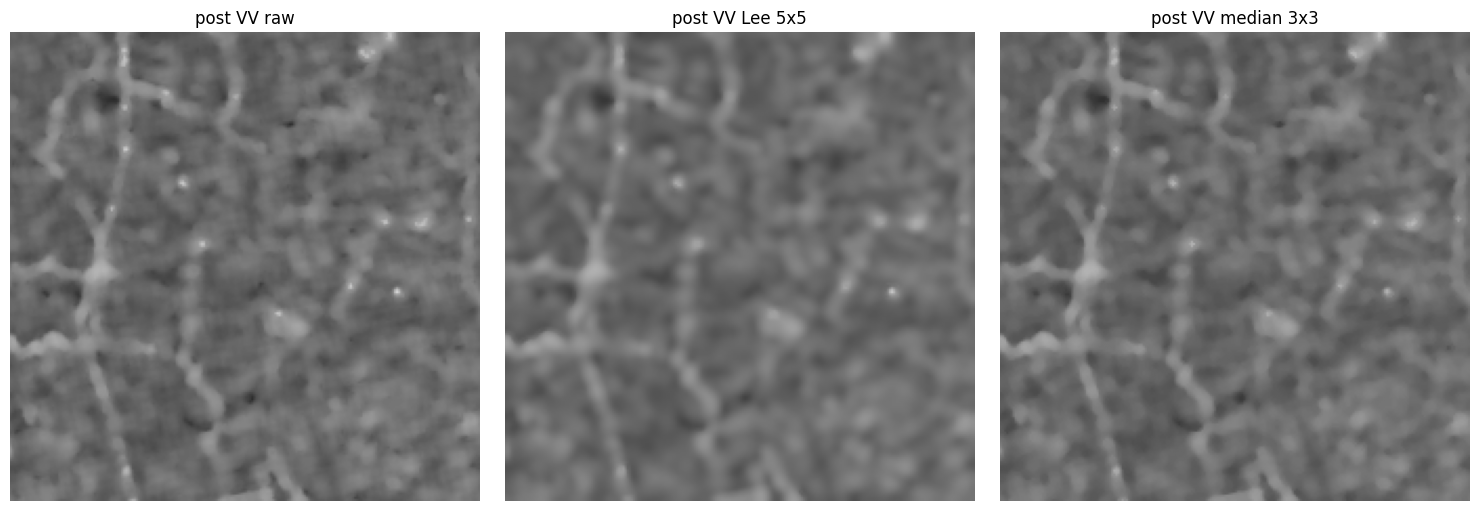

local std of a 40x40 corner (dB): raw 1.24 | lee5 1.1 | med3 1.21 (only indicative; pick a homogeneous area for the report figure)
base_lee5_s0 already done
base_lee5_s1 already done
base_lee5_s2 already done
base_med3_s0 already done
base_med3_s1 already done
base_med3_s2 already done


,seeds,params_M,best_epoch,IoU,F1,precision,recall
experiment,,,,,,,
abl_pre1_post4,3,7.76,"8, 3, 5",0.684 +/- 0.008,0.812 +/- 0.006,0.816 +/- 0.009,0.809 +/- 0.002
base_lee5,3,7.76,"8, 3, 3",0.683 +/- 0.004,0.812 +/- 0.003,0.820 +/- 0.010,0.804 +/- 0.015
base_med3,3,7.76,"5, 3, 3",0.680 +/- 0.013,0.810 +/- 0.009,0.834 +/- 0.013,0.788 +/- 0.028


,model,kind,IoU,IoU_no_min_area,F1,precision,recall,IoU_empty69,IoU_if_no_FP_on_empty,FP_share_from_empty_%
0,base,s0,0.6880,0.6885,0.8152,0.8245,0.8061,0.6712,0.6915,3.4885
1,base,s1,0.6888,0.6890,0.8157,0.8240,0.8075,0.6787,0.6908,2.0454
2,base,s2,0.6743,0.6748,0.8055,0.8076,0.8034,0.6567,0.6780,3.3960
3,base,ens,0.6911,0.6918,0.8174,0.8307,0.8045,0.6782,0.6938,2.7625
4,base_lee5,s0,0.6860,0.6865,0.8137,0.8216,0.8061,0.6712,0.6891,3.0023
5,base_lee5,s1,0.6854,0.6854,0.8134,0.8150,0.8117,0.6722,0.6882,2.5675
6,base_lee5,s2,0.6776,0.6783,0.8078,0.8346,0.7827,0.6637,0.6805,3.1648
7,base_lee5,ens,0.6890,0.6894,0.8159,0.8352,0.7974,0.6784,0.6912,2.3390
8,base_med3,s0,0.6862,0.6865,0.8139,0.8356,0.7934,0.6778,0.6880,1.8818
9,base_med3,s1,0.6891,0.6890,0.8160,0.8258,0.8063,0.6757,0.6919,2.7862


IoU         IoU_empty69         precision          recall  \
             mean     std        mean     std      mean     std    mean   
model                                                                     
base       0.6837  0.0081      0.6689  0.0112    0.8187  0.0096  0.8057   
base_lee5  0.6830  0.0047      0.6691  0.0047    0.8237  0.0099  0.8002   
base_med3  0.6800  0.0134      0.6686  0.0141    0.8376  0.0129  0.7839   

                   
              std  
model              
base       0.0021  
base_lee5  0.0154  
base_med3  0.0284

base_lee5: dIoU -0.0007 | dIoU_empty69 +0.0002 -> no measurable benefit
base_med3: dIoU -0.0037 | dIoU_empty69 -0.0003 -> no measurable benefit


In [7]:

 
# %% ---- E1: speckle filtering ablation (validation only)
# ============================================================
# Question: does reducing speckle before the network help? Two classical filters are applied on the fly to the 4 SAR channels of the
# plain U-Net input (pre1 + post, VV and VH), in the physical domain:
#   lee5  refined-Lee-style adaptive filter, 5x5 window, in LINEAR intensity (ENL = 4.4, typical for Sentinel-1 IW GRD), then back to dB
#   med3  3x3 median filter on the dB image
# Everything else is identical to `base` (recipe B, 3 seeds, same normalisation statistics). Rule fixed in advance, as before:
# a filter is adopted only if its mean single IoU is >= base + 0.015 AND its 69%-re-weighted IoU is not lower; otherwise it is reported
# as "no measurable benefit" (the U-Net learns its own smoothing).
# ============================================================
from scipy.ndimage import uniform_filter, median_filter
import matplotlib.pyplot as plt
 
ENL = 4.4
def lee_filter(db, win=5):
    """db: (C,H,W) dB -> Lee-filtered dB. Filtering is done in linear intensity."""
    lin = np.power(10.0, db / 10.0).astype(np.float32); out = np.empty_like(lin); cu2 = 1.0 / ENL
    for c in range(lin.shape[0]):
        x = lin[c]
        m = uniform_filter(x, win, mode="reflect"); m2 = uniform_filter(x * x, win, mode="reflect")
        ci2 = np.maximum(m2 - m * m, 0) / np.maximum(m * m, 1e-12)            # local coefficient of variation squared
        w = np.clip(1 - cu2 / np.maximum(ci2, 1e-12), 0, 1)                   # w = 0 in homogeneous areas, 1 on edges / targets
        out[c] = m + w * (x - m)
    return np.clip(10 * np.log10(np.maximum(out, 1e-4)), DB_MIN, DB_MAX).astype(np.float32)
 
def median_db(db, win=3):
    return np.stack([median_filter(c, size=win, mode="reflect") for c in db]).astype(np.float32)
 
FILTERS = {"lee5": lambda d: lee_filter(d, 5), "med3": lambda d: median_db(d, 3)}
 
class FloodDatasetF(FloodDataset):
    """SAR channels (dB) -> despeckle filter -> standardize with the ORIGINAL training statistics -> flips / rotations."""
    def __init__(self, split, cfg, augment=False):
        super().__init__(split, augment=False, normalize=False)
        self.cfg, self.aug, self.ch = cfg, augment, list(cfg["channels"])
        self.mean, self.std = MEAN[self.ch], STD[self.ch]
    def __getitem__(self, i):
        if self.X is None:
            self.X = np.load(PROC / f"X_{self.split}.npy", mmap_mode="r"); self.Y = np.load(PROC / f"Y_{self.split}.npy", mmap_mode="r")
        x = ((FILTERS[self.cfg["despeckle"]](_db(self.X, i, self.ch)) - self.mean) / self.std).astype(np.float32)
        lab = np.asarray(self.Y[i]); target = (lab == 2).astype(np.float32); valid = lab != IGNORE
        if self.aug:
            if random.random() < 0.5: x, target, valid = x[:, :, ::-1], target[:, ::-1], valid[:, ::-1]
            if random.random() < 0.5: x, target, valid = x[:, ::-1], target[::-1], valid[::-1]
            k = random.randint(0, 3)
            if k: x, target, valid = np.rot90(x, k, (1, 2)), np.rot90(target, k), np.rot90(valid, k)
        return (torch.from_numpy(np.ascontiguousarray(x)), torch.from_numpy(np.ascontiguousarray(target)),
                torch.from_numpy(np.ascontiguousarray(valid)))
 
if "_prev_loader" not in globals():
    _prev_loader = make_loader_v2
def make_loader_v2(split, cfg, batch_size=16, train=False, workers=2):
    if not cfg.get("despeckle"):
        return _prev_loader(split, cfg, batch_size, train, workers)
    ds = FloodDatasetF("train" if train else split, cfg, augment=train)
    return DataLoader(ds, batch_size=batch_size, shuffle=train, num_workers=workers, pin_memory=USE_AMP, persistent_workers=workers > 0)
 
_b = {k: v for k, v in CFGS["base"].items() if k != "ckpt"}
CFGS["base_lee5"] = {**_b, "despeckle": "lee5"}
CFGS["base_med3"] = {**_b, "despeckle": "med3"}
 
# --- what the filters do (one validation patch with flood): raw vs Lee vs median
_ds = FloodDatasetV2("val", CFGS["base"]); _i = int(np.argmax(_ds.meta.pflood.to_numpy()))
_raw = _db(np.load(PROC / "X_val.npy", mmap_mode="r"), _i, [0, 1, 4, 5])
fig, ax = plt.subplots(1, 3, figsize=(15, 5))
for a, (t, im) in zip(ax, [("post VV raw", _raw[2]), ("post VV Lee 5x5", FILTERS["lee5"](_raw)[2]), ("post VV median 3x3", FILTERS["med3"](_raw)[2])]):
    a.imshow(im, cmap="gray", vmin=-25, vmax=0); a.set_title(t); a.axis("off")
plt.tight_layout(); plt.savefig(ROOT / "figures" / "despeckle_examples.png", dpi=120); plt.show()
_flat = _raw[2][:40, :40]
print("local std of a 40x40 corner (dB): raw", _raw[2][:40, :40].std().round(2), "| lee5", FILTERS["lee5"](_raw)[2][:40, :40].std().round(2),
      "| med3", FILTERS["med3"](_raw)[2][:40, :40].std().round(2), "(only indicative; pick a homogeneous area for the report figure)")
 
# --- training (resumable; ~17 min per run on a T4; the filters make the data loader a bit slower)
SEEDS = (0, 1, 2)
for name in ["base_lee5", "base_med3"]:
    run_v2(name, SEEDS)
display(summarize(["abl_pre1_post4", "base_lee5", "base_med3"]))
 
# --- validation comparison, ONE pass over validation for everything
G = [load_group(n)[0] for n in ["base", "base_lee5", "base_med3"]]
S, _, _ = multi_stats(G, ["val"])
V = pd.DataFrame([{"model": k.split("|")[0], "kind": k.split("|")[1], **fin_metrics(d)} for k, d in S.items()])
V.to_csv(ROOT / "results" / "despeckle_val_detail.csv", index=False); display(V.round(4))
sing = V[V.kind.str.startswith("s")].groupby("model")[["IoU", "IoU_empty69", "precision", "recall"]].agg(["mean", "std"]).round(4); display(sing)
dec_ds = {}
for new in ["base_lee5", "base_med3"]:
    a, b = V[(V.model == new) & V.kind.str.startswith("s")], V[(V.model == "base") & V.kind.str.startswith("s")]
    d1, d2 = a.IoU.mean() - b.IoU.mean(), a.IoU_empty69.mean() - b.IoU_empty69.mean()
    dec_ds[new] = {"dIoU": float(d1), "dIoU_empty69": float(d2), "adopt": bool(len(a) == 3 and d1 >= 0.015 and d2 >= 0)}
    print(f"{new}: dIoU {d1:+.4f} | dIoU_empty69 {d2:+.4f} -> {'ADOPT' if dec_ds[new]['adopt'] else 'no measurable benefit'}")
(ROOT / "results" / "despeckle_decision.json").write_text(json.dumps(dec_ds, indent=2))
 
# --- OPTIONAL post-hoc check on the (already used) fresh test. Descriptive only: it cannot change the frozen headline.
POSTHOC_TEST = False
if POSTHOC_TEST:
    tv = set(pd.read_csv(PROC / "manifest_trainval.csv").actid.astype(int))
    GT = [load_group(n)[0] for n in ["base", "base_lee5", "base_med3"]]
    St, meta, _ = multi_stats(GT, ["test_01", "test_02"]); keep = ~meta.actid.astype(int).isin(tv).to_numpy()
    T = pd.DataFrame([{"model": k.split("|")[0], "kind": k.split("|")[1], **fin_metrics(d[keep])} for k, d in St.items()])
    T.to_csv(ROOT / "results" / "posthoc_despeckle_test.csv", index=False); display(T.round(4))
    print("POST-HOC, exploratory: not used for any decision.")
 

In [11]:
# %% ---- E2: permanent water analysis (no training; `base` ensemble, descriptive)
# ============================================================
# Flood = label 2; permanent water (label 1) counts as "not flood" in training and in every metric. This cell measures what that costs:
#   * how many false-positive pixels fall on permanent water vs on dry background,
#   * what share of all permanent-water pixels the model calls flood,
#   * the IoU that would result if permanent-water pixels were simply ignored in the score (an upper bound for any "permanent water fix").
# Pixel-level analysis, so the 500 px minimum-area rule is not applied here.
# ============================================================
trainval_events = set(pd.read_csv(PROC / "manifest_trainval.csv").actid.astype(int))
 
@torch.no_grad()
def perm_water_report(name="base", splits=("val", "test_01", "test_02")):
    g, runs = load_group(name); cfg, models = g[1], g[2]; rows = []
    for sp in splits:
        loader = make_loader_v2(sp, cfg); meta = loader.dataset.meta
        Y = np.load(PROC / f"Y_{sp}.npy", mmap_mode="r")
        keep = (~meta.actid.astype(int).isin(trainval_events).to_numpy()) if sp.startswith("test") else np.ones(len(meta), bool)
        c = dict(tp=0, fn=0, fp_bg=0, fp_pw=0, pw=0, pw_called=0, fp_pw_patches=0, fp_all_patches=0, pw_patches=0, n=0)
        i0 = 0
        for x, t, v in loader:
            n = len(x); lab = np.asarray(Y[i0:i0 + n]); k = keep[i0:i0 + n][:, None, None]; i0 += n
            with torch.autocast(DEVICE.type, enabled=USE_AMP):
                p = torch.stack([torch.sigmoid(m(x.to(DEVICE)).float()) for m in models]).mean(0)
            pred = (p > 0.5).cpu().numpy(); valid = lab != IGNORE
            fl, pw, bg = lab == 2, lab == 1, lab == 0
            c["tp"] += int((pred & fl & k).sum()); c["fn"] += int((~pred & fl & valid & k).sum())
            c["fp_bg"] += int((pred & bg & k).sum()); c["fp_pw"] += int((pred & pw & k).sum())
            c["pw"] += int((pw & k).sum()); c["pw_called"] += int((pred & pw & k).sum())
            has_pw = (pw.reshape(n, -1).any(1)) & k[:, 0, 0]
            c["pw_patches"] += int(has_pw.sum()); c["n"] += int(k.sum())
            c["fp_pw_patches"] += int((((pred & ~fl & valid).reshape(n, -1).sum(1)) * has_pw).sum())
            c["fp_all_patches"] += int((((pred & ~fl & valid).reshape(n, -1).sum(1)) * k[:, 0, 0]).sum())
        fp = c["fp_bg"] + c["fp_pw"]
        rows.append({"split": sp, "patches": c["n"], "patches_with_perm_water_%": 100 * c["pw_patches"] / max(c["n"], 1),
                     "IoU": c["tp"] / max(c["tp"] + fp + c["fn"], 1),
                     "IoU_ignoring_perm_water": c["tp"] / max(c["tp"] + c["fp_bg"] + c["fn"], 1),
                     "FP_px_total": fp, "FP_on_perm_water_%": 100 * c["fp_pw"] / max(fp, 1),
                     "perm_water_px_called_flood_%": 100 * c["pw_called"] / max(c["pw"], 1),
                     "FP_in_patches_with_perm_water_%": 100 * c["fp_pw_patches"] / max(c["fp_all_patches"], 1)})
    return pd.DataFrame(rows).set_index("split")
 
PW = perm_water_report("base"); PW.to_csv(ROOT / "results" / "permanent_water_analysis.csv"); display(PW.round(3))
print("Reading guide: if 'FP_on_perm_water_%' is small and IoU_ignoring_perm_water is close to IoU, permanent water is not a real problem for this "
      "model and a 3-class model is not worth the effort; if it is large, a 3-class output (flood / permanent water / background) is the fix.")
 

,patches,patches_with_perm_water_%,IoU,IoU_ignoring_perm_water,FP_px_total,FP_on_perm_water_%,perm_water_px_called_flood_%,FP_in_patches_with_perm_water_%
split,,,,,,,,
val,3684,64.577,0.692,0.726,3349516,32.273,11.889,69.842
test_01,6000,17.583,0.640,0.667,2789546,15.979,6.118,48.134
test_02,4839,36.309,0.372,0.392,327444,25.670,0.439,67.431


Reading guide: if 'FP_on_perm_water_%' is small and IoU_ignoring_perm_water is close to IoU, permanent water is not a real problem for this model and a 3-class model is not worth the effort; if it is large, a 3-class output (flood / permanent water / background) is the fix.


In [12]:

# %% ---- E3: cross-region analysis (no training; descriptive, uses the saved fresh-test patch statistics)
# ============================================================
# The `geom` field of every patch gives its location. This cell
#   1. parses geom -> (lon, lat) per patch and prints a sample so you can CHECK the parsing,
#   2. computes, for every fresh-test patch, the distance to the NEAREST training/validation patch (km),
#   3. reports IoU of `base` and `mt_g2` by that distance and per event, with an approximate continent label.
# Distance answers the open caveat of the plan: are the test events really in places the model has not seen?
# (Strict cross-region training, e.g. leave-one-continent-out, would need new training runs and is listed as future work.)
# ============================================================
import re
def parse_centroid(geom):
    nums = [float(x) for x in re.findall(r"-?\d+(?:\.\d+)?(?:[eE][-+]?\d+)?", str(geom))]
    nums = nums[:len(nums) // 2 * 2]
    xs, ys = np.array(nums[0::2]), np.array(nums[1::2])
    if len(xs) == 0: return (np.nan, np.nan)
    if np.abs(xs).max() <= 90 and np.abs(ys).max() > 90: xs, ys = ys, xs          # (lat, lon) order -> swap
    return (float(xs.mean()), float(ys.mean()))
 
def add_lonlat(df):
    c = np.array([parse_centroid(g) for g in df["geom"]]); df = df.copy(); df["lon"], df["lat"] = c[:, 0], c[:, 1]; return df
 
def haversine_min(lonlat_a, lonlat_b, chunk=400):
    """For every point in a, the distance in km to the nearest point in b."""
    A, B = np.radians(lonlat_a), np.radians(lonlat_b); out = np.empty(len(A))
    for i in range(0, len(A), chunk):
        a = A[i:i + chunk, None, :]
        dlon, dlat = a[..., 0] - B[None, :, 0], a[..., 1] - B[None, :, 1]
        h = np.sin(dlat / 2) ** 2 + np.cos(a[..., 1]) * np.cos(B[None, :, 1]) * np.sin(dlon / 2) ** 2
        out[i:i + chunk] = (2 * 6371 * np.arcsin(np.sqrt(np.clip(h, 0, 1)))).min(1)
    return out
 
def rough_region(lon, lat):                      # coarse boxes only; check each event by eye and fix with REGION_OVERRIDE
    if np.isnan(lon): return "?"
    if -170 <= lon <= -30 and lat >= 12: return "North/Central America"
    if -92 <= lon <= -30 and lat < 12: return "South America"
    if -25 <= lon <= 40 and lat >= 36: return "Europe"
    if -20 <= lon <= 52 and -36 <= lat < 36: return "Africa"
    if 110 <= lon <= 180 and lat < -10: return "Oceania"
    if 40 <= lon <= 180 and lat >= -10: return "Asia"
    return "other"
REGION_OVERRIDE = {}                             # e.g. {427: "Africa"}
 
train_meta = add_lonlat(pd.read_csv(DATA / "train_metadata_v2.csv", dtype={"sample_id": str, "shard": str}))
print("geom sample:", str(train_meta.geom.iloc[0])[:150], "->", train_meta[["lon", "lat"]].iloc[0].round(3).tolist())
assert train_meta.lon.abs().max() <= 180 and train_meta.lat.abs().max() <= 90, "geom does not look like lon/lat degrees - inspect the sample above"
ref = train_meta[["lon", "lat"]].to_numpy()
 
# fresh-test patches in the SAME order as the evaluation (test_01 rows, then eligible test_02 rows; events seen in training removed)
_load = lambda s: (lambda m: m[m.split == s].sort_values("row"))(pd.read_csv(PROC / f"manifest_{s}.csv", dtype={"sample_id": str, "shard": str}))
tm = pd.concat([_load("test_01"), _load("test_02")], ignore_index=True)
tm = tm[~tm.actid.astype(int).isin(trainval_events)].reset_index(drop=True); tm = add_lonlat(tm)
tm["dist_km"] = haversine_min(tm[["lon", "lat"]].to_numpy(), ref)
 
P = {n: pd.read_csv(ROOT / "results" / f"fresh_test_patchstats_{n}_ens.csv") for n in ["base", "mt_g2"]}
assert all(len(p) == len(tm) for p in P.values()), f"patch statistics ({[len(p) for p in P.values()]}) do not match the test manifest ({len(tm)}); use the per-event table only"
iou = lambda d: metrics_from_counts(d.tp.sum(), d.fp.sum(), d.fn.sum(), 0)["IoU"]
bins = pd.cut(tm.dist_km, [-1, 50, 200, 1000, 5000, 1e6], labels=["<50 km", "50-200 km", "200-1000 km", "1000-5000 km", ">5000 km"])
rows = []
for b in bins.cat.categories:
    m = (bins == b).to_numpy()
    if m.sum():
        rows.append({"distance to nearest training patch": b, "patches": int(m.sum()), "events": int(tm.actid[m].nunique()),
                     **{f"IoU {n}": iou(with_min_area(p[m], AREA)) for n, p in P.items()}})
DIST = pd.DataFrame(rows).set_index("distance to nearest training patch"); DIST.to_csv(ROOT / "results" / "cross_region_by_distance.csv"); display(DIST.round(3))
 
ev = tm.groupby("actid").agg(patches=("sample_id", "size"), lon=("lon", "mean"), lat=("lat", "mean"), median_dist_km=("dist_km", "median"))
ev["region (approx)"] = [REGION_OVERRIDE.get(int(a), rough_region(r.lon, r.lat)) for a, r in ev.iterrows()]
for n, p in P.items():
    ev[f"IoU {n}"] = [iou(with_min_area(p[(tm.actid == a).to_numpy()], AREA)) for a in ev.index]
ev.round(3).to_csv(ROOT / "results" / "cross_region_by_event.csv"); display(ev.round(3))
reg = ev.groupby("region (approx)").apply(lambda g: pd.Series({"events": len(g), "patches": g.patches.sum(), **{f"IoU {n}": np.average(g[f"IoU {n}"], weights=g.patches) for n in P}}))
print("By approximate region (patch-weighted mean of event IoU):"); display(reg.round(3))
print("Training/validation regions for comparison:",
      train_meta.assign(region=[rough_region(a, b) for a, b in zip(train_meta.lon, train_meta.lat)]).groupby("region").actid.nunique().to_dict(), "events per region")
 

geom sample: POLYGON ((32415 1087705, 32415 1089945, 34655 1089945, 34655 1087705, 32415 1087705)) -> [33311.0, 1088601.0]


AssertionError: geom does not look like lon/lat degrees - inspect the sample above

In [19]:
# ============================================================
# E3: Event-level generalisation analysis
# Descriptive only — no training, no new test evaluation.
# ============================================================

trainval_events = set(
    pd.read_csv(PROC / "manifest_trainval.csv").actid.astype(int)
)

def load_manifest(split):
    m = pd.read_csv(
        PROC / f"manifest_{split}.csv",
        dtype={"sample_id": str, "shard": str}
    )
    return m[m.split == split].sort_values("row")

tm = pd.concat(
    [load_manifest("test_01"), load_manifest("test_02")],
    ignore_index=True
)

tm = tm[
    ~tm.actid.astype(int).isin(trainval_events)
].reset_index(drop=True)

P = {
    n: pd.read_csv(
        ROOT / "results" / f"fresh_test_patchstats_{n}_ens.csv"
    )
    for n in ["base", "mt_g2"]
}

assert all(
    len(p) == len(tm) for p in P.values()
), "Patch statistics do not match the test manifest."

def event_iou(d):
    return metrics_from_counts(
        d.tp.sum(), d.fp.sum(), d.fn.sum(), 0
    )["IoU"]

rows = []

for actid, indices in tm.groupby("actid").groups.items():
    idx = np.array(list(indices))

    row = {
        "actid": int(actid),
        "patches": len(idx),
        "mean_flood_fraction": float(tm.loc[idx, "pflood"].mean())
    }

    for name, predictions in P.items():
        d = predictions.iloc[idx]
        d = with_min_area(d, AREA)
        row[f"IoU_{name}"] = event_iou(d)

    rows.append(row)

EVENT_RESULTS = pd.DataFrame(rows).sort_values("actid")

EVENT_RESULTS.to_csv(
    ROOT / "results" / "cross_event_analysis.csv",
    index=False
)

display(EVENT_RESULTS.round(4))

print("\nOverall event-level summary:")
display(
    EVENT_RESULTS[
        ["IoU_base", "IoU_mt_g2"]
    ].agg(["mean", "std", "min", "max"]).round(4)
)

,actid,patches,mean_flood_fraction,IoU_base,IoU_mt_g2
0,277,873,8.4675,0.7851,0.7796
1,279,2381,0.7271,0.2548,0.2606
2,321,432,4.2901,0.5196,0.5377
3,324,548,2.3041,0.6034,0.6305
4,411,149,1.3757,0.7154,0.7178
5,417,506,6.2385,0.9065,0.9090
6,421,137,2.1504,0.6201,0.6370
7,427,5283,0.4656,0.2448,0.2432
8,437,169,0.7548,0.5828,0.5431
9,445,361,1.8976,0.7671,0.7577



Overall event-level summary:


,IoU_base,IoU_mt_g2
mean,0.6000,0.6016
std,0.2165,0.2156
min,0.2448,0.2432
max,0.9065,0.9090


In [8]:

# %% ---- E4: tiling and stitching of large scenes (function + self-check; no training)
# ============================================================
# Kuro Siwo is delivered as 224x224 patches, so the experiments never needed tiling. This cell adds what a real deployment on a full
# Sentinel-1 scene needs: reflect-pad -> overlapping 224x224 tiles -> model -> Hann-weighted blending -> crop back.
#   scene_to_input(sar6)   (6,H,W) LINEAR backscatter [sec1_vv, sec1_vh, sec2_vv, sec2_vh, flood_vv, flood_vh] -> (4,H,W) normalised input
#                          for the `base` U-Net, with exactly the same dB conversion, clipping, 8-bit quantisation and standardisation as training.
#   predict_scene(models, x, tile=224, overlap=32)  -> (H,W) flood probability map (ensemble average over `models`)
# Self-check: a 2x2 mosaic of validation patches. With overlap 0 the stitched prediction must equal the patch-wise one exactly;
# with overlap 32 it must agree on (almost) every pixel.
# ============================================================
def scene_to_input(sar6, channels=(0, 1, 4, 5)):
    db = encode_sar(np.asarray(sar6, np.float32)).astype(np.float32) * SCALE + DB_MIN          # same quantisation as the stored arrays
    ch = list(channels)
    return ((db[ch] - MEAN[ch]) / STD[ch]).astype(np.float32)
 
def _hann2d(t):
    w = np.hanning(t + 2)[1:-1].astype(np.float32); return np.outer(w, w) + 1e-3
 
@torch.no_grad()
def predict_scene(models, x, tile=224, overlap=32, batch=8):
    """x: (C,H,W) normalised input of any size >= 1 pixel; returns the (H,W) probability map."""
    C, H, W = x.shape; step = tile - overlap
    grow = lambda n: tile if n <= tile else tile + -(-(n - tile) // step) * step          # padded size: tile + k * step
    Hp, Wp = grow(H), grow(W); ph, pw_ = Hp - H, Wp - W
    xp = np.pad(x, ((0, 0), (0, ph), (0, pw_)), mode="reflect" if max(ph, pw_) < min(H, W) else "edge") if (ph or pw_) else x
    ys = list(range(0, Hp - tile + 1, step)); xs = list(range(0, Wp - tile + 1, step))
    acc, wsum = np.zeros((Hp, Wp), np.float32), np.zeros((Hp, Wp), np.float32); win = _hann2d(tile) if overlap > 0 else np.ones((tile, tile), np.float32)
    coords = [(y, x_) for y in ys for x_ in xs]
    for i in range(0, len(coords), batch):
        cs = coords[i:i + batch]
        xb = torch.from_numpy(np.stack([xp[:, y:y + tile, x_:x_ + tile] for y, x_ in cs])).to(DEVICE)
        with torch.autocast(DEVICE.type, enabled=USE_AMP):
            pb = torch.stack([torch.sigmoid(m(xb).float()) for m in models]).mean(0).cpu().numpy()
        for (y, x_), p in zip(cs, pb):
            acc[y:y + tile, x_:x_ + tile] += p * win; wsum[y:y + tile, x_:x_ + tile] += win
    return (acc / wsum)[:H, :W]
 
# --- self-check
_g, _ = load_group("base"); _models = _g[2]
_ds = FloodDatasetV2("val", CFGS["base"]); _idx = [int(i) for i in np.linspace(0, len(_ds) - 1, 4)]
_xs = [_ds[i][0].numpy() for i in _idx]
_mosaic = np.concatenate([np.concatenate(_xs[:2], 2), np.concatenate(_xs[2:], 2)], 1)               # (4,448,448)
with torch.no_grad():
    _patch = [torch.stack([torch.sigmoid(m(torch.from_numpy(a)[None].to(DEVICE)).float()) for m in _models]).mean(0)[0].cpu().numpy() for a in _xs]
_ref = np.concatenate([np.concatenate(_patch[:2], 1), np.concatenate(_patch[2:], 1)], 0)
p0 = predict_scene(_models, _mosaic, 224, 0); p32 = predict_scene(_models, _mosaic, 224, 32)
print("mosaic", _mosaic.shape, "| overlap 0 vs patch-wise: max abs diff", float(np.abs(p0 - _ref).max()))
print("overlap 32 vs patch-wise: flood mask agreement", float(((p32 > .5) == (_ref > .5)).mean()), "| mean abs prob diff", float(np.abs(p32 - _ref).mean()))
_odd = predict_scene(_models, _mosaic[:, :300, :390], 224, 32); print("non-multiple size", _mosaic[:, :300, :390].shape, "->", _odd.shape)
print("Usage on a real scene:  x = scene_to_input(sar6_linear);  prob = predict_scene(models, x);  flood = prob > 0.5  (then apply the 500 px rule per scene region if wanted)")
 

mosaic (4, 448, 448) | overlap 0 vs patch-wise: max abs diff 0.0007761716842651367
overlap 32 vs patch-wise: flood mask agreement 0.9997159996811225 | mean abs prob diff 0.0004271878569852561
non-multiple size (4, 300, 390) -> (300, 390)
Usage on a real scene:  x = scene_to_input(sar6_linear);  prob = predict_scene(models, x);  flood = prob > 0.5  (then apply the 500 px rule per scene region if wanted)


In [2]:
"""
Explainability for the plain U-Net (`base`, 4 channels: pre1 VV/VH + post VV/VH).
Run inside your Kaggle notebook after the UNet class and a trained checkpoint exist.
NOT TESTED by the assistant (no torch in its sandbox): run on one patch first.

Produces, for a validation or test patch:
  1. Grad-CAM at the last decoder block (fine detail) and at the bottleneck (context)
  2. Input saliency: how much each input channel (pre1 vs post, VV vs VH) drives the flood score
"""
import torch, numpy as np, matplotlib.pyplot as plt

CHANNELS = ["pre1 VV", "pre1 VH", "post VV", "post VH"]


class GradCAM:
    def __init__(self, model, layer):
        self.model, self.acts, self.grads = model.eval(), None, None
        layer.register_forward_hook(lambda m, i, o: setattr(self, "acts", o.detach()))
        layer.register_full_backward_hook(lambda m, gi, go: setattr(self, "grads", go[0].detach()))

    def __call__(self, x, region=None):
        """x: (1,C,H,W) normalised input. region: bool (H,W) mask to explain
        (default = pixels predicted as flood)."""
        x = x.clone().requires_grad_(True)
        logits = self.model(x)                      # (1,H,W)
        if region is None:
            region = torch.sigmoid(logits[0]) > 0.5
        if region.sum() == 0:
            return None, torch.sigmoid(logits)[0].detach(), x
        score = (logits[0] * region).sum() / region.sum()
        self.model.zero_grad()
        score.backward()
        w = self.grads.mean(dim=(2, 3), keepdim=True)            # channel weights
        cam = torch.relu((w * self.acts).sum(1, keepdim=True))   # (1,1,h,w)
        cam = torch.nn.functional.interpolate(cam, size=x.shape[-2:], mode="bilinear", align_corners=False)[0, 0]
        cam = (cam / cam.max().clamp(min=1e-8)).cpu().numpy()
        return cam, torch.sigmoid(logits)[0].detach(), x


def channel_importance(x_grad):
    """Gradient x input, averaged over the image: share of attribution per input channel."""
    a = (x_grad.grad * x_grad.detach()).abs().mean(dim=(2, 3))[0]
    return (a / a.sum()).cpu().numpy()


def explain_patch(model, x, y=None, out="figures/explain_patch.png", device="cuda"):
    """x: (4,224,224) tensor already normalised like training; y: (224,224) flood mask or None."""
    model = model.to(device).eval()
    x = x[None].to(device)
    cam_fine = GradCAM(model, model.dec[0])      # last decoder block (finest scale)
    cam_ctx = GradCAM(model, model.enc[4])       # bottleneck (coarsest scale)
    c1, prob, xg = cam_fine(x)
    if c1 is None:
        print("No predicted flood pixels in this patch; pick a patch with flood.")
        return
    imp = None
    logits = model(xg)
    score = (logits[0] * (torch.sigmoid(logits[0]) > 0.5)).sum()
    model.zero_grad(); score.backward()
    imp = channel_importance(xg)
    c2, _, _ = cam_ctx(x)

    fig, ax = plt.subplots(1, 6, figsize=(20, 3.6))
    ax[0].imshow(x[0, 0].cpu(), cmap="gray"); ax[0].set_title("pre1 VV")
    ax[1].imshow(x[0, 2].cpu(), cmap="gray"); ax[1].set_title("post VV")
    ax[2].imshow(prob.cpu(), vmin=0, vmax=1); ax[2].set_title("P(flood)")
    ax[3].imshow(y if y is not None else np.zeros((224, 224)), cmap="Blues"); ax[3].set_title("label")
    ax[4].imshow(x[0, 2].cpu(), cmap="gray"); ax[4].imshow(c1, cmap="jet", alpha=0.45); ax[4].set_title("Grad-CAM, last decoder")
    ax[5].bar(CHANNELS, imp); ax[5].set_title("input attribution share"); ax[5].tick_params(axis="x", rotation=30)
    for a in ax[:5]: a.axis("off")
    plt.tight_layout(); plt.savefig(out, dpi=200); plt.show()
    print(dict(zip(CHANNELS, np.round(imp, 3))))


# --- usage in the notebook ---------------------------------------------------
# model = UNet(in_ch=4, base=32); model.load_state_dict(torch.load("checkpoints/abl_pre1_post4_s0.pt"))
# x, t, v = next(iter(make_loader("val", 1, channels="pre1_post4")))   # use your own loader/channel helper
# explain_patch(model, x[0], t[0].numpy())
#
# For the paper: average `imp` over ~200 flood patches per split to report
# "post VV carries X% of attribution, pre1 VV Y%", which supports the claim that
# the network uses the pre/post contrast. Do the same for the gate values of mt_g2.

In [9]:
# %% ---- B0: check requirements, installs
import importlib, subprocess, sys
need = ["CFGS", "load_group", "multi_stats", "fin_metrics", "make_loader_v2", "FloodDatasetV2", "FloodDatasetMT", "_db", "gap_days", "build_model",
        "train_v2", "summarize", "predict_scene", "masked_bce_tversky", "set_seed", "evaluate", "UNet", "DoubleConv", "MEAN", "STD", "DB_MIN", "DB_MAX",
        "SCALE", "IGNORE", "PROC", "DATA", "ROOT", "DEVICE", "USE_AMP", "metrics_from_counts", "with_min_area", "AREA", "GatedFusion", "MTGateUNet", "DoubleConvN"]
missing = [n for n in need if n not in globals()]
assert not missing, f"run these notebook cells first (restore 61, definitions 62 and 67, DEM 1, E1 and E4); missing: {missing}"
import random, math, json, gc, time, shutil
import torch.nn.functional as F
from IPython.display import display
for pkg, pipname in [("timm", "timm"), ("transformers", "transformers"), ("requests", "requests")]:
    try:
        importlib.import_module(pkg)
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pipname], check=False)
print("requirements ok | device:", DEVICE, "| free disk (GB):", round(shutil.disk_usage("/kaggle/working").free / 1e9, 1))
 

requirements ok | device: cuda | free disk (GB): 8.0


In [10]:

# %% ---- B1: recent baselines on Kuro Siwo (validation; post-hoc test is exploratory)
# ============================================================
# Two modern segmentation baselines, both with ImageNet-pretrained encoders, same 4 input channels as the plain U-Net (pre1 VV/VH + post VV/VH):
#   unet_r50      U-Net decoder on a pretrained ResNet-50 (timm). This is the best model family of the Kuro Siwo benchmark paper.
#   segformer_b2  SegFormer-B2 (hierarchical transformer, MiT-B2 pretrained, all-MLP decoder), first patch-embedding adapted to 4 channels.
# Same loss (masked BCE + Dice), epochs (12), patience (5), batch size 16 and 3 seeds as the plain U-Net. Learning rates fixed a priori and NOT tuned:
# 2e-4 (ResNet-50 U-Net), 6e-5 (SegFormer, the value of its paper). Pretrained weights come from the Hugging Face Hub (timm/resnet50.a1_in1k,
# nvidia/mit-b2) - the same Hub the data comes from.
# Reporting rule: these are COMPARISON baselines. They are evaluated on validation (like every model) and, post hoc, on the fresh test
# (flag), labelled as exploratory because the test was frozen before they existed. They cannot replace the frozen headline.
# ============================================================
import timm
from transformers import SegformerForSemanticSegmentation, SegformerConfig
 
class UNetResNet50(nn.Module):
    def __init__(self, in_ch=4, name="resnet50", pretrained=True, dec=(32, 64, 128, 256, 512)):
        super().__init__()
        self.enc = timm.create_model(name, pretrained=pretrained, features_only=True, in_chans=in_ch, out_indices=(0, 1, 2, 3, 4))
        ch = self.enc.feature_info.channels()                                            # [64, 256, 512, 1024, 2048], strides 2..32
        self.lat = nn.ModuleList([nn.Conv2d(c, d, 1) for c, d in zip(ch, dec)])
        self.up = nn.ModuleList([nn.ConvTranspose2d(dec[i + 1], dec[i], 2, stride=2) for i in range(4)])
        self.dec = nn.ModuleList([DoubleConv(dec[i] * 2, dec[i]) for i in range(4)])
        self.last = nn.ConvTranspose2d(dec[0], 16, 2, stride=2); self.head = nn.Conv2d(16, 1, 1)
    def forward(self, x):
        f = [l(t) for l, t in zip(self.lat, self.enc(x))]
        h = f[4]
        for i in (3, 2, 1, 0):
            u = self.up[i](h)
            if u.shape[-2:] != f[i].shape[-2:]: u = F.interpolate(u, size=f[i].shape[-2:], mode="bilinear", align_corners=False)
            h = self.dec[i](torch.cat([u, f[i]], 1))
        return self.head(F.relu(self.last(h))).squeeze(1)
 
class SegFormerWrap(nn.Module):
    def __init__(self, in_ch=4, name="nvidia/mit-b2", pretrained=True):
        super().__init__()
        if pretrained:
            m = SegformerForSemanticSegmentation.from_pretrained(name, num_labels=1, ignore_mismatched_sizes=True)
        else:
            m = SegformerForSemanticSegmentation(SegformerConfig(num_labels=1))
        for nm, mod in m.named_modules():                                              # first conv that reads the 3 RGB channels (robust to library versions)
            if isinstance(mod, nn.Conv2d) and mod.in_channels == 3: break
        w = mod.weight.data; new = nn.Conv2d(in_ch, mod.out_channels, mod.kernel_size, mod.stride, mod.padding)
        new.weight.data = torch.cat([w[:, :3], w.mean(1, keepdim=True).repeat(1, in_ch - 3, 1, 1)], 1) if in_ch > 3 else w[:, :in_ch].clone()
        new.bias.data = mod.bias.data.clone(); parent = m.get_submodule(nm.rsplit(".", 1)[0]); setattr(parent, nm.rsplit(".", 1)[1], new)
        if hasattr(m.config, "num_channels"): m.config.num_channels = in_ch
        self.m = m
    def forward(self, x):
        return F.interpolate(self.m(pixel_values=x).logits, size=x.shape[-2:], mode="bilinear", align_corners=False).squeeze(1)
 
PRETRAINED = True                      # set False only for offline smoke tests
if "_b1_prev_build" not in globals():
    _b1_prev_build = build_model
def build_model(cfg):
    a = cfg.get("arch")
    if a == "r50u": return UNetResNet50(len(cfg["channels"]), pretrained=PRETRAINED)
    if a == "segf": return SegFormerWrap(len(cfg["channels"]), pretrained=PRETRAINED)
    return _b1_prev_build(cfg)
 
_b = {k: v for k, v in CFGS["base"].items() if k != "ckpt"}
CFGS["unet_r50"] = {**_b, "arch": "r50u"}
CFGS["segformer_b2"] = {**_b, "arch": "segf"}
BASELINE_LR = {"unet_r50": 2e-4, "segformer_b2": 6e-5}
 
def run_baseline(name, seeds, epochs=12, patience=5, wd=1e-4):
    cfg = CFGS[name]
    for s in seeds:
        run = f"{name}_s{s}"; out = ROOT / "results" / f"{run}.json"
        if out.exists(): print(run, "already done"); continue
        set_seed(s); t0 = time.time()
        model, info = train_v2(build_model(cfg), run, cfg, epochs, BASELINE_LR[name], weight_decay=wd, patience=patience)
        pooled, per_event = evaluate(lambda x: torch.sigmoid(model(x)), make_loader_v2("val", cfg))
        out.write_text(json.dumps({"run": run, "cfg": cfg, "epochs": epochs, "lr": BASELINE_LR[name], "params": sum(p.numel() for p in model.parameters()),
                                   "train_minutes": (time.time() - t0) / 60, **info, "val": pooled, "val_per_event": per_event.to_dict("records")},
                                  default=lambda o: o.item() if hasattr(o, "item") else str(o)))
        del model; gc.collect(); torch.cuda.empty_cache()
 
BASELINE_SEEDS = (0, 1, 2)             # ~20 min per seed per model on a T4; use (0,) for a first look
for n in ["unet_r50", "segformer_b2"]:
    run_baseline(n, BASELINE_SEEDS)
display(summarize(["abl_pre1_post4", "mt_g2", "unet_r50", "segformer_b2"]))
 
# --- validation comparison with the frozen models (one pass; `base` = plain U-Net, `mt_g2` = proposed)
names = ["base", "mt_g2", "unet_r50", "segformer_b2"]
G = [load_group(n)[0] for n in names]; G = [g for g in G if g[2]]
S, _, _ = multi_stats(G, ["val"])
V = pd.DataFrame([{"model": k.split("|")[0], "kind": k.split("|")[1], **fin_metrics(d)} for k, d in S.items()])
V.to_csv(ROOT / "results" / "sota_baselines_val.csv", index=False)
sing = V[V.kind.str.startswith("s")].groupby("model")[["IoU", "F1", "precision", "recall", "IoU_empty69"]].agg(["mean", "std"]).round(4)
ens = V[V.kind == "ens"].set_index("model")[["IoU", "F1", "precision", "recall", "IoU_empty69"]].round(4)
print("VALIDATION, single models (mean/std over seeds), 500 px rule:"); display(sing); print("ensembles:"); display(ens)
print("parameters (M):", {n: round(sum(p.numel() for p in build_model(CFGS[n]).parameters()) / 1e6, 2) for n in ["unet_r50", "segformer_b2"]})
 
# --- OPTIONAL post-hoc evaluation on the already-used fresh test (exploratory; not used for any decision)
POSTHOC_TEST = True
if POSTHOC_TEST:
    tv = set(pd.read_csv(PROC / "manifest_trainval.csv").actid.astype(int))
    St, meta, gapt = multi_stats(G, ["test_01", "test_02"]); keep = ~meta.actid.astype(int).isin(tv).to_numpy()
    T = pd.DataFrame([{"model": k.split("|")[0], "kind": k.split("|")[1], **fin_metrics(d[keep].reset_index(drop=True))} for k, d in St.items()])
    T.to_csv(ROOT / "results" / "sota_baselines_test_posthoc.csv", index=False)
    cols = ["IoU", "F1", "precision", "recall", "IoU_no_min_area", "IoU_if_no_FP_on_empty"]
    print("FRESH TEST, POST HOC / EXPLORATORY (frozen test was evaluated before these baselines existed):")
    display(T[T.kind.str.startswith("s")].groupby("model")[cols].agg(["mean", "std"]).round(4)); display(T[T.kind == "ens"].set_index("model")[cols].round(4))
    # per-event IoU of the ensembles
    ev = {}
    for n in [g[0] for g in G]:
        d = with_min_area(St[f"{n}|ens"][keep].reset_index(drop=True), AREA)
        ev[n] = {int(a): metrics_from_counts(r.tp, r.fp, r.fn, 0)["IoU"] for a, r in d.groupby("actid")[["tp", "fp", "fn"]].sum().iterrows()}
    display(pd.DataFrame(ev).round(3).T)
 
 

model.safetensors: reconstructing file:   0%|          |  0.00B /  102MB            

model.safetensors: downloading bytes:           |  0.00B            

[unet_r50_s0] ep 01 | loss 0.8371 | val IoU 0.6885 | 73s
[unet_r50_s0] ep 02 | loss 0.3814 | val IoU 0.6725 | 71s
[unet_r50_s0] ep 03 | loss 0.3303 | val IoU 0.6946 | 70s
[unet_r50_s0] ep 04 | loss 0.2989 | val IoU 0.6803 | 71s
[unet_r50_s0] ep 05 | loss 0.2850 | val IoU 0.6859 | 71s
[unet_r50_s0] ep 06 | loss 0.2745 | val IoU 0.6790 | 70s
[unet_r50_s0] ep 07 | loss 0.2614 | val IoU 0.6868 | 70s
[unet_r50_s0] ep 08 | loss 0.2519 | val IoU 0.6872 | 70s
early stopping
[unet_r50_s1] ep 01 | loss 0.8448 | val IoU 0.6864 | 71s
[unet_r50_s1] ep 02 | loss 0.3927 | val IoU 0.6684 | 70s
[unet_r50_s1] ep 03 | loss 0.3350 | val IoU 0.6686 | 70s
[unet_r50_s1] ep 04 | loss 0.3100 | val IoU 0.6294 | 70s
[unet_r50_s1] ep 05 | loss 0.2949 | val IoU 0.6702 | 70s
[unet_r50_s1] ep 06 | loss 0.2801 | val IoU 0.6694 | 70s
early stopping
[unet_r50_s2] ep 01 | loss 0.9129 | val IoU 0.6594 | 71s
[unet_r50_s2] ep 02 | loss 0.4150 | val IoU 0.7005 | 70s
[unet_r50_s2] ep 03 | loss 0.3357 | val IoU 0.6904 | 70s
[

config.json:   0%|          | 0.00/70.0k [00:00<?, ?B/s]

[transformers] You passed `num_labels=1` which is incompatible to the `id2label` map of length `1000`.


pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 99.0MB            

... (29 outputs left out)

parameters (M): {'unet_r50': 27.96, 'segformer_b2': 27.35}
FRESH TEST, POST HOC / EXPLORATORY (frozen test was evaluated before these baselines existed):


IoU              F1         precision          recall  \
                mean     std    mean     std      mean     std    mean   
model                                                                    
base          0.5859  0.0189  0.7388  0.0152    0.6905  0.0188  0.7944   
mt_g2         0.5867  0.0158  0.7394  0.0125    0.6875  0.0329  0.8012   
segformer_b2  0.5833  0.0046  0.7368  0.0036    0.6983  0.0169  0.7802   
unet_r50      0.5868  0.0213  0.7394  0.0170    0.7024  0.0518  0.7844   

                     IoU_no_min_area         IoU_if_no_FP_on_empty          
                 std            mean     std                  mean     std  
model                                                                       
base          0.0101          0.5789  0.0185                0.6601  0.0105  
mt_g2         0.0169          0.5790  0.0176                0.6685  0.0061  
segformer_b2  0.0135          0.5774  0.0047                0.6653  0.0043  
unet_r50      0.0361          0.5813  0.0229                0.6636  0.0126

,IoU,F1,precision,recall,IoU_no_min_area,IoU_if_no_FP_on_empty
model,,,,,,
base,0.5994,0.7495,0.7090,0.7949,0.5926,0.6655
mt_g2,0.5967,0.7474,0.7002,0.8015,0.5898,0.6720
unet_r50,0.6057,0.7544,0.7232,0.7885,0.6011,0.6735
segformer_b2,0.5889,0.7413,0.7051,0.7814,0.5832,0.6682


,277,279,321,324,411,417,421,427,437,445
base,0.785,0.255,0.520,0.603,0.715,0.906,0.620,0.245,0.583,0.767
mt_g2,0.780,0.261,0.538,0.630,0.718,0.909,0.637,0.243,0.543,0.758
unet_r50,0.786,0.260,0.536,0.637,0.702,0.905,0.596,0.228,0.571,0.777
segformer_b2,0.787,0.223,0.540,0.617,0.708,0.907,0.622,0.245,0.571,0.750


source: gcs | chips per layer: {'S1Hand': 446, 'LabelHand': 446, 'JRCWaterHand': 446} | split files: ['bolivia', 'test', 'train', 'valid']
chips with split: 446 {'bolivia': 15, 'test': 90, 'train': 252, 'valid': 89}
done; chips with wrong shape (set to no-data): 0
EDA per split:


,chips,regions,water_frac,perm_frac,valid_frac
split,,,,,
bolivia,15,1,0.170,0.015,0.718
test,90,10,0.123,0.046,0.867
train,252,10,0.093,0.026,0.867
valid,89,10,0.110,0.032,0.869


EDA per region:


,chips,water_frac,perm_frac
region,,,
Bolivia,15,0.170,0.015
Ghana,53,0.064,0.013
India,68,0.128,0.023
Mekong,30,0.236,0.076
Nigeria,18,0.223,0.019
Pakistan,28,0.076,0.027
Paraguay,67,0.079,0.028
Somalia,26,0.062,0.000
Spain,30,0.141,0.052


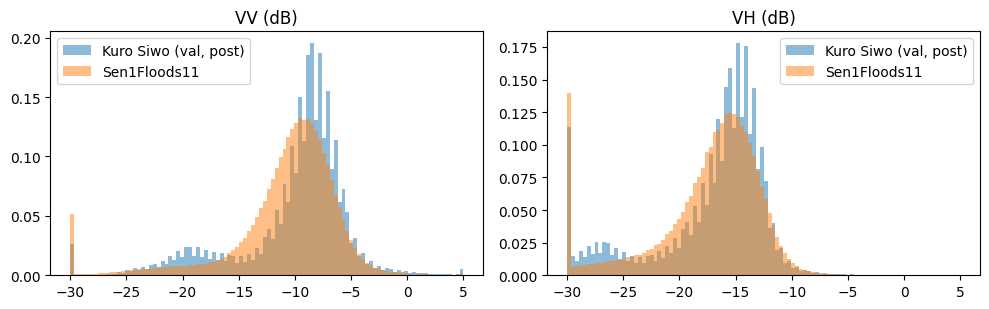

percentiles 1/25/50/75/99  VV  Kuro: [-26.7 -11.2  -8.9  -7.2  -0.5] | Sen1Floods11: [-30.  -12.2  -9.8  -7.9  -2.3]
percentiles 1/25/50/75/99  VH  Kuro: [-30.  -18.6 -15.7 -13.9  -9.4] | Sen1Floods11: [-30.  -19.2 -16.3 -14.2  -9.6]


In [11]:

# %% ---- D1: Sen1Floods11 - get the data, convert, EDA
# ============================================================
# Sen1Floods11 (Bonafilia et al., CVPRW 2020): 446 hand-labelled 512x512 chips with Sentinel-1 GRD in dB (band 0 = VV, band 1 = VH),
# water labels (-1 no data, 0 not water, 1 water) and the JRC permanent-water layer; official splits train / valid / test / bolivia
# (Bolivia is a held-out REGION). There is ONE Sentinel-1 image per chip (no pre-event image), so only post-event models can be used here.
#
# Source order (first that works):  1. SEN_LOCAL_DIR, an attached Kaggle dataset (best if the internet is restricted)
#                                   2. public Google Cloud bucket sen1floods11 over HTTPS
#                                   3. Hugging Face mirror harshinde/sen1floods11 (third-party copy)
# The cell prints what it found. If all three fail, attach a Sen1Floods11 dataset to the notebook and set SEN_LOCAL_DIR.
# Output: data/sen1floods11/S_X.npy (n,2,512,512 float16 dB), S_Y.npy (int8 -1/0/1), S_P.npy (uint8 JRC permanent water), manifest.csv.
# ============================================================
import requests, glob, time as _time
from pathlib import Path
SEN = DATA / "sen1floods11"; SEN.mkdir(parents=True, exist_ok=True)
SEN_LOCAL_DIR = None                       # e.g. "/kaggle/input/sen1floods11"
GCS_BASE, GCS_API = "https://storage.googleapis.com/sen1floods11", "https://storage.googleapis.com/storage/v1/b/sen1floods11/o"
HF_MIRROR = "harshinde/sen1floods11"
KINDS = {"S1Hand": "_S1Hand.tif", "LabelHand": "_LabelHand.tif", "JRCWaterHand": "_JRCWaterHand.tif"}
 
def read_tif(path):
    try:
        import rasterio
        with rasterio.open(path) as ds: return ds.read()
    except ImportError:
        try: import tifffile
        except ImportError:
            subprocess.run([sys.executable, "-m", "pip", "install", "-q", "tifffile"], check=False); import tifffile
        a = tifffile.imread(path)
        if a.ndim == 2: a = a[None]
        elif a.shape[-1] <= 4 < a.shape[0]: a = np.moveaxis(a, -1, 0)
        return a
 
def _http_get(url, dest, retries=3):
    for k in range(retries):
        try:
            with requests.get(url, stream=True, timeout=60) as r:
                r.raise_for_status()
                with open(dest, "wb") as f:
                    for ch in r.iter_content(1 << 20): f.write(ch)
            return dest
        except Exception as e:
            if k == retries - 1: raise
            _time.sleep(2 * (k + 1))
 
def _chip(name):
    for suf in KINDS.values():
        if name.endswith(suf): return name[:-len(suf)]
    return None
 
def discover():
    """Returns (index, split_refs, fetch): index[kind][chip] -> ref, split_refs[split] -> ref, fetch(ref, dest_dir) -> local Path."""
    idx = {k: {} for k in KINDS}; spl = {}
    if SEN_LOCAL_DIR:
        root = Path(SEN_LOCAL_DIR)
        for k in KINDS:
            for p in root.rglob(f"{k}/*.tif"): idx[k][_chip(p.name)] = p
        for p in root.rglob("*.csv"):
            if "flood_handlabeled" in str(p) or "flood_" in p.name:
                for s in ("train", "valid", "test", "bolivia"):
                    if s in p.name.lower() and "flood" in p.name.lower(): spl[s] = p
        return idx, spl, (lambda ref, d: ref), f"local:{SEN_LOCAL_DIR}"
    try:                                                                              # 2. Google Cloud Storage, anonymous HTTPS
        def lst(prefix):
            out, tok = [], None
            while True:
                r = requests.get(GCS_API, params={"prefix": prefix, "maxResults": 1000, **({"pageToken": tok} if tok else {})}, timeout=60); r.raise_for_status()
                j = r.json(); out += [o["name"] for o in j.get("items", [])]; tok = j.get("nextPageToken")
                if not tok: return out
        base = "v1.1/data/flood_events/HandLabeled/"
        for k in KINDS:
            for n in lst(base + k + "/"):
                if n.endswith(".tif"): idx[k][_chip(Path(n).name)] = n
        for n in lst("v1.1/splits/flood_handlabeled/"):
            for s in ("train", "valid", "test", "bolivia"):
                if n.endswith(".csv") and s in Path(n).name.lower(): spl[s] = n
        if not idx["S1Hand"]: raise RuntimeError("bucket listing empty")
        return idx, spl, (lambda ref, d: _http_get(f"{GCS_BASE}/{ref}", Path(d) / Path(ref).name)), "gcs"
    except Exception as e:
        print("GCS not usable:", repr(e)[:150])
    from huggingface_hub import HfApi, hf_hub_download                                 # 3. Hugging Face mirror
    files = HfApi().list_repo_files(HF_MIRROR, repo_type="dataset")
    for f in files:
        for k in KINDS:
            if f"/{k}/" in f and f.endswith(".tif"): idx[k][_chip(Path(f).name)] = f
        if f.endswith(".csv") and "flood" in Path(f).name.lower():
            for s in ("train", "valid", "test", "bolivia"):
                if s in Path(f).name.lower(): spl[s] = f
    return idx, spl, (lambda ref, d: Path(hf_hub_download(HF_MIRROR, ref, repo_type="dataset", local_dir=str(d)))), "hf-mirror"
 
if not (SEN / "manifest.csv").exists():
    idx, spl, fetch, src = discover()
    print("source:", src, "| chips per layer:", {k: len(v) for k, v in idx.items()}, "| split files:", sorted(spl))
    assert idx["S1Hand"] and idx["LabelHand"], "Sen1Floods11 not found: attach a Kaggle dataset and set SEN_LOCAL_DIR, or check internet access"
    tmp = Path("/tmp/sen_tmp"); tmp.mkdir(exist_ok=True)
    chips_by_split = {}
    for s, ref in spl.items():
        p = fetch(ref, tmp); lines = [l.strip().split(",")[0] for l in Path(p).read_text().splitlines() if l.strip()]
        chips_by_split[s] = [c for c in (_chip(Path(l).name) for l in lines) if c]
    assert chips_by_split, "no split files found; set SEN_LOCAL_DIR to a folder that contains the split CSVs"
    rows = [(c, s) for s, cs in chips_by_split.items() for c in cs if c in idx["S1Hand"] and c in idx["LabelHand"]]
    n = len(rows); print("chips with split:", n, {s: sum(1 for _, t in rows if t == s) for s in chips_by_split})
    SX = np.lib.format.open_memmap(SEN / "S_X.npy", mode="w+", dtype=np.float16, shape=(n, 2, 512, 512))
    SY = np.lib.format.open_memmap(SEN / "S_Y.npy", mode="w+", dtype=np.int8, shape=(n, 512, 512))
    SP = np.lib.format.open_memmap(SEN / "S_P.npy", mode="w+", dtype=np.uint8, shape=(n, 512, 512))
    bad = 0
    for i, (c, s) in enumerate(rows):
        x = read_tif(fetch(idx["S1Hand"][c], tmp)).astype(np.float32); y = read_tif(fetch(idx["LabelHand"][c], tmp))[0]
        perm = read_tif(fetch(idx["JRCWaterHand"][c], tmp))[0] if c in idx["JRCWaterHand"] else np.zeros_like(y)
        if x.shape != (2, 512, 512) or y.shape != (512, 512): bad += 1; y = np.full((512, 512), -1); x = np.zeros((2, 512, 512), np.float32); perm = np.zeros((512, 512))
        nanm = ~np.isfinite(x).all(0); x = np.nan_to_num(x, nan=DB_MIN, posinf=DB_MAX, neginf=DB_MIN); y = y.astype(np.int8); y[nanm] = -1
        SX[i], SY[i], SP[i] = np.clip(x, DB_MIN, DB_MAX).astype(np.float16), y, (perm > 0).astype(np.uint8)
        for p in tmp.glob("**/*.tif"): p.unlink()
        if i % 50 == 0: print(f"  {i}/{n}", end="\r")
    for a in (SX, SY, SP): a.flush()
    pd.DataFrame({"chip": [c for c, _ in rows], "split": [s for _, s in rows], "region": [c.split("_")[0] for c, _ in rows]}).to_csv(SEN / "manifest.csv", index=False)
    print("done; chips with wrong shape (set to no-data):", bad)
 
SMAN = pd.read_csv(SEN / "manifest.csv"); SX = np.load(SEN / "S_X.npy", mmap_mode="r"); SY = np.load(SEN / "S_Y.npy", mmap_mode="r"); SP = np.load(SEN / "S_P.npy", mmap_mode="r")
valid_n = [(np.asarray(SY[i]) != -1).mean() for i in range(len(SMAN))]
eda = SMAN.assign(valid_frac=valid_n, water_frac=[float((np.asarray(SY[i]) == 1).sum() / max((np.asarray(SY[i]) != -1).sum(), 1)) for i in range(len(SMAN))],
                  perm_frac=[float(np.asarray(SP[i]).mean()) for i in range(len(SMAN))])
print("EDA per split:"); display(eda.groupby("split").agg(chips=("chip", "size"), regions=("region", "nunique"), water_frac=("water_frac", "mean"), perm_frac=("perm_frac", "mean"), valid_frac=("valid_frac", "mean")).round(3))
print("EDA per region:"); display(eda.groupby("region").agg(chips=("chip", "size"), water_frac=("water_frac", "mean"), perm_frac=("perm_frac", "mean")).round(3))
eda.to_csv(ROOT / "results" / "sen1floods11_eda.csv", index=False)
 
# --- radiometry: Sen1Floods11 post-event dB vs Kuro Siwo post-event dB (a cross-dataset shift check)
import matplotlib.pyplot as plt
Xk = np.load(PROC / "X_val.npy", mmap_mode="r"); ik = np.linspace(0, len(Xk) - 1, 300).astype(int)
kv = np.stack([np.asarray(Xk[i][[4, 5]]).astype(np.float32) * SCALE + DB_MIN for i in ik])                 # (300,2,H,W) post VV/VH
sv = np.stack([np.asarray(SX[i]).astype(np.float32) for i in np.linspace(0, len(SX) - 1, 100).astype(int)])
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
for c, nm in enumerate(["VV", "VH"]):
    ax[c].hist(kv[:, c].ravel(), 100, range=(DB_MIN, DB_MAX), density=True, alpha=.5, label="Kuro Siwo (val, post)"); ax[c].hist(sv[:, c].ravel(), 100, range=(DB_MIN, DB_MAX), density=True, alpha=.5, label="Sen1Floods11")
    ax[c].set_title(f"{nm} (dB)"); ax[c].legend()
plt.tight_layout(); plt.savefig(ROOT / "figures" / "radiometry_kuro_vs_sen.png", dpi=130); plt.show()
print("percentiles 1/25/50/75/99  VV  Kuro:", np.percentile(kv[:, 0], [1, 25, 50, 75, 99]).round(1), "| Sen1Floods11:", np.percentile(sv[:, 0], [1, 25, 50, 75, 99]).round(1))
print("percentiles 1/25/50/75/99  VH  Kuro:", np.percentile(kv[:, 1], [1, 25, 50, 75, 99]).round(1), "| Sen1Floods11:", np.percentile(sv[:, 1], [1, 25, 50, 75, 99]).round(1))
del kv, sv
 

In [12]:

# %% ---- D2: cross-dataset evaluation (Kuro Siwo <-> Sen1Floods11), post-event-only U-Net, 3 seeds
# ============================================================
# Only what both datasets share can be compared: ONE post-event image (VV, VH) -> water mask. Same pre-processing (dB, clip [-30, 5], the SAME
# Kuro Siwo per-channel standardisation for both), same U-Net (2 input channels), same recipe family.
#   K->K  `abl_post2` (trained on Kuro Siwo flood, existing checkpoints)           tested on Kuro Siwo val / fresh test (post hoc)
#   K->S  the same checkpoints, zero-shot                                           tested on Sen1Floods11 test and the held-out region Bolivia
#   S->S  new U-Net trained on Sen1Floods11 train (water), early stopping on valid  tested on Sen1Floods11 test / Bolivia
#   S->K  the Sen1Floods11 models, zero-shot                                        tested on Kuro Siwo val / fresh test (post hoc)
# Label definitions differ: Sen1Floods11 "water" = flood + permanent water; Kuro Siwo "flood" = temporary flood only. Therefore two scores:
#   flood_noperm  predicted water vs flood, pixels of PERMANENT water (JRC layer / Kuro label 1) are ignored   <- the apples-to-apples comparison
#   water         Sen1Floods11 water vs prediction; for the Kuro-trained model the JRC permanent-water layer is added to its flood prediction;
#                 on Kuro Siwo water = label 1 or 2
# Sen1Floods11 chips are 512x512 and predicted with the tiling function of cell E4 (224 tiles, 32 px overlap, Hann blending).
# ============================================================
from torch.utils.data import Dataset, DataLoader
M2, S2 = MEAN[[4, 5]], STD[[4, 5]]                                           # Kuro Siwo post-event VV/VH statistics, used for BOTH datasets
trainval_events = set(pd.read_csv(PROC / "manifest_trainval.csv").actid.astype(int))
 
class SenCrops(Dataset):
    """Random 224x224 crops of the train chips (flips / 90-degree rotations); chips with no valid pixel in the crop are still returned (loss masks them)."""
    def __init__(self, split="train", n=1024, crop=224):
        self.ids = np.where(SMAN.split == split)[0]; self.n, self.crop = n, crop
    def __len__(self): return self.n
    def __getitem__(self, i):
        j = int(self.ids[random.randrange(len(self.ids))]); y0, x0 = random.randint(0, 512 - self.crop), random.randint(0, 512 - self.crop)
        x = (np.asarray(SX[j][:, y0:y0 + self.crop, x0:x0 + self.crop]).astype(np.float32) - M2) / S2
        lab = np.asarray(SY[j][y0:y0 + self.crop, x0:x0 + self.crop]); t, v = (lab == 1).astype(np.float32), lab != -1
        if random.random() < .5: x, t, v = x[:, :, ::-1], t[:, ::-1], v[:, ::-1]
        if random.random() < .5: x, t, v = x[:, ::-1], t[::-1], v[::-1]
        k = random.randint(0, 3)
        if k: x, t, v = np.rot90(x, k, (1, 2)), np.rot90(t, k), np.rot90(v, k)
        return torch.from_numpy(np.ascontiguousarray(x)), torch.from_numpy(np.ascontiguousarray(t)), torch.from_numpy(np.ascontiguousarray(v))
 
def sen_chip_input(i): return ((np.asarray(SX[i]).astype(np.float32) - M2) / S2).astype(np.float32)
 
def sen_counts(models, split, mode, region=None, threshold=0.5, k_model=False):
    """Pooled (tp, fp, fn) on Sen1Floods11 chips of a split. mode: 'water' or 'flood_noperm'."""
    ids = np.where((SMAN.split == split) & ((SMAN.region == region) if region else True))[0]; tp = fp = fn = 0
    for i in ids:
        pred = predict_scene(models, sen_chip_input(i), 224, 32) > threshold; lab = np.asarray(SY[i]); perm = np.asarray(SP[i]) > 0
        if mode == "water":
            if k_model: pred = pred | perm                                        # add JRC permanent water to a flood-only prediction
            tgt, val = lab == 1, lab != -1
        else:
            tgt, val = (lab == 1) & ~perm, (lab != -1) & ~perm
        tp += int((pred & tgt & val).sum()); fp += int((pred & ~tgt & val).sum()); fn += int((~pred & tgt & val).sum())
    return tp, fp, fn
 
def sen_train(seed, epochs=30, patience=8, lr=3e-4, wd=1e-4):
    run = f"sen_post_s{seed}"; ck = ROOT / "checkpoints" / f"{run}.pt"; res = ROOT / "results" / f"{run}.json"
    if res.exists(): print(run, "already done"); return
    set_seed(seed); model = UNet(in_ch=2, base=32).to(DEVICE)
    dl = DataLoader(SenCrops("train"), batch_size=16, num_workers=2, shuffle=False); opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=wd)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs); scaler = torch.amp.GradScaler(enabled=USE_AMP); best, bad, hist = -1, 0, []
    for ep in range(1, epochs + 1):
        model.train(); tot = 0
        for x, t, v in dl:
            x, t, v = x.to(DEVICE), t.to(DEVICE), v.to(DEVICE); opt.zero_grad(set_to_none=True)
            with torch.autocast(DEVICE.type, enabled=USE_AMP): lg = model(x)
            loss = masked_bce_tversky(lg.float(), t, v, 0.5); scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); tot += loss.item()
        sched.step(); model.eval()
        tp, fp, fn = sen_counts([model], "valid", "water"); iou = tp / max(tp + fp + fn, 1); hist.append({"epoch": ep, "loss": tot / len(dl), "val_IoU": iou})
        print(f"[{run}] ep {ep:02d} | loss {tot / len(dl):.4f} | valid IoU {iou:.4f}")
        if iou > best: best, bad = iou, 0; torch.save(model.state_dict(), ck)
        else:
            bad += 1
            if bad >= patience: print("early stopping"); break
    pd.DataFrame(hist).to_csv(ROOT / "logs" / f"{run}_history.csv", index=False); res.write_text(json.dumps({"run": run, "best_valid_IoU": best, "epochs_run": len(hist)}))
    del model; gc.collect(); torch.cuda.empty_cache()
 
for s in (0, 1, 2): sen_train(s)
 
def load_unet2(path):
    m = UNet(in_ch=2, base=32); m.load_state_dict(torch.load(path, map_location=DEVICE)); return m.to(DEVICE).eval()
K_MODELS = [load_unet2(ROOT / "checkpoints" / f"abl_post2_s{s}.pt") for s in range(3)]
S_MODELS = [load_unet2(ROOT / "checkpoints" / f"sen_post_s{s}.pt") for s in range(3)]
 
@torch.no_grad()
def kuro_counts(models, split, mode):
    """Pooled counts on Kuro Siwo patches (post-event VV/VH only). mode: 'flood' (standard), 'flood_noperm', 'water'."""
    cfg = CFGS["abl_post2"]; loader = make_loader_v2(split, cfg); meta = loader.dataset.meta; Y = np.load(PROC / f"Y_{split}.npy", mmap_mode="r")
    keep = (~meta.actid.astype(int).isin(trainval_events).to_numpy()) if split.startswith("test") else np.ones(len(meta), bool)
    tp = fp = fn = 0; i0 = 0
    for x, _, _ in loader:
        n = len(x); lab = np.asarray(Y[i0:i0 + n]); k = keep[i0:i0 + n][:, None, None]; i0 += n
        with torch.autocast(DEVICE.type, enabled=USE_AMP): p = torch.stack([torch.sigmoid(m(x.to(DEVICE)).float()) for m in models]).mean(0)
        pred = (p > .5).cpu().numpy(); valid = (lab != IGNORE) & k
        if mode == "flood": tgt = lab == 2
        elif mode == "flood_noperm": tgt, valid = lab == 2, valid & (lab != 1)
        else: tgt = lab >= 1
        tp += int((pred & tgt & valid).sum()); fp += int((pred & ~tgt & valid).sum()); fn += int((~pred & tgt & valid).sum())
    return tp, fp, fn
 
iou_f = lambda c: metrics_from_counts(c[0], c[1], c[2], 0)
rows = []
def add(train, test, mode, models, fn):
    per = [fn([m]) for m in models]; ens = fn(models)
    ious = np.array([iou_f(c)["IoU"] for c in per]); f1 = np.array([iou_f(c)["F1"] for c in per])
    rows.append({"train": train, "test": test, "score": mode, "IoU": f"{ious.mean():.3f} +/- {ious.std(ddof=1):.3f}", "F1": f"{f1.mean():.3f}", "ensemble IoU": round(iou_f(ens)["IoU"], 3), "_iou": ious.mean()})
    print(rows[-1]["train"], "->", rows[-1]["test"], rows[-1]["score"], rows[-1]["IoU"])
 
for sp, nm in [("test", "Sen1Floods11 test"), ("bolivia", "Sen1Floods11 Bolivia (held-out region)")]:
    if (SMAN.split == sp).any():
        add("Sen1Floods11", nm, "flood_noperm", S_MODELS, lambda ms, sp=sp: sen_counts(ms, sp, "flood_noperm"))
        add("Sen1Floods11", nm, "water", S_MODELS, lambda ms, sp=sp: sen_counts(ms, sp, "water"))
        add("Kuro Siwo", nm, "flood_noperm", K_MODELS, lambda ms, sp=sp: sen_counts(ms, sp, "flood_noperm", k_model=True))
        add("Kuro Siwo", nm, "water (+JRC)", K_MODELS, lambda ms, sp=sp: sen_counts(ms, sp, "water", k_model=True))
for sp, nm in [("val", "Kuro Siwo validation"), ("test_01", "Kuro Siwo fresh test, shard 1 (post hoc)"), ("test_02", "Kuro Siwo fresh test, shard 2 (post hoc)")]:
    add("Kuro Siwo", nm, "flood_noperm", K_MODELS, lambda ms, sp=sp: kuro_counts(ms, sp, "flood_noperm"))
    add("Kuro Siwo", nm, "flood (standard)", K_MODELS, lambda ms, sp=sp: kuro_counts(ms, sp, "flood"))
    add("Sen1Floods11", nm, "flood_noperm", S_MODELS, lambda ms, sp=sp: kuro_counts(ms, sp, "flood_noperm"))
    add("Sen1Floods11", nm, "water", S_MODELS, lambda ms, sp=sp: kuro_counts(ms, sp, "water"))
CD = pd.DataFrame(rows).drop(columns="_iou"); CD.to_csv(ROOT / "results" / "cross_dataset_results.csv", index=False)
print("\nCROSS-DATASET RESULTS (post-event-only U-Net, 3 seeds, pooled IoU):"); display(CD)
 
# --- per-region IoU on Sen1Floods11 test chips (regions seen in training vs the held-out region)
reg_rows = []
for r in sorted(SMAN[SMAN.split.isin(["test", "bolivia"])].region.unique()):
    sp = SMAN[(SMAN.region == r) & SMAN.split.isin(["test", "bolivia"])].split.iloc[0]
    for nm, ms, kk in [("Sen1Floods11-trained", S_MODELS, False), ("Kuro-Siwo-trained", K_MODELS, True)]:
        c = sen_counts(ms, sp, "flood_noperm", region=r, k_model=kk); reg_rows.append({"region": r, "split": sp, "model": nm, "IoU": round(iou_f(c)["IoU"], 3)})
RG = pd.DataFrame(reg_rows).pivot_table(index=["region", "split"], columns="model", values="IoU"); RG.to_csv(ROOT / "results" / "cross_dataset_by_region.csv"); display(RG)
print("Reading guide: the diagonal (K->K, S->S) is in-domain, the off-diagonal is cross-dataset; the drop between them is the dataset shift. "
      "'flood_noperm' is the like-for-like score. Sen1Floods11 has no pre-event image, so the 1-pre + post and multi-temporal models cannot be tested here.")

[sen_post_s0] ep 01 | loss 1.2722 | valid IoU 0.5946
[sen_post_s0] ep 02 | loss 1.1427 | valid IoU 0.5993
[sen_post_s0] ep 03 | loss 1.0944 | valid IoU 0.6063
[sen_post_s0] ep 04 | loss 1.0324 | valid IoU 0.6091
[sen_post_s0] ep 05 | loss 0.9919 | valid IoU 0.6098
[sen_post_s0] ep 06 | loss 0.9529 | valid IoU 0.5933
[sen_post_s0] ep 07 | loss 0.8812 | valid IoU 0.6180
[sen_post_s0] ep 08 | loss 0.8138 | valid IoU 0.6250
[sen_post_s0] ep 09 | loss 0.7788 | valid IoU 0.6221
[sen_post_s0] ep 10 | loss 0.7150 | valid IoU 0.6244
[sen_post_s0] ep 11 | loss 0.7434 | valid IoU 0.6276
[sen_post_s0] ep 12 | loss 0.6729 | valid IoU 0.5710
[sen_post_s0] ep 13 | loss 0.6427 | valid IoU 0.6238
[sen_post_s0] ep 14 | loss 0.6632 | valid IoU 0.6353
[sen_post_s0] ep 15 | loss 0.6696 | valid IoU 0.6110
[sen_post_s0] ep 16 | loss 0.6182 | valid IoU 0.5955
[sen_post_s0] ep 17 | loss 0.6287 | valid IoU 0.6303
[sen_post_s0] ep 18 | loss 0.6763 | valid IoU 0.6229
[sen_post_s0] ep 19 | loss 0.5669 | valid IoU 

,train,test,score,IoU,F1,ensemble IoU
0,Sen1Floods11,Sen1Floods11 test,flood_noperm,0.524 +/- 0.012,0.688,0.533
1,Sen1Floods11,Sen1Floods11 test,water,0.661 +/- 0.011,0.796,0.669
2,Kuro Siwo,Sen1Floods11 test,flood_noperm,0.233 +/- 0.124,0.367,0.263
3,Kuro Siwo,Sen1Floods11 test,water (+JRC),0.473 +/- 0.067,0.640,0.511
4,Sen1Floods11,Sen1Floods11 Bolivia (held-out region),flood_noperm,0.608 +/- 0.065,0.755,0.635
5,Sen1Floods11,Sen1Floods11 Bolivia (held-out region),water,0.625 +/- 0.062,0.768,0.649
6,Kuro Siwo,Sen1Floods11 Bolivia (held-out region),flood_noperm,0.230 +/- 0.371,0.285,0.073
7,Kuro Siwo,Sen1Floods11 Bolivia (held-out region),water (+JRC),0.275 +/- 0.339,0.364,0.131
8,Kuro Siwo,Kuro Siwo validation,flood_noperm,0.656 +/- 0.016,0.792,0.661
9,Kuro Siwo,Kuro Siwo validation,flood (standard),0.532 +/- 0.003,0.695,0.537


,model,Kuro-Siwo-trained,Sen1Floods11-trained
region,split,,
Bolivia,bolivia,0.073,0.635
Ghana,test,0.086,0.353
India,test,0.117,0.605
Mekong,test,0.699,0.841
Nigeria,test,0.867,0.861
Pakistan,test,0.084,0.190
Paraguay,test,0.002,0.416
Somalia,test,0.154,0.456
Spain,test,0.379,0.637


Reading guide: the diagonal (K->K, S->S) is in-domain, the off-diagonal is cross-dataset; the drop between them is the dataset shift. 'flood_noperm' is the like-for-like score. Sen1Floods11 has no pre-event image, so the 1-pre + post and multi-temporal models cannot be tested here.


selected patches (event, split, row): [(417, 'test_01', 4862), (277, 'test_01', 646), (279, 'test_01', 897), (427, 'test_01', 5079)]


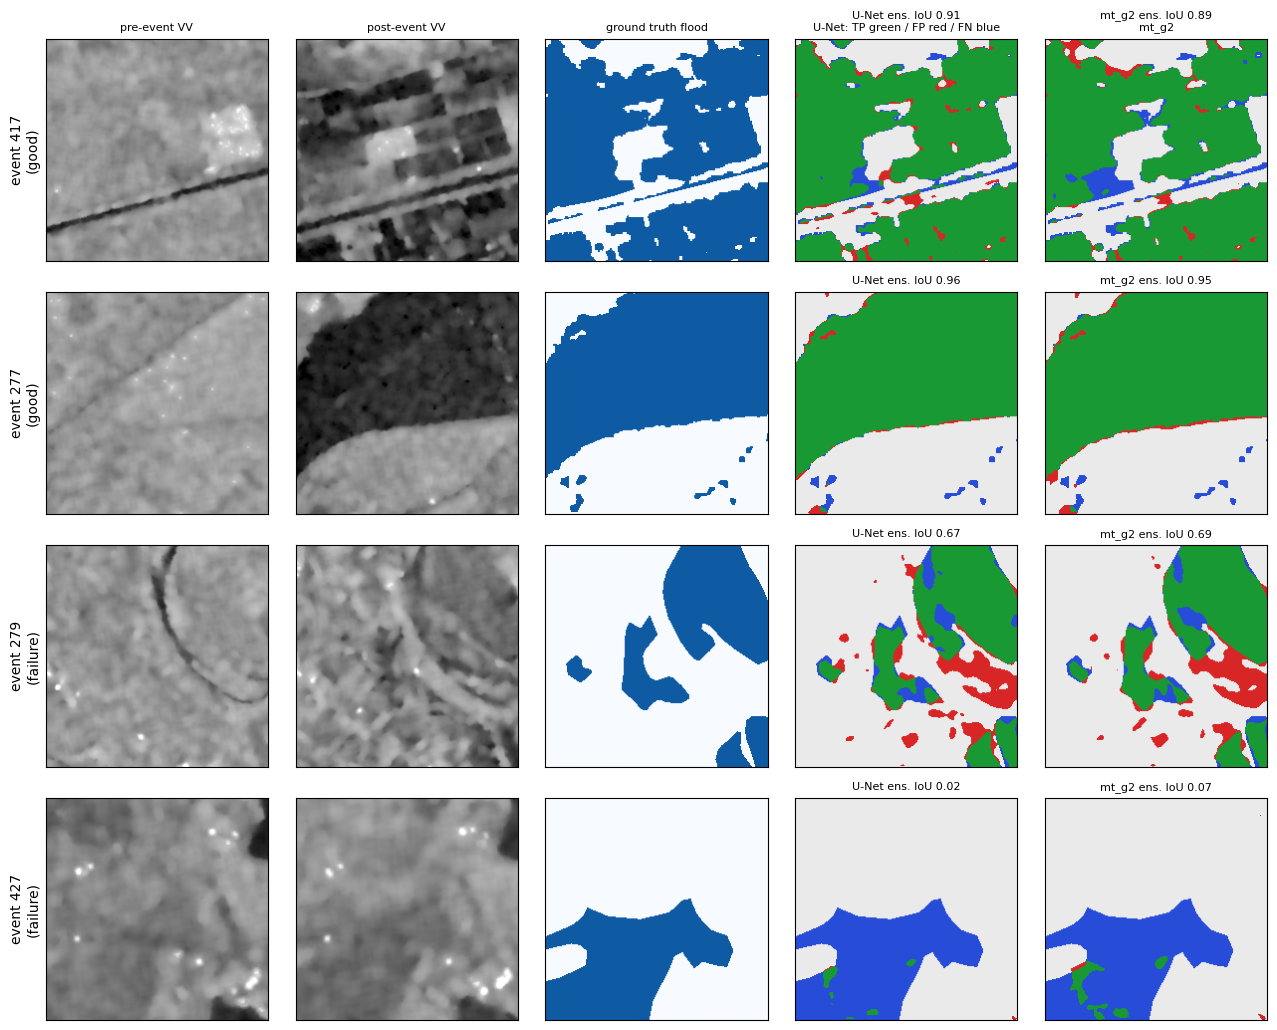

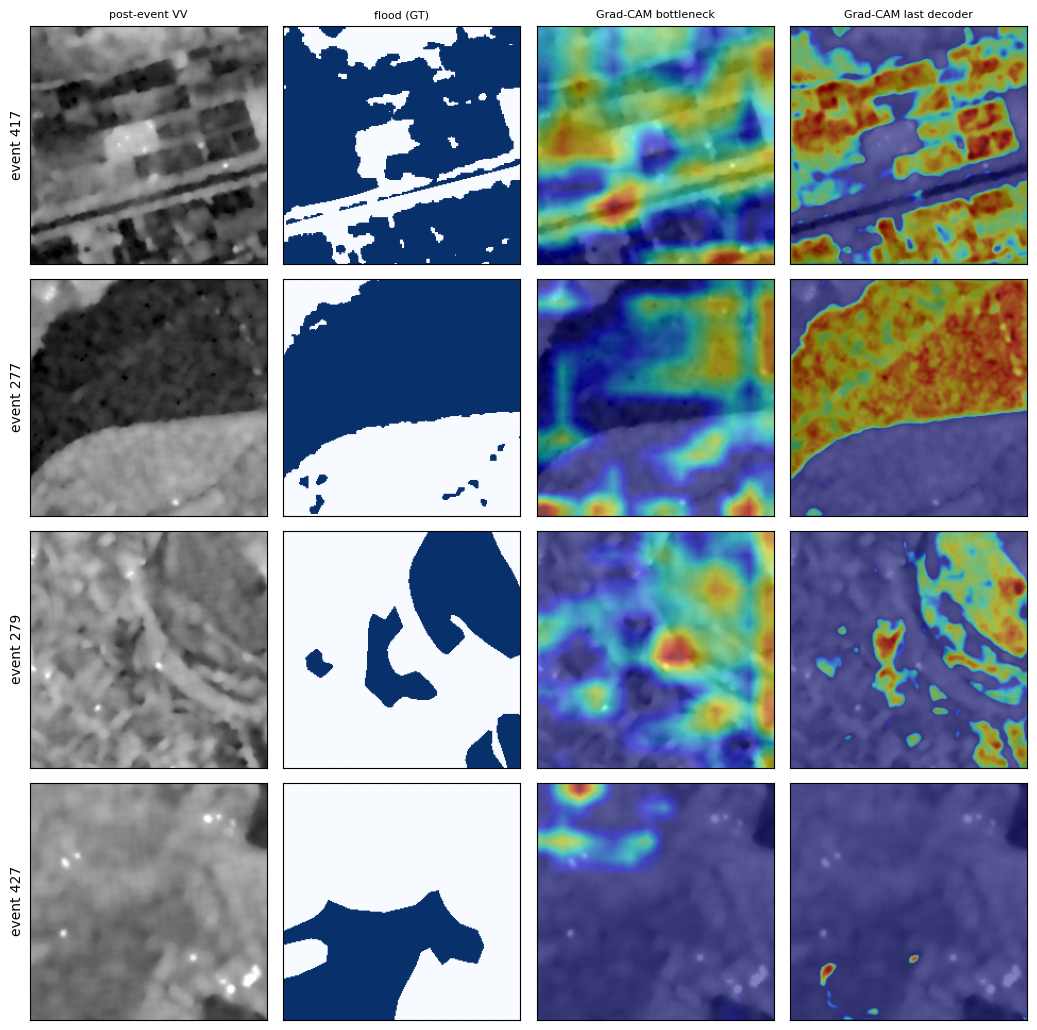

gradient x input, share per input channel and patch:


,pre VV,pre VH,post VV,post VH
event,,,,
417,0.108,0.126,0.318,0.447
277,0.079,0.103,0.383,0.435
279,0.106,0.151,0.314,0.429
427,0.162,0.111,0.510,0.217


,model,split,player,Shapley (IoU),permutation drop (IoU),IoU all
0,U-Net (pre1 + post),val,pre VV,0.0530,0.1085,0.6849
1,U-Net (pre1 + post),val,pre VH,0.0734,0.0994,0.6849
2,U-Net (pre1 + post),val,post VV,0.4691,0.5440,0.6849
3,U-Net (pre1 + post),val,post VH,0.0893,0.2327,0.6849
4,mt_g2,val,pre-event 1,0.0560,NaN,0.6738
5,mt_g2,val,pre-event 2,0.0457,NaN,0.6738
6,mt_g2,val,post-event,0.5722,NaN,0.6738
7,U-Net (pre1 + post),test_01,pre VV,0.0555,0.1050,0.5906
8,U-Net (pre1 + post),test_01,pre VH,0.0442,0.0663,0.5906
9,U-Net (pre1 + post),test_01,post VV,0.4547,0.5122,0.5906


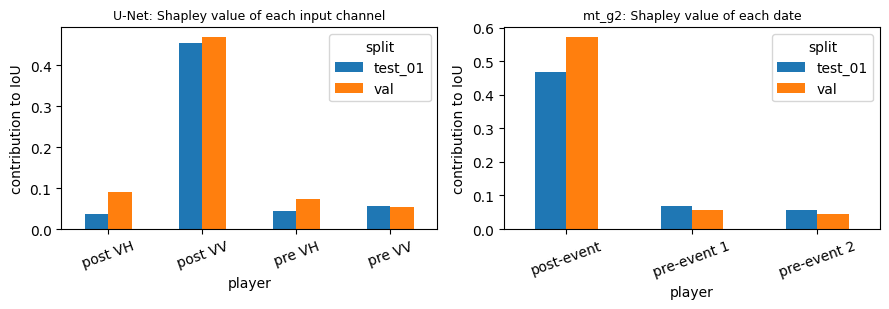

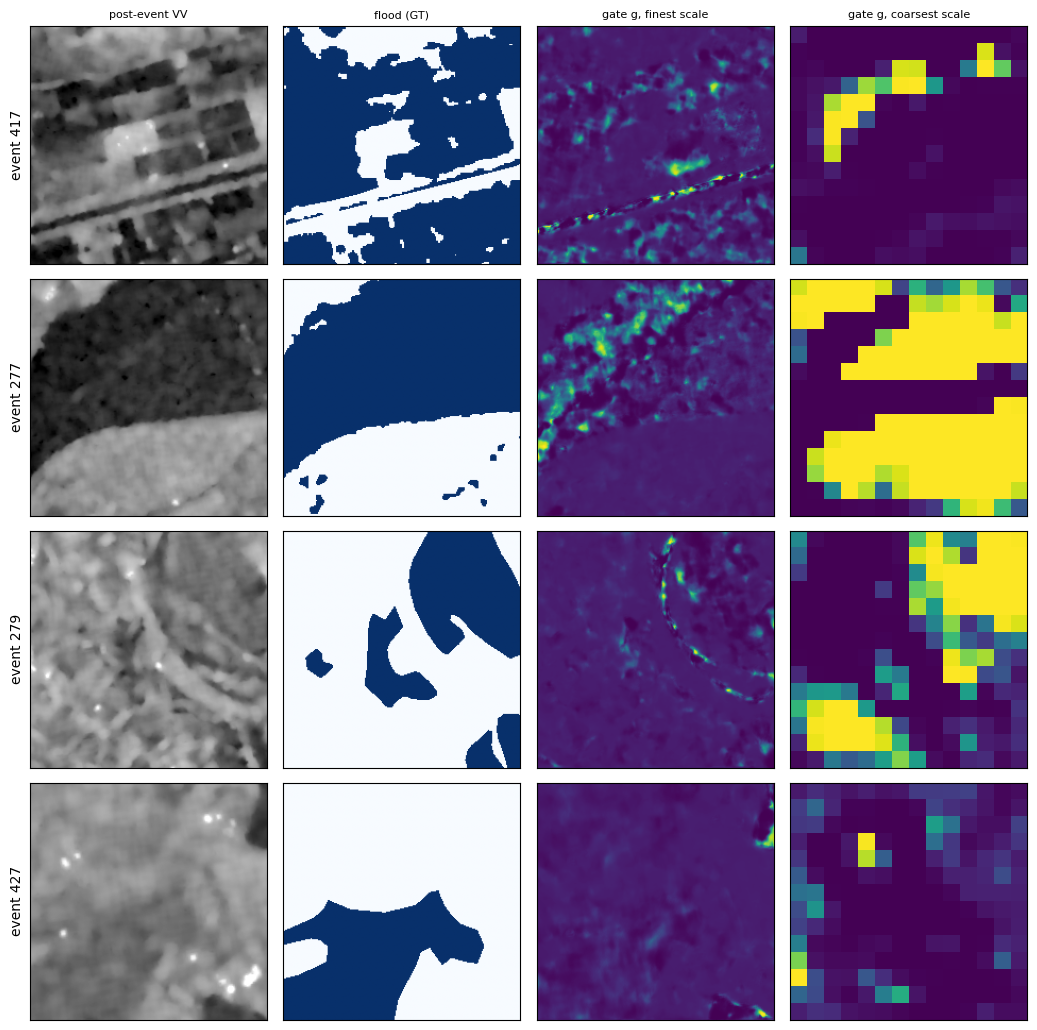

mean gate g (0 = only pre1) inside / outside flood:


,gate finest (mean),gate finest in flood,gate finest outside flood,gate coarsest in flood,gate coarsest outside flood
event,,,,,
417,0.110,0.116,0.094,0.134,0.000
277,0.118,0.144,0.079,0.462,0.809
279,0.087,0.088,0.087,0.583,0.256
427,0.081,0.081,0.080,0.049,0.059


Done. Send me: the printed tables of B1, D1, D2, X1 and the files in results/ (sota_baselines_*.csv, sen1floods11_eda.csv, cross_dataset_*.csv, input_importance.csv, gate_maps_stats.csv, gradient_x_input_share.csv); and look at figures/qualitative_maps.png, gradcam_examples.png, channel_importance.png, gate_maps.png.


In [13]:

# %% ---- X1: explainability - qualitative maps, Grad-CAM, exact Shapley / permutation importance, gate maps
# ============================================================
# (a) qualitative prediction maps for good and failure events (frozen models, ensembles; fresh-test patches; descriptive)
# (b) Grad-CAM of the plain U-Net (seed 0), bottleneck and last decoder block, target = flood evidence over ground-truth flood pixels
# (c) which input channel matters: exact Shapley values over the 4 input channels (16 coalitions, absent channel = training mean) and
#     permutation importance, for the plain U-Net ensemble; date-level Shapley (pre1 / pre2 / post) for mt_g2  - on random samples of
#     validation and fresh-test patches (pixel-level IoU, no minimum-area rule)
# (d) spatial gate maps of mt_g2: where does the model use the older pre-event image?
# Outputs: figures/qualitative_maps.png, gradcam_examples.png, channel_importance.png, gate_maps.png and results/*.csv.
# ============================================================
import matplotlib.pyplot as plt, copy
GOOD, FAIL = [417, 277], [279, 427]
BASEC, MTC = CFGS["base"], CFGS["mt_g2"]
base_models = load_group("base")[0][2]; mt_models = load_group("mt_g2")[0][2]
mk_ds = lambda cfg, split: (FloodDatasetMT if cfg.get("gap") else FloodDatasetV2)(split, cfg)
 
def find_patch(event, q=0.9):
    for sp in ("test_01", "test_02"):
        m = pd.read_csv(PROC / f"manifest_{sp}.csv", dtype={"sample_id": str, "shard": str}); m = m[m.split == sp].sort_values("row").reset_index(drop=True)
        sub = m[(m.actid.astype(int) == event) & (m.pflood > 0)]
        if len(sub): return sp, int(sub.sort_values("pflood").iloc[int(q * (len(sub) - 1))].name)          # patch with a visible, typical flood
    return None
sel = [(e, *find_patch(e)) for e in GOOD + FAIL if find_patch(e)]
print("selected patches (event, split, row):", sel)
 
@torch.no_grad()
def ens_prob(models, x): return torch.stack([torch.sigmoid(m(x.to(DEVICE)).float()) for m in models]).mean(0).cpu().numpy()
 
# ---- (a) qualitative maps
fig, ax = plt.subplots(len(sel), 5, figsize=(13, 2.6 * len(sel)))
ax = np.atleast_2d(ax)
for r, (e, sp, i) in enumerate(sel):
    dsb, dsm = mk_ds(BASEC, sp), mk_ds(MTC, sp); xb, t, v = dsb[i]; xm = dsm[i][0]
    Xr = np.load(PROC / f"X_{sp}.npy", mmap_mode="r"); raw = _db(Xr, i, [0, 4]); t, v = t.numpy() > 0, v.numpy()
    pb, pm = ens_prob(base_models, xb[None])[0] > .5, ens_prob(mt_models, xm[None])[0] > .5
    def overlay(p):
        im = np.ones(p.shape + (3,)) * 0.92; im[p & t & v] = (0.1, 0.6, 0.2); im[p & ~t & v] = (0.85, 0.15, 0.15); im[~p & t & v] = (0.15, 0.3, 0.85); im[~v] = (0.6, 0.6, 0.6); return im
    iou = lambda p: (p & t & v).sum() / max((p & v).sum() + (t & v).sum() - (p & t & v).sum(), 1)
    ax[r, 0].imshow(raw[0], cmap="gray", vmin=-25, vmax=0); ax[r, 1].imshow(raw[1], cmap="gray", vmin=-25, vmax=0); ax[r, 2].imshow(np.where(v, t, .5), cmap="Blues", vmin=0, vmax=1.2)
    ax[r, 3].imshow(overlay(pb)); ax[r, 4].imshow(overlay(pm))
    ax[r, 0].set_ylabel(f"event {e}\n({'good' if e in GOOD else 'failure'})")
    ax[r, 3].set_title(f"U-Net ens. IoU {iou(pb):.2f}", fontsize=8); ax[r, 4].set_title(f"mt_g2 ens. IoU {iou(pm):.2f}", fontsize=8)
for a, t_ in zip(ax[0], ["pre-event VV", "post-event VV", "ground truth flood", "U-Net: TP green / FP red / FN blue", "mt_g2"]): a.set_title(t_ if a is not ax[0, 3] and a is not ax[0, 4] else a.get_title() + "\n" + t_, fontsize=8)
for a in ax.ravel(): a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.savefig(ROOT / "figures" / "qualitative_maps.png", dpi=130); plt.show()
 
# ---- (b) Grad-CAM (plain U-Net seed 0)
class GradCAM:
    def __init__(self, model, layer):
        self.m, self.act = model, None
        def hook(mod, i, o):
            self.act = o
            if o.requires_grad: o.retain_grad()
        layer.register_forward_hook(hook)                                              # hook returns None: output unchanged
    def __call__(self, x, score_mask):
        self.m.zero_grad(); xin = x[None].clone().to(DEVICE).float().requires_grad_(True); lg = self.m(xin)[0]
        s = (lg * score_mask.to(DEVICE)).sum() / score_mask.sum().clamp(min=1); s.backward()
        w = self.act.grad.mean((2, 3), keepdim=True); cam = F.relu((w * self.act).sum(1))[0].detach().cpu()
        cam = F.interpolate(cam[None, None], size=x.shape[-2:], mode="bilinear", align_corners=False)[0, 0].numpy()
        return cam / (cam.max() + 1e-8), xin.grad[0].detach().cpu().numpy()
m0 = copy.deepcopy(base_models[0]).float().eval()
for p_ in m0.parameters(): p_.requires_grad_(True)
gc_b, gc_d = GradCAM(m0, m0.enc[4]), GradCAM(m0, m0.dec[0])
fig, ax = plt.subplots(len(sel), 4, figsize=(10.5, 2.6 * len(sel))); ax = np.atleast_2d(ax); sal_rows = []
for r, (e, sp, i) in enumerate(sel):
    x, t, v = mk_ds(BASEC, sp)[i]; mask = (t > 0) & v
    if mask.sum() == 0: continue
    Xr = np.load(PROC / f"X_{sp}.npy", mmap_mode="r"); raw = _db(Xr, i, [0, 4])
    cam_b, g = gc_b(x, mask.float()); cam_d, _ = gc_d(x, mask.float())
    ax[r, 0].imshow(raw[1], cmap="gray", vmin=-25, vmax=0); ax[r, 1].imshow(mask, cmap="Blues"); ax[r, 2].imshow(raw[1], cmap="gray", vmin=-25, vmax=0); ax[r, 2].imshow(cam_b, cmap="jet", alpha=.5)
    ax[r, 3].imshow(raw[1], cmap="gray", vmin=-25, vmax=0); ax[r, 3].imshow(cam_d, cmap="jet", alpha=.5); ax[r, 0].set_ylabel(f"event {e}")
    sal_rows.append({"event": e, **{n: float((np.abs(g[c]) * np.abs(x[c].numpy())).mean()) for c, n in enumerate(["pre VV", "pre VH", "post VV", "post VH"])}})   # gradient x input
for a, t_ in zip(ax[0], ["post-event VV", "flood (GT)", "Grad-CAM bottleneck", "Grad-CAM last decoder"]): a.set_title(t_, fontsize=8)
for a in ax.ravel(): a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.savefig(ROOT / "figures" / "gradcam_examples.png", dpi=130); plt.show()
SAL = pd.DataFrame(sal_rows).set_index("event"); SAL = SAL.div(SAL.sum(1), axis=0); print("gradient x input, share per input channel and patch:"); display(SAL.round(3)); SAL.to_csv(ROOT / "results" / "gradient_x_input_share.csv")
del m0, gc_b, gc_d; gc.collect(); torch.cuda.empty_cache()
 
# ---- (c) exact Shapley values and permutation importance of the inputs
def sample_tensors(cfg, split, n=1200, seed=0):
    ds = mk_ds(cfg, split); keep = np.where(~ds.meta.actid.astype(int).isin(trainval_events))[0] if split.startswith("test") else np.arange(len(ds))
    ids = np.sort(np.random.default_rng(seed).choice(keep, min(n, len(keep)), replace=False)); X, T, V = [], [], []
    for i in ids: x, t, v = ds[int(i)]; X.append(x.half()); T.append(t.bool()); V.append(v.bool())
    return torch.stack(X), torch.stack(T), torch.stack(V)
 
@torch.no_grad()
def value(models, X, T, V, absent=(), shuffle=(), bs=32):
    tp = fp = fn = 0
    for a in range(0, len(X), bs):
        x = X[a:a + bs].float().clone()
        for c in absent: x[:, c] = 0.0                                                # standardised 0 = training-mean backscatter
        for c in shuffle: x[:, c] = x[:, c][torch.randperm(len(x), generator=torch.Generator().manual_seed(a))]
        p = ens_prob(models, x) > .5; t, v = T[a:a + bs].numpy(), V[a:a + bs].numpy()
        tp += int((p & t & v).sum()); fp += int((p & ~t & v).sum()); fn += int((~p & t & v).sum())
    return tp / max(tp + fp + fn, 1)
 
from itertools import combinations
from math import factorial
def shapley(models, X, T, V, groups):
    n = len(groups); v = {}
    for k in range(n + 1):
        for S in combinations(range(n), k):
            v[S] = value(models, X, T, V, absent=[c for j in range(n) if j not in S for c in groups[j]])
    phi = []
    for i in range(n):
        s = 0.0
        for k in range(n):
            for S in combinations([j for j in range(n) if j != i], k):
                s += factorial(k) * factorial(n - k - 1) / factorial(n) * (v[tuple(sorted(S + (i,)))] - v[S])
        phi.append(s)
    return phi, v[tuple(range(n))], v[()]
 
imp_rows = []
for split in ("val", "test"):
    sp = "val" if split == "val" else "test_01"
    Xb, Tb, Vb = sample_tensors(BASEC, sp); names = ["pre VV", "pre VH", "post VV", "post VH"]
    phi, full, empty = shapley(base_models, Xb, Tb, Vb, [[0], [1], [2], [3]])
    perm = [full - value(base_models, Xb, Tb, Vb, shuffle=[c]) for c in range(4)]
    for n_, p_, q_ in zip(names, phi, perm): imp_rows.append({"model": "U-Net (pre1 + post)", "split": sp, "player": n_, "Shapley (IoU)": p_, "permutation drop (IoU)": q_, "IoU all": full})
    del Xb, Tb, Vb
    Xm, Tm, Vm = sample_tensors(MTC, sp)
    phi, full, empty = shapley(mt_models, Xm, Tm, Vm, [[0, 1], [2, 3], [4, 5]])
    for n_, p_ in zip(["pre-event 1", "pre-event 2", "post-event"], phi): imp_rows.append({"model": "mt_g2", "split": sp, "player": n_, "Shapley (IoU)": p_, "permutation drop (IoU)": np.nan, "IoU all": full})
    del Xm, Tm, Vm; gc.collect(); torch.cuda.empty_cache()
IMP = pd.DataFrame(imp_rows); IMP.to_csv(ROOT / "results" / "input_importance.csv", index=False); display(IMP.round(4))
fig, ax = plt.subplots(1, 2, figsize=(9, 3.2))
for a, (mdl, ttl) in zip(ax, [("U-Net (pre1 + post)", "U-Net: Shapley value of each input channel"), ("mt_g2", "mt_g2: Shapley value of each date")]):
    d = IMP[IMP.model == mdl].pivot(index="player", columns="split", values="Shapley (IoU)"); d.plot.bar(ax=a, rot=20); a.set_title(ttl, fontsize=9); a.set_ylabel("contribution to IoU")
plt.tight_layout(); plt.savefig(ROOT / "figures" / "channel_importance.png", dpi=130); plt.show()
 
# ---- (d) gate maps of mt_g2
def _fwd_with_map(self, f, gap=None, drop=None):
    pre1, pre2, post = f[:, 0], f[:, 1], f[:, 2]
    q = self.q(post); sc = math.sqrt(q.shape[1])
    s1, s2 = (self.k(pre1) * q).sum(1, keepdim=True) / sc, (self.k(pre2) * q).sum(1, keepdim=True) / sc
    l = self.bias + (s2 - s1)
    if self.gap is not None: l = l + self.gap(gap.to(l.dtype))[:, :, None, None]
    if drop is not None:
        l = torch.where((drop == 2)[:, None, None, None], torch.full_like(l, -20.0), l); l = torch.where((drop == 1)[:, None, None, None], torch.full_like(l, 20.0), l)
    g = torch.sigmoid(l); self.last_g = g.mean((1, 2, 3)).detach().float(); self.last_gmap = g.detach().float()
    ref = pre1 + g * (pre2 - pre1); return self.mix(torch.cat([post, post - ref, ref], 1))
GatedFusion.forward = _fwd_with_map
gm = copy.deepcopy(mt_models[0]).eval(); fig, ax = plt.subplots(len(sel), 4, figsize=(10.5, 2.6 * len(sel))); ax = np.atleast_2d(ax); grows = []
for r, (e, sp, i) in enumerate(sel):
    x, t, v = mk_ds(MTC, sp)[i]
    with torch.no_grad(): gm(x[None].to(DEVICE))
    Xr = np.load(PROC / f"X_{sp}.npy", mmap_mode="r"); raw = _db(Xr, i, [0, 4]); t = t.numpy() > 0
    g0, g4 = gm.fuse[0].last_gmap[0, 0].cpu().numpy(), gm.fuse[4].last_gmap[0, 0].cpu().numpy()
    ax[r, 0].imshow(raw[1], cmap="gray", vmin=-25, vmax=0); ax[r, 1].imshow(t, cmap="Blues"); im = ax[r, 2].imshow(g0, cmap="viridis", vmin=0, vmax=max(g0.max(), .2)); ax[r, 3].imshow(g4, cmap="viridis", vmin=0, vmax=max(g4.max(), .2))
    t4 = F.adaptive_avg_pool2d(torch.tensor(t[None, None].astype(np.float32)), g4.shape).numpy()[0, 0] > .5
    grows.append({"event": e, "gate finest (mean)": g0.mean(), "gate finest in flood": g0[t].mean() if t.any() else np.nan, "gate finest outside flood": g0[~t].mean(),
                  "gate coarsest in flood": g4[t4].mean() if t4.any() else np.nan, "gate coarsest outside flood": g4[~t4].mean()})
    ax[r, 0].set_ylabel(f"event {e}")
for a, t_ in zip(ax[0], ["post-event VV", "flood (GT)", "gate g, finest scale", "gate g, coarsest scale"]): a.set_title(t_, fontsize=8)
for a in ax.ravel(): a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.savefig(ROOT / "figures" / "gate_maps.png", dpi=130); plt.show()
GT_ = pd.DataFrame(grows).set_index("event"); print("mean gate g (0 = only pre1) inside / outside flood:"); display(GT_.round(3)); GT_.to_csv(ROOT / "results" / "gate_maps_stats.csv")
print("Done. Send me: the printed tables of B1, D1, D2, X1 and the files in results/ (sota_baselines_*.csv, sen1floods11_eda.csv, cross_dataset_*.csv, input_importance.csv, gate_maps_stats.csv, gradient_x_input_share.csv); "
      "and look at figures/qualitative_maps.png, gradcam_examples.png, channel_importance.png, gate_maps.png.")
 